In [ ]:
import gc
import joblib

import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

import numpy as np
import pandas as pd
import seaborn as sns
import shap
import lime
from lime.lime_tabular import LimeTabularExplainer

import optuna
import optuna.visualization as vis
from optuna.integration import XGBoostPruningCallback

from scipy.cluster import hierarchy
from scipy.spatial.distance import squareform
from scipy.stats import spearmanr

from sklearn.compose import ColumnTransformer
from sklearn.inspection import PartialDependenceDisplay, permutation_importance
from sklearn.metrics import mean_squared_error, r2_score, root_mean_squared_error, make_scorer
from sklearn.model_selection import KFold, TimeSeriesSplit, cross_val_score, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MultiLabelBinarizer, OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.neural_network import MLPRegressor

import xgboost as xgb
from xgboost import XGBRegressor, plot_importance
from scipy.stats import spearmanr

<h2>Read-in Data</h2>

In [27]:
campd_type_dict = {
    'State': 'string',
    'Facility Name': 'string',
    'Facility ID': 'Int32',
    'Unit ID': 'string',
    'Hour': 'Int8',
    'Operating Time': 'float32',
    'Gross Load (MW)': 'float32',
    'Steam Load (1000 lb/hr)': 'float32',
    'SO2 Mass (lbs)': 'float64',
    'SO2 Mass Measure Indicator': 'string',
    'SO2 Rate (lbs/mmBtu)': 'float32',
    'SO2 Rate Measure Indicator': 'string',
    'CO2 Mass (short tons)': 'float32',
    'CO2 Mass Measure Indicator': 'string',
    'CO2 Rate (short tons/mmBtu)': 'float32',
    'CO2 Rate Measure Indicator': 'string',
    'NOx Mass (lbs)': 'float32',
    'NOx Mass Measure Indicator': 'string',
    'NOx Rate (lbs/mmBtu)': 'float32',
    'NOx Rate Measure Indicator': 'string',
    'Heat Input (mmBtu)': 'float64',
    'Heat Input Measure Indicator': 'string',
    'Primary Fuel Type': 'string',
    'Secondary Fuel Type': 'string',
    'Unit Type': 'string',
    'SO2 Controls': 'string',
    'NOx Controls': 'string',
    'Program Code': 'string',
    'Year': 'int16',
    'Source Category': 'string',
    'Latitude': 'float32',
    'Longitude': 'float32',
    'SO2 Phase': 'string',
    'NOx Phase': 'string',
    'Operating Status': 'string',
    'Max Hourly HI Rate (mmBtu/hr)': 'float32',
    'Associated Generators & Nameplate Capacity (MWe)': 'string',
    'Nameplate Capacity (MWe)': 'float32',
    'Month': 'Int8',
    'hourly_capacity_factor': 'float32',
    'hourly_ramping_factor': 'float32',
    'Nameplate Capacity (MW) - EIA': 'float32',
    'Summer Capacity (MW)': 'float32',
    'Winter Capacity (MW)': 'float32',
    'Minimum Load (MW)': 'float32',
    'Operating Year_min': 'float32',
    'Operating Year_max': 'float32',
    'Operating Year_mean': 'float32',
    'Planned Retirement Year': 'Int16',
    'unit_age_min': 'Int8',
    'unit_age_max': 'Int8',
    'unit_age_mean': 'float32',
    'Day': 'float32',
    'Temperature (F)': 'float32'
}

In [ ]:
# Combine both operating and non-operating data into a full dataset for consistent time series analysis

# Data with operations
campd_ny_operating = pd.read_csv("NY/Hourly/Concatted File/ny_2019_2024_complete_cleaned.csv", dtype=campd_type_dict, date_format=["Date"])
# Data without operations
campd_ny_nonoperating = pd.read_csv("NY/Hourly/Concatted File/ny_2019_2024_complete_cleaned_NonOperating.csv", dtype=campd_type_dict, date_format=["Date"])

campd_ny = pd.concat([campd_ny_operating, campd_ny_nonoperating])
del campd_ny_nonoperating
del campd_ny_operating
gc.collect()

# create full datetime column (date + hour)
campd_ny["datetime"] = pd.to_datetime(campd_ny["Date"].astype(str) + ' ' + campd_ny["Hour"].astype(str).str.zfill(2) + ":00:00")

campd_ny.to_csv("NY/Hourly/Concatted File/ny_2019_2024_complete_cleaned_Full.csv", index=False)

In [3]:
campd_ny = pd.read_csv("NY/Hourly/Concatted File/ny_2019_2024_complete_cleaned_Full.csv", dtype=campd_type_dict)
campd_ny["Date"] = pd.to_datetime(campd_ny["Date"])
campd_ny["datetime"] = pd.to_datetime(campd_ny["datetime"])

<h2>Preprocessing Methods</h2>

In [ ]:
# manually create lag columns
def create_lag_features_per_group(group, emission_type):
    group["lag_1_hour"] = group[emission_type].shift(1)  # 1 hour lag
    group["lag_2_hours"] = group[emission_type].shift(2)  # 2 hours lag
    group["lag_1_day"] = group[emission_type].shift(24)  # 1 day lag (24 hours)
    group["lag_2_days"] = group[emission_type].shift(48)  # 2 days lag (48 hours)
    group["lag_1_week"] = group[emission_type].shift(24 * 7)  # 1 week lag (168 hours)
    group["lag_1_month"] = group[emission_type].shift(24 * 30)  # ~1 month lag (720 hours)
    group["lag_1_year"] = group[emission_type].shift(24 * 365)  # ~1 year lag (8760 hours)
    return group

def preprocess_lag_features(df, previous_year_df, emission_type):
    cutoff_year = df["Year"].min()

    # add the previous year temporarily to get lags for the first year
    df = pd.concat([df, previous_year_df])

    df = df.set_index("datetime")

    df = df.sort_index()
    df = df.sort_values(by=["Facility ID", "Unit ID", "datetime"])

    # group by
    df = df.groupby(["Facility ID", "Unit ID"], group_keys=False).apply(
    create_lag_features_per_group, emission_type=emission_type)

    df = df.reset_index()

    # filter out the previous year again
    df = df[df["Year"] >= cutoff_year]

    # ensure to add datetime back as normal column
    df["datetime"] = pd.to_datetime(df["Date"].astype(str) + ' ' + df["Hour"].astype(str).str.zfill(2) + ":00:00")


    return df


In [ ]:
# manually one-hot encode NOx Controls
def split_outside_parentheses(s):
    parts = []
    current = []
    depth = 0  # track parentheses depth

    for char in s:
        if char == '(':
            depth += 1
        elif char == ')':
            depth = max(depth - 1, 0)
        
        # Split on ',' or '|' only if outside parentheses
        if (char == ',' or char == '|') and depth == 0:
            part = ''.join(current).strip()
            if part:
                parts.append(part)
            current = []
        else:
            current.append(char)
    
    # Append last part
    part = ''.join(current).strip()
    if part:
        parts.append(part)
    
    return parts

# function for one-hot encoding NOx Controls
def preprocess_nox_controls(df):
    df = df.copy()
    df = df.dropna(subset=['NOx Controls'])
    
    # apply custom splitting
    control_lists = df['NOx Controls'].apply(split_outside_parentheses)
    
    # One-hot encode controls
    mlb = MultiLabelBinarizer()
    control_matrix = mlb.fit_transform(control_lists)
    
    # create a df from the binary matrix
    controls_df = pd.DataFrame(control_matrix, columns=mlb.classes_, index=df.index)
    
    df = df.drop(columns=['NOx Controls'])
    df = pd.concat([df, controls_df], axis=1)
    
    return df, mlb.classes_  # return control column names for later use

# campd_ny, ny_control_cols = preprocess_nox_controls(campd_ny)
# ny_control_cols

In [ ]:
# manually one-hot encode Program Codes
def preprocess_program_codes(df):

    # split the strings into lists
    program_lists = df['Program Code'].str.split(', ')

    mlb = MultiLabelBinarizer()
    program_dummies = pd.DataFrame(mlb.fit_transform(program_lists), 
                                columns=mlb.classes_, 
                                index=df.index)

    # concatenate with original DataFrame or add to your features
    df = pd.concat([df, program_dummies], axis=1)

    return df, mlb.classes_


# campd_ny, ny_code_cols = preprocess_program_codes(campd_ny)
# ny_code_cols

<h2>Regression Models</h2>

<h3>Linear Regression</h3>

In [66]:
campd_df = pd.read_csv("NY/Hourly/Concatted File/Modeling/XGB/NOx/ny_2019_2024_complete_cleaned_Full_manually_encoded_downsampled_only_measured", dtype=campd_type_dict)

<h4>No Imputation, remove nan cols/rows</h4>

In [ ]:
navals = campd_df[num_features + encoded_cat_features + unencoded_cat_features].isna().sum() / len(campd_df) * 100
navals[navals > 0]

# we test two data strategies, 
# 1 imputing with median 
# removing nan cols with excessive number of nan vals otherwise removing respective nan rows

Gross Load (MW)              4.674485
Latitude                    11.055066
Longitude                   11.055066
Nameplate Capacity (MWe)    11.055066
hourly_capacity_factor       5.678980
hourly_ramping_factor       15.730771
Summer Capacity (MW)        59.033506
Winter Capacity (MW)        59.033506
Minimum Load (MW)           59.033506
Temperature (F)              1.723858
dtype: float64

In [ ]:
nan_cols = [
    'Gross Load (MW)',
    'Latitude',
    'Longitude',
    'Nameplate Capacity (MWe)',
    'hourly_capacity_factor',
    'hourly_ramping_factor',

    # we manually remove these cols altogether
    # 'Summer Capacity (MW)',
    # 'Winter Capacity (MW)',
    # 'Minimum Load (MW)',

    'Temperature (F)'
]

campd_df_cleaned = campd_df.dropna(subset=nan_cols)

print(f"Original shape: {campd_df.shape}, New shape: {campd_df_cleaned.shape}")
print(f"Change in total rows: {campd_df_cleaned.shape[0] - campd_df.shape[0]}")

Original shape: (3197828, 95), New shape: (2666036, 95)
Change in total rows: -531792


In [ ]:
df_control_cols = ['Ammonia Injection', 'Combustion Modification/Fuel Reburning',
       'Dry Low NOx Burners',
       'Low NOx Burner Technology (Dry Bottom only)',
       'Low NOx Burner Technology w/ Closed-coupled OFA',
       'Low NOx Burner Technology w/ Closed-coupled/Separated OFA',
       'Low NOx Burner Technology w/ Overfire Air',
       'Low NOx Burner Technology w/ Separated OFA', 'Nothing', 'Other',
       'Overfire Air', 'Selective Catalytic Reduction',
       'Selective Non-catalytic Reduction', 'Steam Injection',
       'Water Injection', 'Water Injection (Began Jul 01, 2022)']
df_code_cols = ['ARP', 'CSNOX', 'CSOSG2', 'CSOSG2E', 'CSOSG3', 'CSSO2G1', 'MATS',
       'Missing', 'NSPS4T', 'RGGI', 'SIPNOX']
cyclical_cols = ['Hour_sin', 'Hour_cos', 'Day_sin',
       'Day_cos', 'Month_sin', 'Month_cos']
lag_cols = [
    "lag_1_hour",
    "lag_2_hours",
    "lag_1_day",
    "lag_2_days",
    "lag_1_week",
    "lag_1_month",
    "lag_1_year"
       ]

# features
num_features = ['Gross Load (MW)', 
                    'Heat Input (mmBtu)',
                'Latitude', 'Longitude', 
                'Nameplate Capacity (MWe)', 'hourly_capacity_factor',
                'hourly_ramping_factor',
                #'Summer Capacity (MW)',
                #'Winter Capacity (MW)', 
                #'Minimum Load (MW)', 
                 'Year',
                 'Temperature (F)'
                 ]

unencoded_cat_features = ['Month', 'Hour', 'Day', 
                    'Source Category', 
                    'NOx Phase', 'Unit Type', 'Primary Fuel Type', 
                    'Secondary Fuel Type'] 

encoded_cat_features = list(df_control_cols) + list(df_code_cols) #+ lag_cols #+ cyclical_cols # for passthrough of the manually one-hot encoded cols

target_variable = "NOx Mass (lbs)"

# sort to put it in appropriate time series format
campd_df_cleaned = campd_df_cleaned.sort_values(by=["datetime","Facility ID", "Unit ID"])

# split manually by year 2024
X_train = campd_df_cleaned[(campd_df_cleaned["Year"] < 2024) & (campd_df_cleaned["NOx Mass (lbs)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
y_train = campd_df_cleaned[(campd_df_cleaned["Year"] < 2024) & (campd_df_cleaned["NOx Mass (lbs)"].notna())][target_variable]  
X_test = campd_df_cleaned[(campd_df_cleaned["Year"] == 2024) & (campd_df_cleaned["NOx Mass (lbs)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
y_test = campd_df_cleaned[(campd_df_cleaned["Year"] ==  2024) & (campd_df_cleaned["NOx Mass (lbs)"].notna())][target_variable]

preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), unencoded_cat_features), 
        ('num', StandardScaler(), num_features),
        ('encoded', 'passthrough', encoded_cat_features) 
    ]
)

preprocessor.set_output(transform='pandas') # transform pandas.NA values to normal nan

X_train = preprocessor.fit_transform(X_train)
X_test = preprocessor.transform(X_test)


R^2 Score: 0.7961
Mean Squared Error (MSE): 815.9755
Root Mean Squared Error (RMSE): 28.5653
Normalized RMSE (by std): 0.4512


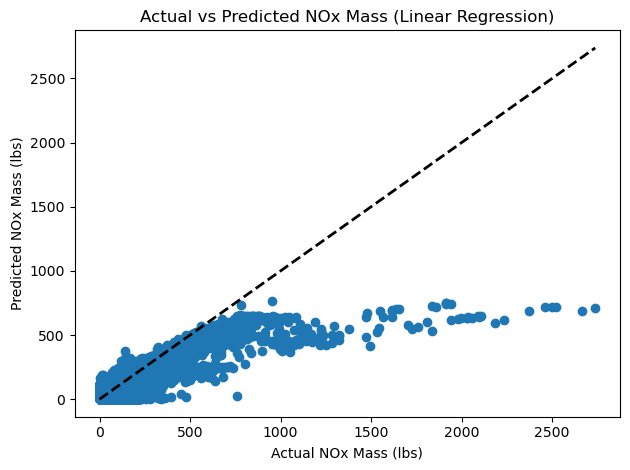

In [ ]:
# default model (no lags, no unmeasured, with temps)

lr_model = LinearRegression()
lr_model.fit(X_train, y_train)

y_pred = lr_model.predict(X_test)

# Set negative predictions to 0
y_pred[y_pred < 0] = 0

print(f"R^2 Score: {r2_score(y_test, y_pred):.4f}")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test, y_pred):.4f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")
print(f"Normalized RMSE (by std): {np.sqrt(mean_squared_error(y_test, y_pred)) / np.std(y_test):.4f}")

plt.scatter(y_test, y_pred)
plt.xlabel("Actual NOx Mass (lbs)")
plt.ylabel("Predicted NOx Mass (lbs)")
plt.title("Actual vs Predicted NOx Mass (Linear Regression)")
plt.plot([min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], 'k--', lw=2)
plt.tight_layout()
plt.show()

# struggles massively with higher emissions (imbalanced data)

R^2 Score: 0.7961
Mean Squared Error (MSE): 815.9755
Root Mean Squared Error (RMSE): 28.5653
Normalized RMSE (by std): 0.4512


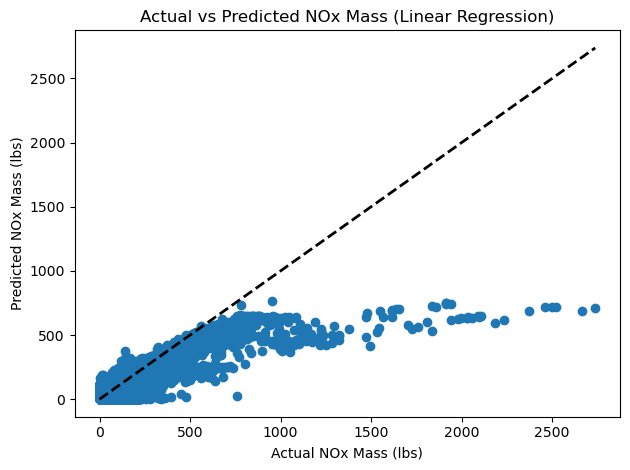

In [ ]:
# default model (no lags, no unmeasured, with temps)

lr_model = Ridge(alpha=0.1)
lr_model.fit(X_train, y_train)

# 
y_pred = lr_model.predict(X_test)

# Set negative predictions to 0
y_pred[y_pred < 0] = 0

print(f"R^2 Score: {r2_score(y_test, y_pred):.4f}")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test, y_pred):.4f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")
print(f"Normalized RMSE (by std): {np.sqrt(mean_squared_error(y_test, y_pred)) / np.std(y_test):.4f}")

plt.scatter(y_test, y_pred)
plt.xlabel("Actual NOx Mass (lbs)")
plt.ylabel("Predicted NOx Mass (lbs)")
plt.title("Actual vs Predicted NOx Mass (Linear Regression)")
plt.plot([min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], 'k--', lw=2)
plt.tight_layout()
plt.show()

# struggles massively with higher emissions (imbalanced data)

<h4>Median Imputation</h4>

In [ ]:
df_control_cols = ['Ammonia Injection', 'Combustion Modification/Fuel Reburning',
       'Dry Low NOx Burners',
       'Low NOx Burner Technology (Dry Bottom only)',
       'Low NOx Burner Technology w/ Closed-coupled OFA',
       'Low NOx Burner Technology w/ Closed-coupled/Separated OFA',
       'Low NOx Burner Technology w/ Overfire Air',
       'Low NOx Burner Technology w/ Separated OFA', 'Nothing', 'Other',
       'Overfire Air', 'Selective Catalytic Reduction',
       'Selective Non-catalytic Reduction', 'Steam Injection',
       'Water Injection', 'Water Injection (Began Jul 01, 2022)']
df_code_cols = ['ARP', 'CSNOX', 'CSOSG2', 'CSOSG2E', 'CSOSG3', 'CSSO2G1', 'MATS',
       'Missing', 'NSPS4T', 'RGGI', 'SIPNOX']
cyclical_cols = ['Hour_sin', 'Hour_cos', 'Day_sin',
       'Day_cos', 'Month_sin', 'Month_cos']
lag_cols = [
    "lag_1_hour",
    "lag_2_hours",
    "lag_1_day",
    "lag_2_days",
    "lag_1_week",
    "lag_1_month",
    "lag_1_year"
       ]

# features
num_features = ['Gross Load (MW)', 
                    'Heat Input (mmBtu)',
                'Latitude', 'Longitude', 
                'Nameplate Capacity (MWe)', 'hourly_capacity_factor',
                'hourly_ramping_factor',
                'Summer Capacity (MW)',
                'Winter Capacity (MW)', 
                'Minimum Load (MW)', 
                 'Year',
                 'Temperature (F)'
                 ]

unencoded_cat_features = ['Month', 'Hour', 'Day', 
                    'Source Category', 
                    'NOx Phase', 'Unit Type', 'Primary Fuel Type', 
                    'Secondary Fuel Type'] 

encoded_cat_features = list(df_control_cols) + list(df_code_cols) #+ lag_cols #+ cyclical_cols # for passthrough of the manually one-hot encoded cols

target_variable = "NOx Mass (lbs)"

# sort to put it in appropriate time series format
campd_df = campd_df.sort_values(by=["datetime","Facility ID", "Unit ID"])

# split manually by year 2024
X_train = campd_df[(campd_df["Year"] < 2024) & (campd_df["NOx Mass (lbs)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
y_train = campd_df[(campd_df["Year"] < 2024) & (campd_df["NOx Mass (lbs)"].notna())][target_variable]  
X_test = campd_df[(campd_df["Year"] == 2024) & (campd_df["NOx Mass (lbs)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
y_test = campd_df[(campd_df["Year"] ==  2024) & (campd_df["NOx Mass (lbs)"].notna())][target_variable]

# use simple imputer to fill nan values with median (necessary for linear regression)
num_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')), 
    ('scaler', StandardScaler())
])

preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), unencoded_cat_features), 
        ('num', num_pipeline, num_features),
        ('encoded', 'passthrough', encoded_cat_features) 
    ]
)

preprocessor.set_output(transform='pandas') # transform pandas.NA values to normal nan

X_train = preprocessor.fit_transform(X_train)
X_test = preprocessor.transform(X_test)


R^2 Score: 0.8260
Mean Squared Error (MSE): 640.4623
Root Mean Squared Error (RMSE): 25.3074
Normalized RMSE (by std): 0.4167


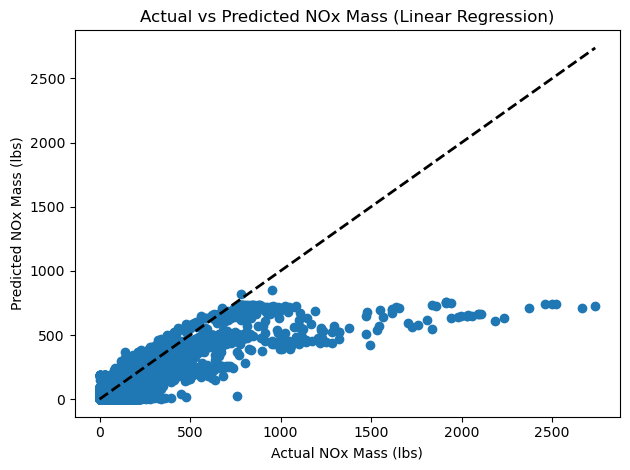

In [ ]:
# default model (no lags, no unmeasured, with temps)

lr_model = LinearRegression()
lr_model.fit(X_train, y_train)

# 
y_pred = lr_model.predict(X_test)

# Set negative predictions to 0
y_pred[y_pred < 0] = 0


print(f"R^2 Score: {r2_score(y_test, y_pred):.4f}")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test, y_pred):.4f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")
print(f"Normalized RMSE (by std): {np.sqrt(mean_squared_error(y_test, y_pred)) / np.std(y_test):.4f}")


plt.scatter(y_test, y_pred)
plt.xlabel("Actual NOx Mass (lbs)")
plt.ylabel("Predicted NOx Mass (lbs)")
plt.title("Actual vs Predicted NOx Mass (Linear Regression)")
plt.plot([min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], 'k--', lw=2)
plt.tight_layout()
plt.show()


R^2 Score: 0.8260
Mean Squared Error (MSE): 640.3991
Root Mean Squared Error (RMSE): 25.3061
Normalized RMSE (by std): 0.4167


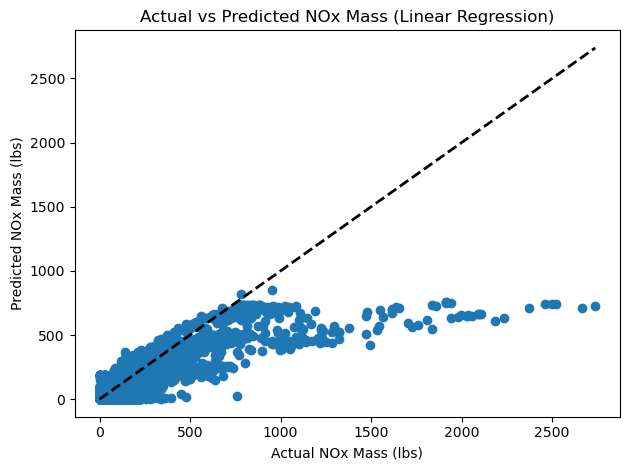

In [ ]:
# default model (no lags, no unmeasured, with temps)

# Ridge Regression (has no effect on performance here, but massively decreases magnitude of coefficients)

lr_model = Ridge(alpha=0.1)
lr_model.fit(X_train, y_train)

y_pred = lr_model.predict(X_test)

# Set negative predictions to 0
y_pred[y_pred < 0] = 0


print(f"R^2 Score: {r2_score(y_test, y_pred):.4f}")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test, y_pred):.4f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")
print(f"Normalized RMSE (by std): {np.sqrt(mean_squared_error(y_test, y_pred)) / np.std(y_test):.4f}")


plt.scatter(y_test, y_pred)
plt.xlabel("Actual NOx Mass (lbs)")
plt.ylabel("Predicted NOx Mass (lbs)")
plt.title("Actual vs Predicted NOx Mass (Linear Regression)")
plt.plot([min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], 'k--', lw=2)
plt.tight_layout()
plt.show()


<h4>With Lags</h4>

In [8]:
X_train = X_train.dropna(axis=0, how='any')  # drop rows with any NaN values
y_train = y_train[X_train.index]  # align y_train with X_train after dropping NaN rows

R^2 Score: 0.9426
Mean Squared Error (MSE): 211.2194
Root Mean Squared Error (RMSE): 14.5334
Normalized RMSE (by std): 0.2393


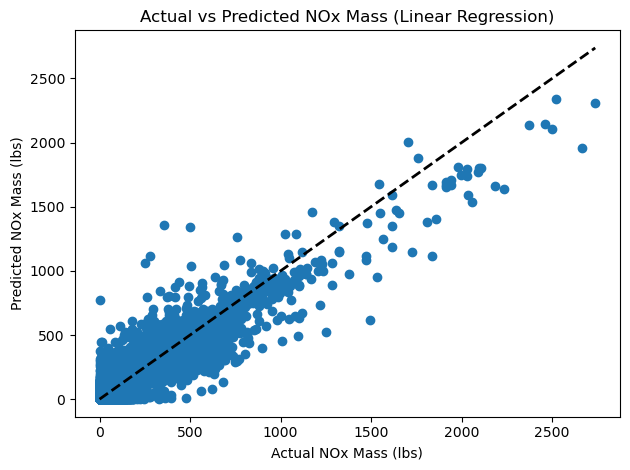

In [ ]:
# default model (with lags, no unmeasured, with temps)

lr_model = LinearRegression()
lr_model.fit(X_train, y_train)

# 
y_pred = lr_model.predict(X_test)

# Set negative predictions to 0
y_pred[y_pred < 0] = 0


print(f"R^2 Score: {r2_score(y_test, y_pred):.4f}")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test, y_pred):.4f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")
print(f"Normalized RMSE (by std): {np.sqrt(mean_squared_error(y_test, y_pred)) / np.std(y_test):.4f}")


plt.scatter(y_test, y_pred)
plt.xlabel("Actual NOx Mass (lbs)")
plt.ylabel("Predicted NOx Mass (lbs)")
plt.title("Actual vs Predicted NOx Mass (Linear Regression)")
plt.plot([min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], 'k--', lw=2)
plt.tight_layout()
plt.show()

# struggles massively with higher emissions (imbalanced data)

<h3>Random Forest</h3>

In [ ]:
# default params are:
# n_estimators=100, *, criterion='gini', max_depth=None, min_samples_split=2, 
# min_samples_leaf=1, min_weight_fraction_leaf=0.0, max_features='sqrt', 
# max_leaf_nodes=None, min_impurity_decrease=0.0, bootstrap=True, oob_score=False,
#  n_jobs=None, random_state=None, verbose=0, warm_start=False, class_weight=None, 
# ccp_alpha=0.0, max_samples=None, monotonic_cst=None

In [ ]:
campd_df = pd.read_csv("NY/Hourly/Concatted File/Modeling/XGB/NOx/ny_2019_2024_complete_cleaned_Full_manually_encoded_downsampled_only_measured", dtype=campd_type_dict)

df_control_cols = ['Ammonia Injection', 'Combustion Modification/Fuel Reburning',
       'Dry Low NOx Burners',
       'Low NOx Burner Technology (Dry Bottom only)',
       'Low NOx Burner Technology w/ Closed-coupled OFA',
       'Low NOx Burner Technology w/ Closed-coupled/Separated OFA',
       'Low NOx Burner Technology w/ Overfire Air',
       'Low NOx Burner Technology w/ Separated OFA', 'Nothing', 'Other',
       'Overfire Air', 'Selective Catalytic Reduction',
       'Selective Non-catalytic Reduction', 'Steam Injection',
       'Water Injection', 'Water Injection (Began Jul 01, 2022)']
df_code_cols = ['ARP', 'CSNOX', 'CSOSG2', 'CSOSG2E', 'CSOSG3', 'CSSO2G1', 'MATS',
       'Missing', 'NSPS4T', 'RGGI', 'SIPNOX']
cyclical_cols = ['Hour_sin', 'Hour_cos', 'Day_sin',
       'Day_cos', 'Month_sin', 'Month_cos']
lag_cols = [
    "lag_1_hour",
    "lag_2_hours",
    "lag_1_day",
    "lag_2_days",
    "lag_1_week",
    "lag_1_month",
    "lag_1_year"
       ]

# features
num_features = ['Gross Load (MW)', 
                    'Heat Input (mmBtu)',
                'Latitude', 'Longitude', 
                'Nameplate Capacity (MWe)', 'hourly_capacity_factor',
                'hourly_ramping_factor',
                'Summer Capacity (MW)',
                'Winter Capacity (MW)', 
                'Minimum Load (MW)',
                 'Year',
                 'Temperature (F)'
                 ]

unencoded_cat_features = ['Month', 'Hour', 'Day', 
                    'Source Category', 
                    'NOx Phase', 'Unit Type', 'Primary Fuel Type', 
                    'Secondary Fuel Type'] 

encoded_cat_features = list(df_control_cols) + list(df_code_cols) + lag_cols #+ cyclical_cols # for passthrough of the manually one-hot encoded cols

target_variable = "NOx Mass (lbs)"

# sort to put it in appropriate time series format
campd_df = campd_df.sort_values(by=["datetime","Facility ID", "Unit ID"])

# split manually by year 2024
X_train = campd_df[(campd_df["Year"] < 2024) & (campd_df["NOx Mass (lbs)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
y_train = campd_df[(campd_df["Year"] < 2024) & (campd_df["NOx Mass (lbs)"].notna())][target_variable]  
X_test = campd_df[(campd_df["Year"] == 2024) & (campd_df["NOx Mass (lbs)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
y_test = campd_df[(campd_df["Year"] ==  2024) & (campd_df["NOx Mass (lbs)"].notna())][target_variable]

preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), unencoded_cat_features), 
        ('num', 'passthrough', num_features),
        ('encoded', 'passthrough', encoded_cat_features)  # add the pre-encoded features (NOx Controls)
    ]
)

preprocessor.set_output(transform='pandas') # transform pandas.NA values to normal nan

X_train = preprocessor.fit_transform(X_train)
X_test = preprocessor.transform(X_test)


In [ ]:
# rf struggles with large datasets, so we downsample the training data to 20%
X_sampled, y_sampled = (
    X_train.sample(frac=0.2, random_state=42),
    y_train.loc[X_train.sample(frac=0.2, random_state=42).index]
)

In [75]:
X_sampled.shape

(537246, 142)

In [ ]:
# still takes approx. 5 mins to compute

rf_model_no_lags = RandomForestRegressor(random_state=42, n_jobs=-1)

# Train Random Forest model with default parameters
rf_model_no_lags.fit(X_sampled, y_sampled.values.ravel())

RandomForestRegressor(n_jobs=-1, random_state=42)

In [ ]:
joblib.dump(rf_model_no_lags, "NY/Hourly/Concatted File/Modeling/RF/NOx/Trained Models/rf_default_model_ny_no_lags_no_unmeasured_with_temps.json")

['NY/Hourly/Concatted File/Modeling/RF/NOx/Trained Models/xgb_default_model_ny_no_lags_no_unmeasured_with_temps.json']

In [ ]:
rf_model_no_lags = joblib.load("NY/Hourly/Concatted File/Modeling/RF/NOx/Trained Models/rf_default_model_ny_no_lags_no_unmeasured_with_temps.json")

R^2 Score: 0.9699
Mean Squared Error (MSE): 110.7777
Root Mean Squared Error (RMSE): 10.5251
Normalized RMSE (by std): 0.1733


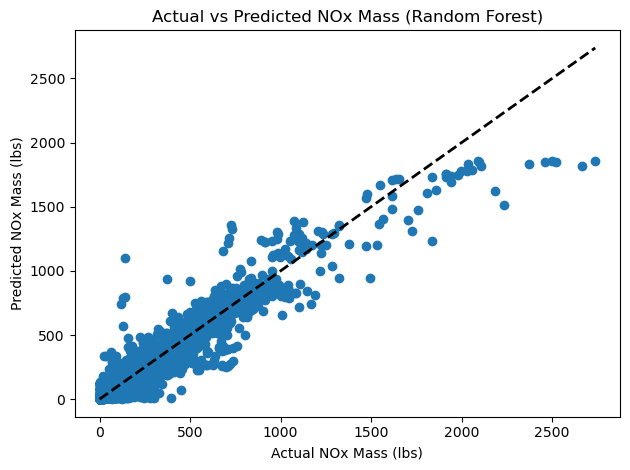

In [ ]:
# default model (no lags, no unmeasured data, with temps)

y_pred = rf_model_no_lags.predict(X_test)

# Set all predictions below 0 to 0
y_pred[y_pred < 0] = 0

print(f"R^2 Score: {r2_score(y_test, y_pred):.4f}")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test, y_pred):.4f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")
print(f"Normalized RMSE (by std): {np.sqrt(mean_squared_error(y_test, y_pred)) / np.std(y_test):.4f}")

plt.scatter(y_test, y_pred)
plt.xlabel("Actual NOx Mass (lbs)")
plt.ylabel("Predicted NOx Mass (lbs)")
plt.title("Actual vs Predicted NOx Mass (Random Forest)")
plt.plot([min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], 'k--', lw=2)
plt.tight_layout()
plt.show()

In [16]:
# compare performance across the imbalanced data
mask_below_500 = y_test < 500
rmse_below_500 = np.sqrt(mean_squared_error(y_test[mask_below_500], y_pred[mask_below_500]))

mask_above_500 = y_test >= 500
rmse_above_500 = np.sqrt(mean_squared_error(y_test[mask_above_500], y_pred[mask_above_500]))

print(f"RMSE for NOx Mass below 500 lbs: {rmse_below_500:.4f}")
print(f"RMSE for NOx Mass above 500 lbs: {rmse_above_500:.4f}")

RMSE for NOx Mass below 500 lbs: 8.5241
RMSE for NOx Mass above 500 lbs: 94.7909


In [ ]:
# even with downsampling takes approx. 6 mins to compute

rf_model_with_lags = RandomForestRegressor(random_state=42, n_jobs=-1)

rf_model_with_lags.fit(X_sampled, y_sampled.values.ravel())

joblib.dump(rf_model_with_lags, "NY/Hourly/Concatted File/Modeling/RF/NOx/Trained Models/rf_default_model_ny_with_lags_no_unmeasured_with_temps.json")

['NY/Hourly/Concatted File/Modeling/RF/NOx/Trained Models/xgb_default_model_ny_with_lags_with_unmeasured_with_temps.json']

In [ ]:
rf_model_with_lags = joblib.load("NY/Hourly/Concatted File/Modeling/RF/NOx/Trained Models/rf_default_model_ny_with_lags_with_unmeasured_with_temps.json")

R^2 Score: 0.9846
Mean Squared Error (MSE): 56.7399
Root Mean Squared Error (RMSE): 7.5326
Normalized RMSE (by std): 0.1240


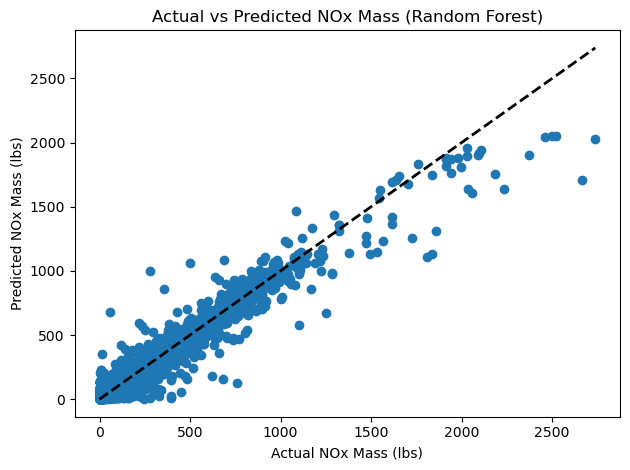

In [ ]:
# default model (with lags, no unmeasured data, with temps)

y_pred = rf_model_with_lags.predict(X_test)

# Set all predictions below 0 to 0
y_pred[y_pred < 0] = 0


print(f"R^2 Score: {r2_score(y_test, y_pred):.4f}")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test, y_pred):.4f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")
print(f"Normalized RMSE (by std): {np.sqrt(mean_squared_error(y_test, y_pred)) / np.std(y_test):.4f}")


plt.scatter(y_test, y_pred)
plt.xlabel("Actual NOx Mass (lbs)")
plt.ylabel("Predicted NOx Mass (lbs)")
plt.title("Actual vs Predicted NOx Mass (Random Forest)")
plt.plot([min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], 'k--', lw=2)
plt.tight_layout()
plt.show()

In [25]:
# compare performance across the imbalanced data
mask_below_500 = y_test < 500
rmse_below_500 = np.sqrt(mean_squared_error(y_test[mask_below_500], y_pred[mask_below_500]))

mask_above_500 = y_test >= 500
rmse_above_500 = np.sqrt(mean_squared_error(y_test[mask_above_500], y_pred[mask_above_500]))

print(f"RMSE for NOx Mass below 500 lbs: {rmse_below_500:.4f}")
print(f"RMSE for NOx Mass above 500 lbs: {rmse_above_500:.4f}")

RMSE for NOx Mass below 500 lbs: 5.8653
RMSE for NOx Mass above 500 lbs: 72.5094


<h4>Scenario Analysis</h4>

In [ ]:
# use the default model with no lags, no unmeasured data, with temps to compare
y_pred_real = y_pred # prediction from model with real X_test

y_pred_sum = sum(y_pred_real)
y_test_sum = sum(y_test)

print(f"Total Predicted NOx Mass (lbs): {y_pred_sum:.4f}")
print(f"Total Actual NOx Mass (lbs): {y_test_sum:.4f}")
print(f"Relative Difference: {(y_pred_sum - y_test_sum) / y_test_sum:.4%}")
print(f"Total Difference: {y_pred_sum - y_test_sum:.4f}")

# the original model miscalculates actual NOx sum by 1.78% which is reasonably low in relative terms
# about 193,222 lbs off in absolute terms

Total Predicted NOx Mass (lbs): 11056084.2651
Total Actual NOx Mass (lbs): 10862861.9763
Relative Difference: 1.7787%
Total Difference: 193222.2888


In [12]:
# simulate all units having SCR in X_test (2024) and look at difference to prediction using real data
X_test_all_SCR = X_test
X_test_all_SCR["encoded__Selective Catalytic Reduction"] = 1

# model with default parameters (no short-term lags, no unmeasured data, with temps)

# predict on data with all SCR = 1

y_pred_all_scr = rf_model_no_lags.predict(X_test_all_SCR)

# set all predictions below 0 to 0
y_pred_all_scr[y_pred_all_scr < 0] = 0

In [13]:
# Difference between real prediction and prediction with all SCR
print(f"Relative Difference: {(y_pred_real.sum() - y_pred_all_scr.sum()) / y_pred_real.sum():.4%}")
print(f"Total Difference: {y_pred_real.sum() - y_pred_all_scr.sum():.4f}")

Relative Difference: 5.0102%
Total Difference: 553931.2855


<h3>MLP</h3>

In [4]:
campd_df = pd.read_csv("NY/Hourly/Concatted File/Modeling/XGB/NOx/ny_2019_2024_complete_cleaned_Full_manually_encoded_downsampled_only_measured", dtype=campd_type_dict)

<h4>No Imputation, remove nan cols/rows</h4>

In [ ]:
navals = campd_df[num_features + encoded_cat_features + unencoded_cat_features].isna().sum() / len(campd_df) * 100
navals[navals > 0]

# instead of imputing with median, we remove nan cols/rows (Summer Capacity has too many nans to impute, for lower nan values we remove the rows)

Gross Load (MW)              4.674485
Latitude                    11.055066
Longitude                   11.055066
Nameplate Capacity (MWe)    11.055066
hourly_capacity_factor       5.678980
hourly_ramping_factor       15.730771
Summer Capacity (MW)        59.033506
Winter Capacity (MW)        59.033506
Minimum Load (MW)           59.033506
Temperature (F)              1.723858
dtype: float64

In [97]:
nan_cols = [
    'Gross Load (MW)',
    'Latitude',
    'Longitude',
    'Nameplate Capacity (MWe)',
    'hourly_capacity_factor',
    'hourly_ramping_factor',

    # we manually remove these cols altogether
    # 'Summer Capacity (MW)',
    # 'Winter Capacity (MW)',
    # 'Minimum Load (MW)',

    'Temperature (F)'
]

campd_df_cleaned = campd_df.dropna(subset=nan_cols)

print(f"Original shape: {campd_df.shape}, New shape: {campd_df_cleaned.shape}")
print(f"Change in total rows: {campd_df_cleaned.shape[0] - campd_df.shape[0]}")

Original shape: (3197828, 95), New shape: (2666036, 95)
Change in total rows: -531792


In [ ]:
df_control_cols = ['Ammonia Injection', 'Combustion Modification/Fuel Reburning',
       'Dry Low NOx Burners',
       'Low NOx Burner Technology (Dry Bottom only)',
       'Low NOx Burner Technology w/ Closed-coupled OFA',
       'Low NOx Burner Technology w/ Closed-coupled/Separated OFA',
       'Low NOx Burner Technology w/ Overfire Air',
       'Low NOx Burner Technology w/ Separated OFA', 'Nothing', 'Other',
       'Overfire Air', 'Selective Catalytic Reduction',
       'Selective Non-catalytic Reduction', 'Steam Injection',
       'Water Injection', 'Water Injection (Began Jul 01, 2022)']
df_code_cols = ['ARP', 'CSNOX', 'CSOSG2', 'CSOSG2E', 'CSOSG3', 'CSSO2G1', 'MATS',
       'Missing', 'NSPS4T', 'RGGI', 'SIPNOX']
cyclical_cols = ['Hour_sin', 'Hour_cos', 'Day_sin',
       'Day_cos', 'Month_sin', 'Month_cos']
lag_cols = [
    "lag_1_hour",
    "lag_2_hours",
    "lag_1_day",
    "lag_2_days",
    "lag_1_week",
    "lag_1_month",
    "lag_1_year"
       ]
# features
num_features = ['Gross Load (MW)', 
                    'Heat Input (mmBtu)',
                'Latitude', 'Longitude',
                'Nameplate Capacity (MWe)', 'hourly_capacity_factor',
                'hourly_ramping_factor',
                #'Summer Capacity (MW)',
                #'Winter Capacity (MW)', 
                #'Minimum Load (MW)', 
                 'Year',
                 'Temperature (F)'
                 ]

unencoded_cat_features = ['Month', 'Hour', 'Day', 
                    'Source Category', 
                    'NOx Phase', 'Unit Type', 'Primary Fuel Type', 
                    'Secondary Fuel Type'] 

encoded_cat_features = list(df_control_cols) + list(df_code_cols) #+ lag_cols #+ cyclical_cols # for passthrough of the manually one-hot encoded cols

target_variable = "NOx Mass (lbs)"

# sort to put it in appropriate time series format
campd_df_cleaned = campd_df_cleaned.sort_values(by=["datetime","Facility ID", "Unit ID"])

# split manually by year 2024
X_train = campd_df_cleaned[(campd_df_cleaned["Year"] < 2024) & (campd_df_cleaned["NOx Mass (lbs)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
y_train = campd_df_cleaned[(campd_df_cleaned["Year"] < 2024) & (campd_df_cleaned["NOx Mass (lbs)"].notna())][target_variable]  
X_test = campd_df_cleaned[(campd_df_cleaned["Year"] == 2024) & (campd_df_cleaned["NOx Mass (lbs)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
y_test = campd_df_cleaned[(campd_df_cleaned["Year"] ==  2024) & (campd_df_cleaned["NOx Mass (lbs)"].notna())][target_variable]

preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), unencoded_cat_features), 
        ('num', StandardScaler(), num_features),
        ('encoded', 'passthrough', encoded_cat_features)  
    ]
)

preprocessor.set_output(transform='pandas') # transform pandas.NA values to normal nan

X_train = preprocessor.fit_transform(X_train)
X_test = preprocessor.transform(X_test)

In [ ]:
# mlp struggles with large datasets, so we downsample the training data to 20%
X_sampled, y_sampled = (
    X_train.sample(frac=0.2, random_state=42),
    y_train.loc[X_train.sample(frac=0.2, random_state=42).index]
)

In [74]:
X_sampled.shape

(446775, 128)

In [ ]:
mlp_default_model = MLPRegressor(random_state=42)
mlp_default_model.fit(X_sampled, y_sampled)

# using the sampled training data, this took 16mins

joblib.dump(mlp_default_model, "NY/Hourly/Concatted File/Modeling/MLP/NOx/Trained Models/mlp_default_model_ny_no_lags_no_unmeasured_with_temps_NO_MEDIAN.json", compress=True)

c:\Users\marce\anaconda3\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:690: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(


['NY/Hourly/Concatted File/Modeling/MLP/NOx/Trained Models/mlp_default_model_ny_no_lags_no_unmeasured_with_temps_NO_MEDIAN.json']

In [12]:
mlp_default_model = joblib.load("NY/Hourly/Concatted File/Modeling/MLP/NOx/Trained Models/mlp_default_model_ny_no_lags_no_unmeasured_with_temps_NO_MEDIAN.json")

In [99]:
# patch column mismatch of training and testing data
X_test["cat__Primary Fuel Type_Coal"] = 0
X_test["cat__Unit Type_Combined cycle (Started Feb 23, 2020)"] = 0
X_test = X_test[X_train.columns]
y_pred = mlp_default_model.predict(X_test)

R^2 Score: 0.9343
Mean Squared Error (MSE): 262.9921
Root Mean Squared Error (RMSE): 16.2170
Normalized RMSE (by std): 0.2562


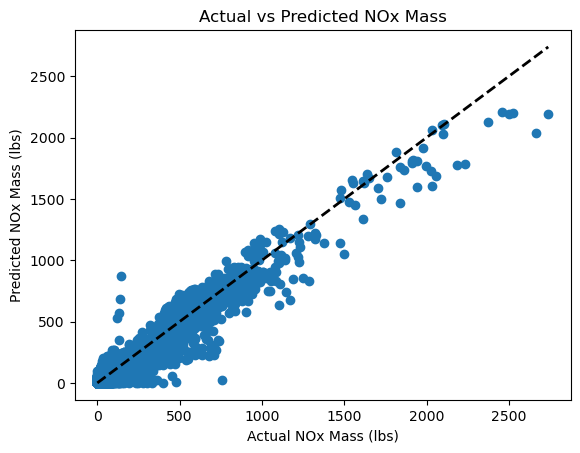

In [ ]:
# set all predictions below 0 to 0
y_pred[y_pred < 0] = 0

print(f"R^2 Score: {r2_score(y_test, y_pred):.4f}")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test, y_pred):.4f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")
print(f"Normalized RMSE (by std): {np.sqrt(mean_squared_error(y_test, y_pred)) / np.std(y_test):.4f}")

plt.scatter(y_test, y_pred)
plt.xlabel("Actual NOx Mass (lbs)")
plt.ylabel("Predicted NOx Mass (lbs)")
plt.title("Actual vs Predicted NOx Mass")
plt.plot([min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], 'k--', lw=2)
plt.show()

<h4>Median Imputation</h4>

In [ ]:
df_control_cols = ['Ammonia Injection', 'Combustion Modification/Fuel Reburning',
       'Dry Low NOx Burners',
       'Low NOx Burner Technology (Dry Bottom only)',
       'Low NOx Burner Technology w/ Closed-coupled OFA',
       'Low NOx Burner Technology w/ Closed-coupled/Separated OFA',
       'Low NOx Burner Technology w/ Overfire Air',
       'Low NOx Burner Technology w/ Separated OFA', 'Nothing', 'Other',
       'Overfire Air', 'Selective Catalytic Reduction',
       'Selective Non-catalytic Reduction', 'Steam Injection',
       'Water Injection', 'Water Injection (Began Jul 01, 2022)']
df_code_cols = ['ARP', 'CSNOX', 'CSOSG2', 'CSOSG2E', 'CSOSG3', 'CSSO2G1', 'MATS',
       'Missing', 'NSPS4T', 'RGGI', 'SIPNOX']
cyclical_cols = ['Hour_sin', 'Hour_cos', 'Day_sin',
       'Day_cos', 'Month_sin', 'Month_cos']
lag_cols = [
    "lag_1_hour",
    "lag_2_hours",
    "lag_1_day",
    "lag_2_days",
    "lag_1_week",
    "lag_1_month",
    "lag_1_year"
       ]
# features
num_features = ['Gross Load (MW)', 
                    'Heat Input (mmBtu)',
                'Latitude', 'Longitude', 
                'Nameplate Capacity (MWe)', 'hourly_capacity_factor',
                'hourly_ramping_factor',
                'Summer Capacity (MW)',
                'Winter Capacity (MW)', 
                'Minimum Load (MW)', 
                 'Year',
                 'Temperature (F)'
                 ]

unencoded_cat_features = ['Month', 'Hour', 'Day', 
                    'Source Category', 
                    'NOx Phase', 'Unit Type', 'Primary Fuel Type', 
                    'Secondary Fuel Type'] 

encoded_cat_features = list(df_control_cols) + list(df_code_cols) #+ lag_cols #+ cyclical_cols # for passthrough of the manually one-hot encoded cols

target_variable = "NOx Mass (lbs)"

# sort to put it in appropriate time series format
campd_df = campd_df.sort_values(by=["datetime","Facility ID", "Unit ID"])

# split manually by year 2024
X_train = campd_df[(campd_df["Year"] < 2024) & (campd_df["NOx Mass (lbs)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
y_train = campd_df[(campd_df["Year"] < 2024) & (campd_df["NOx Mass (lbs)"].notna())][target_variable]  
X_test = campd_df[(campd_df["Year"] == 2024) & (campd_df["NOx Mass (lbs)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
y_test = campd_df[(campd_df["Year"] ==  2024) & (campd_df["NOx Mass (lbs)"].notna())][target_variable]

numeric_imputer = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), unencoded_cat_features), 
        ('num', numeric_imputer, num_features),
        ('encoded', 'passthrough', encoded_cat_features)  
    ]
)

preprocessor.set_output(transform='pandas') # transform pandas.NA values to normal nan

X_train = preprocessor.fit_transform(X_train)
X_test = preprocessor.transform(X_test)

In [ ]:
mlp_default_model = MLPRegressor(random_state=42)
mlp_default_model.fit(X_train, y_train)

# using the full training data, this took 70mins

joblib.dump(mlp_default_model, "NY/Hourly/Concatted File/Modeling/MLP/NOx/Trained Models/mlp_default_model_ny_no_lags_no_unmeasured_with_temps.json", compress=True)

c:\Users\marce\anaconda3\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:690: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(


['NY/Hourly/Concatted File/Modeling/MLP/NOx/Trained Models/mlp_default_model_ny_no_lags_no_unmeasured_with_temps.json']

In [ ]:
# patch column mismatch of training and testing data
X_test["cat__Primary Fuel Type_Coal"] = 0
X_test["cat__Unit Type_Combined cycle (Started Feb 23, 2020)"] = 0
X_test = X_test[X_train.columns]
y_pred = mlp_default_model.predict(X_test)

R^2 Score: 0.8431
Mean Squared Error (MSE): 577.6549
Root Mean Squared Error (RMSE): 24.0345
Normalized RMSE (by std): 0.3958


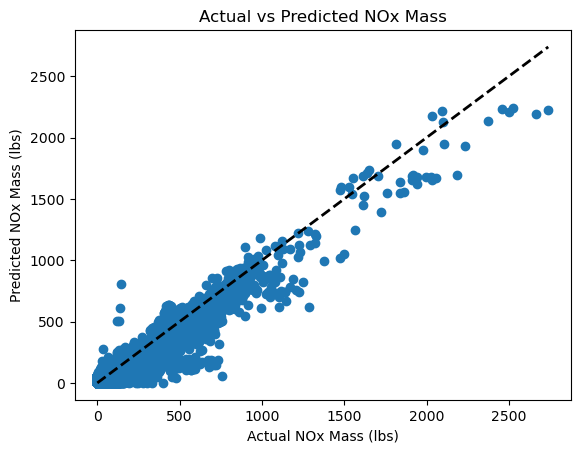

In [113]:
# set all predictions below 0 to 0
y_pred[y_pred < 0] = 0

print(f"R^2 Score: {r2_score(y_test, y_pred):.4f}")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test, y_pred):.4f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")
print(f"Normalized RMSE (by std): {np.sqrt(mean_squared_error(y_test, y_pred)) / np.std(y_test):.4f}")

plt.scatter(y_test, y_pred)
plt.xlabel("Actual NOx Mass (lbs)")
plt.ylabel("Predicted NOx Mass (lbs)")
plt.title("Actual vs Predicted NOx Mass")
plt.plot([min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], 'k--', lw=2)
plt.show()

<h4>With Lags</h4>

In [ ]:
df_control_cols = ['Ammonia Injection', 'Combustion Modification/Fuel Reburning',
       'Dry Low NOx Burners',
       'Low NOx Burner Technology (Dry Bottom only)',
       'Low NOx Burner Technology w/ Closed-coupled OFA',
       'Low NOx Burner Technology w/ Closed-coupled/Separated OFA',
       'Low NOx Burner Technology w/ Overfire Air',
       'Low NOx Burner Technology w/ Separated OFA', 'Nothing', 'Other',
       'Overfire Air', 'Selective Catalytic Reduction',
       'Selective Non-catalytic Reduction', 'Steam Injection',
       'Water Injection', 'Water Injection (Began Jul 01, 2022)']
df_code_cols = ['ARP', 'CSNOX', 'CSOSG2', 'CSOSG2E', 'CSOSG3', 'CSSO2G1', 'MATS',
       'Missing', 'NSPS4T', 'RGGI', 'SIPNOX']
cyclical_cols = ['Hour_sin', 'Hour_cos', 'Day_sin',
       'Day_cos', 'Month_sin', 'Month_cos']
lag_cols = [
    "lag_1_hour",
    "lag_2_hours",
    "lag_1_day",
    "lag_2_days",
    "lag_1_week",
    "lag_1_month",
    "lag_1_year"
       ]
# features
num_features = ['Gross Load (MW)', 
                    'Heat Input (mmBtu)',
                'Latitude', 'Longitude',
                'Nameplate Capacity (MWe)', 'hourly_capacity_factor',
                'hourly_ramping_factor',
                'Summer Capacity (MW)',
                'Winter Capacity (MW)', 
                'Minimum Load (MW)', 
                 'Year',
                 'Temperature (F)'
                 ]

unencoded_cat_features = ['Month', 'Hour', 'Day', 
                    'Source Category', 
                    'NOx Phase', 'Unit Type', 'Primary Fuel Type', 
                    'Secondary Fuel Type'] 

encoded_cat_features = list(df_control_cols) + list(df_code_cols) + lag_cols #+ cyclical_cols # for passthrough of the manually one-hot encoded cols

target_variable = "NOx Mass (lbs)"

# sort to put it in appropriate time series format
campd_df = campd_df.sort_values(by=["datetime","Facility ID", "Unit ID"])

# split manually by year 2024
X_train = campd_df[(campd_df["Year"] < 2024) & (campd_df["NOx Mass (lbs)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
y_train = campd_df[(campd_df["Year"] < 2024) & (campd_df["NOx Mass (lbs)"].notna())][target_variable]  
X_test = campd_df[(campd_df["Year"] == 2024) & (campd_df["NOx Mass (lbs)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
y_test = campd_df[(campd_df["Year"] ==  2024) & (campd_df["NOx Mass (lbs)"].notna())][target_variable]

numeric_imputer = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), unencoded_cat_features), 
        ('num', numeric_imputer, num_features),
        ('encoded', 'passthrough', encoded_cat_features)  
    ]
)

preprocessor.set_output(transform='pandas')

X_train = preprocessor.fit_transform(X_train)
X_test = preprocessor.transform(X_test)

In [6]:
# mlp struggles with large datasets, so we downsample the training data to 20%
X_sampled, y_sampled = (
    X_train.sample(frac=0.2, random_state=42),
    y_train.loc[X_train.sample(frac=0.2, random_state=42).index]
)

In [ ]:
mlp_default_model = MLPRegressor(random_state=42)
mlp_default_model.fit(X_sampled, y_sampled)

joblib.dump(mlp_default_model, "NY/Hourly/Concatted File/Modeling/MLP/NOx/Trained Models/mlp_default_model_ny_with_lags_no_unmeasured_with_temps.json", compress=True)

c:\Users\marce\anaconda3\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:690: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.
  warnings.warn(


['NY/Hourly/Concatted File/Modeling/MLP/NOx/Trained Models/mlp_default_model_ny_with_lags_no_unmeasured_with_temps.json']

In [10]:
# patch column mismatch of training and testing data
X_test["cat__Primary Fuel Type_Coal"] = 0
X_test["cat__Unit Type_Combined cycle (Started Feb 23, 2020)"] = 0
X_test = X_test[X_train.columns]
y_pred = mlp_default_model.predict(X_test)

R^2 Score: 0.9098
Mean Squared Error (MSE): 331.9140
Root Mean Squared Error (RMSE): 18.2185
Normalized RMSE (by std): 0.3000


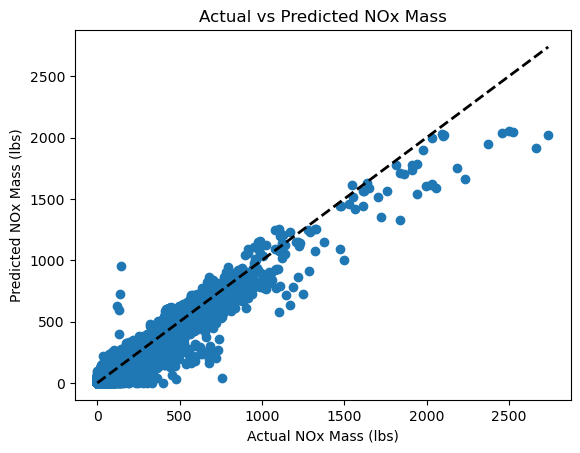

In [11]:
# set all predictions below 0 to 0
y_pred[y_pred < 0] = 0

print(f"R^2 Score: {r2_score(y_test, y_pred):.4f}")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test, y_pred):.4f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")
print(f"Normalized RMSE (by std): {np.sqrt(mean_squared_error(y_test, y_pred)) / np.std(y_test):.4f}")

plt.scatter(y_test, y_pred)
plt.xlabel("Actual NOx Mass (lbs)")
plt.ylabel("Predicted NOx Mass (lbs)")
plt.title("Actual vs Predicted NOx Mass")
plt.plot([min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], 'k--', lw=2)
plt.show()

<h3>XGBoost</h3>

<h5>Preprocessing</h5>

In [7]:
campd_ny["Day"] = campd_ny["datetime"].dt.day

In [8]:
# read in previous year to get according lags
campd_ny_2018 = pd.read_csv("NY/Hourly/Before 2019/emissions-hourly-2018-ny.csv", dtype=campd_type_dict, date_format=["Date"])
campd_ny_2018 = campd_ny_2018[["Facility ID", "Unit ID", "Date", "Hour", "NOx Mass (lbs)"]]
campd_ny_2018["datetime"] = pd.to_datetime(campd_ny_2018["Date"].astype(str) + ' ' + campd_ny_2018["Hour"].astype(str).str.zfill(2) + ":00:00")
campd_ny_2018["NOx Mass (lbs)"] = campd_ny_2018["NOx Mass (lbs)"].fillna(0)

# compute lags
campd_df = preprocess_lag_features(campd_ny, campd_ny_2018, "NOx Mass (lbs)")

In [9]:
campd_df.to_csv("NY/Hourly/Concatted File/Modeling/XGB/NOx/ny_2019_2024_complete_cleaned_Full_with_NOx_lags.csv", index=False)

In [ ]:
campd_df = pd.read_csv("NY/Hourly/Concatted File/Modeling/XGB/NOx/ny_2019_2024_complete_cleaned_Full_with_NOx_lags.csv", dtype=campd_type_dict)
campd_df["Date"] = pd.to_datetime(campd_df["Date"])
campd_df["datetime"] = pd.to_datetime(campd_df["datetime"])

In [10]:
# manually one-hot encode nox controls and program codes
campd_df, df_control_cols = preprocess_nox_controls(campd_df)
campd_df, df_code_cols = preprocess_program_codes(campd_df)

# manually sin/cos encode cyclical features hour, day, month
def encode_cyclical(df, col, max_val):
    df[f"{col}_sin"] = np.sin(2 * np.pi * df[col] / max_val)
    df[f"{col}_cos"] = np.cos(2 * np.pi * df[col] / max_val)
    col_names = [f"{col}_sin", f"{col}_cos"]
    return df, col_names
campd_df, hour_cols = encode_cyclical(campd_df, "Hour", 24) # Daily seasonality
campd_df, day_cols = encode_cyclical(campd_df, "Day", 7)  # Weekly seasonality
campd_df, month_cols = encode_cyclical(campd_df, "Month", 12) # Yearly seasonality
cyclical_cols = hour_cols + day_cols + month_cols

In [11]:
campd_df.to_csv("NY/Hourly/Concatted File/Modeling/XGB/NOx/ny_2019_2024_complete_cleaned_Full_manually_encoded", index=False)

In [ ]:
campd_df = pd.read_csv("NY/Hourly/Concatted File/Modeling/XGB/NOx/ny_2019_2024_complete_cleaned_Full_manually_encoded", dtype=campd_type_dict)

In [12]:
# Randomly remove a fraction of rows where Operating Time is 0.
def downsample_zero_operating_time(df, frac_to_remove=0.9, random_state=42):
    # create dfs for those with and without operating time
    zero_op = df[df["Operating Time"] == 0]
    non_zero_op = df[df["Operating Time"] != 0]

    # remove sample of rows
    drop_sample = zero_op.sample(frac=frac_to_remove, random_state=random_state)
    kept_zero_op = zero_op.drop(index=drop_sample.index)
    df_downsampled = pd.concat([non_zero_op, kept_zero_op]).sort_index()

    return df_downsampled


In [15]:
campd_df.shape

(14028675, 95)

In [18]:
# Downsample 90% of the nonOperating data (should be fine since xgb does not require continuity unlike e. g. LSTM)
campd_df = downsample_zero_operating_time(campd_df)

In [19]:
campd_df.shape

(3563498, 95)

In [20]:
campd_df.to_csv("NY/Hourly/Concatted File/Modeling/XGB/NOx/ny_2019_2024_complete_cleaned_Full_manually_encoded_downsampled", index=False)

In [ ]:
campd_df = pd.read_csv("NY/Hourly/Concatted File/Modeling/XGB/NOx/ny_2019_2024_complete_cleaned_Full_manually_encoded_downsampled", dtype=campd_type_dict)

In [21]:
campd_df["NOx Mass Measure Indicator"].value_counts()

NOx Mass Measure Indicator
Measured                   2035031
Nothing                    1162797
Calculated                  186287
Measured and Substitute     106474
LME                          72482
Substitute                     427
Name: count, dtype: Int64

In [22]:
campd_df = campd_df[(campd_df["NOx Mass Measure Indicator"] == "Measured") | (campd_df["NOx Mass Measure Indicator"] == "Nothing")]
campd_df["NOx Mass Measure Indicator"].value_counts()

NOx Mass Measure Indicator
Measured    2035031
Nothing     1162797
Name: count, dtype: Int64

In [23]:
campd_df.to_csv("NY/Hourly/Concatted File/Modeling/XGB/NOx/ny_2019_2024_complete_cleaned_Full_manually_encoded_downsampled_only_measured", index=False)

In [29]:
campd_df = pd.read_csv("NY/Hourly/Concatted File/Modeling/XGB/NOx/ny_2019_2024_complete_cleaned_Full_manually_encoded_downsampled_only_measured", dtype=campd_type_dict)

In [4]:
df_control_cols = ['Ammonia Injection', 'Combustion Modification/Fuel Reburning',
       'Dry Low NOx Burners',
       'Low NOx Burner Technology (Dry Bottom only)',
       'Low NOx Burner Technology w/ Closed-coupled OFA',
       'Low NOx Burner Technology w/ Closed-coupled/Separated OFA',
       'Low NOx Burner Technology w/ Overfire Air',
       'Low NOx Burner Technology w/ Separated OFA', 'Nothing', 'Other',
       'Overfire Air', 'Selective Catalytic Reduction',
       'Selective Non-catalytic Reduction', 'Steam Injection',
       'Water Injection', 'Water Injection (Began Jul 01, 2022)']
df_code_cols = ['ARP', 'CSNOX', 'CSOSG2', 'CSOSG2E', 'CSOSG3', 'CSSO2G1', 'MATS',
       'Missing', 'NSPS4T', 'RGGI', 'SIPNOX']
cyclical_cols = ['Hour_sin', 'Hour_cos', 'Day_sin',
       'Day_cos', 'Month_sin', 'Month_cos']
lag_cols = [
    "lag_1_hour",
    "lag_2_hours",
    "lag_1_day",
    "lag_2_days",
    "lag_1_week",
    "lag_1_month",
    "lag_1_year"
       ]

In [ ]:
# features
num_features = ['Gross Load (MW)', 
                'Heat Input (mmBtu)',
                'Latitude', 'Longitude', # removed other emissions (CO2, SO2)
                'Nameplate Capacity (MWe)', 'hourly_capacity_factor',
                'hourly_ramping_factor',
                'Summer Capacity (MW)',
                'Winter Capacity (MW)', 
                'Minimum Load (MW)', 
                #'unit_age_min',
                #'unit_age_max', 
                #'unit_age_mean', # removed gen ages because it likely works as a proxy for facility/unit id rather than causal age effects
                 'Year',
                 'Temperature (F)'
                 ]

unencoded_cat_features = ['Month', 'Hour', 'Day', 
                    'Source Category', 
                    'NOx Phase', 'Unit Type', 'Primary Fuel Type', 
                    'Secondary Fuel Type'] 

encoded_cat_features = list(df_control_cols) + list(df_code_cols) #+ lag_cols #+ cyclical_cols # for passthrough of the manually one-hot encoded cols

target_variable = "NOx Mass (lbs)"

# sort to put it in appropriate time series format
campd_df = campd_df.sort_values(by=["datetime","Facility ID", "Unit ID"])

# split manually by year 2024
X_train = campd_df[(campd_df["Year"] < 2024) & (campd_df["NOx Mass (lbs)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
y_train = campd_df[(campd_df["Year"] < 2024) & (campd_df["NOx Mass (lbs)"].notna())][target_variable]  
X_test = campd_df[(campd_df["Year"] == 2024) & (campd_df["NOx Mass (lbs)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
y_test = campd_df[(campd_df["Year"] ==  2024) & (campd_df["NOx Mass (lbs)"].notna())][target_variable]

preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), unencoded_cat_features), 
        ('num', 'passthrough', num_features),
        ('encoded', 'passthrough', encoded_cat_features)  # add the pre-encoded features (NOx Controls)
    ]
)

preprocessor.set_output(transform='pandas') # transform pandas.NA values to normal nan


ColumnTransformer(transformers=[('cat',
                                 OneHotEncoder(handle_unknown='ignore',
                                               sparse_output=False),
                                 ['Month', 'Hour', 'Day', 'Source Category',
                                  'NOx Phase', 'Unit Type', 'Primary Fuel Type',
                                  'Secondary Fuel Type']),
                                ('num', 'passthrough',
                                 ['Gross Load (MW)', 'Heat Input (mmBtu)',
                                  'Latitude', 'Longitude',
                                  'Nameplate Capacity (MWe)',
                                  'hourly_capacity_factor',
                                  'hourly_ramping_facto...
                                  'Closed-coupled/Separated OFA',
                                  'Low NOx Burner Technology w/ Overfire Air',
                                  'Low NOx Burner Technology w/ Separated OFA',
                                  'Nothing', 'Other', 'Overfire Air',
                                  'Selective Catalytic Reduction',
                                  'Selective Non-catalytic Reduction',
                                  'Steam Injection', 'Water Injection',
                                  'Water Injection (Began Jul 01, 2022)', 'ARP',
                                  'CSNOX', 'CSOSG2', 'CSOSG2E', 'CSOSG3',
                                  'CSSO2G1', 'MATS', 'Missing', 'NSPS4T',
                                  'RGGI', 'SIPNOX'])])

In [35]:
X_train.to_csv("NY/Hourly/Concatted File/Modeling/XGB/NOx/X_train", index=False)
X_test.to_csv("NY/Hourly/Concatted File/Modeling/XGB/NOx/X_test", index=False)
y_train.to_csv("NY/Hourly/Concatted File/Modeling/XGB/NOx/y_train", index=False)
y_test.to_csv("NY/Hourly/Concatted File/Modeling/XGB/NOx/y_test", index=False)

In [ ]:
X_train = pd.read_csv("NY/Hourly/Concatted File/Modeling/XGB/NOx/X_train", dtype=campd_type_dict)
X_test = pd.read_csv("NY/Hourly/Concatted File/Modeling/XGB/NOx/X_test", dtype=campd_type_dict)

In [3]:
y_train = pd.read_csv("NY/Hourly/Concatted File/Modeling/XGB/NOx/y_train")
y_test = pd.read_csv("NY/Hourly/Concatted File/Modeling/XGB/NOx/y_test")

In [34]:
X_train = preprocessor.fit_transform(X_train)
X_test = preprocessor.transform(X_test)

In [43]:
X_train.to_csv("NY/Hourly/Concatted File/Modeling/XGB/NOx/X_train_processed", index=False)
X_test.to_csv("NY/Hourly/Concatted File/Modeling/XGB/NOx/X_test_processed", index=False)

In [4]:
X_train = pd.read_csv("NY/Hourly/Concatted File/Modeling/XGB/NOx/X_train_processed", dtype=campd_type_dict)
X_test = pd.read_csv("NY/Hourly/Concatted File/Modeling/XGB/NOx/X_test_processed", dtype=campd_type_dict)

In [109]:
dtrain = xgb.DMatrix(X_train, label=y_train)
dtest = xgb.DMatrix(X_test, label=y_test)

In [44]:
dtrain.save_binary("NY/Hourly/Concatted File/Modeling/XGB/NOx/dtrain_ny_full_2019_2023.buffer")
dtest.save_binary("NY/Hourly/Concatted File/Modeling/XGB/NOx/dtest_ny_full_2024.buffer")

In [42]:
dtrain = xgb.DMatrix("NY/Hourly/Concatted File/Modeling/XGB/NOx/dtrain_ny_full_2019_2023.buffer")
dtest = xgb.DMatrix("NY/Hourly/Concatted File/Modeling/XGB/NOx/dtest_ny_full_2024.buffer")

In [8]:
# default parameters for comparison
default_params = {
    # "n_estimators": 100, # number of trees (larger value, more likely to overfit)
    # "max_depth":  6, # max depth of a tree (larger value, more complex, more likely to overfit)
    # "learning_rate": 0.5, # step size shrinkage eta (lower value, more conservative)
    # "subsample": 1, # random subset size of data to use for each tree (lower value, more conservative)
    # "colsample_bytree": 1, # random subset of features to consider for each tree (lower value, more conservative)
    # "gamma": 0, # min loss reduction to make a split (larger value, more conservative)
    # "reg_alpha": 0, # L1 regularization on weights (larger value, more conservative)
    # "reg_lambda": 1, # L2 regularization on weights (larger value, more conservative)
    # "min_child_weight": 1, # min sum of instance weight (hessian) needed in a child (larger value, more conservative)
    # "tree_method": "auto" # automatically chooses exact or approximation method based on data size

    # needed params for xgb.train
    "objective": "reg:squarederror",
    'eval_metric': 'rmse',
    #"tree_method": "auto", # uses approximation for large datasets
    #"device": "cuda", # use gpu (if unavailable, will use cpu)
    'seed': 42 # like random_state, but for xgb.train
}

<h5>Different Time Series Tests</h5>

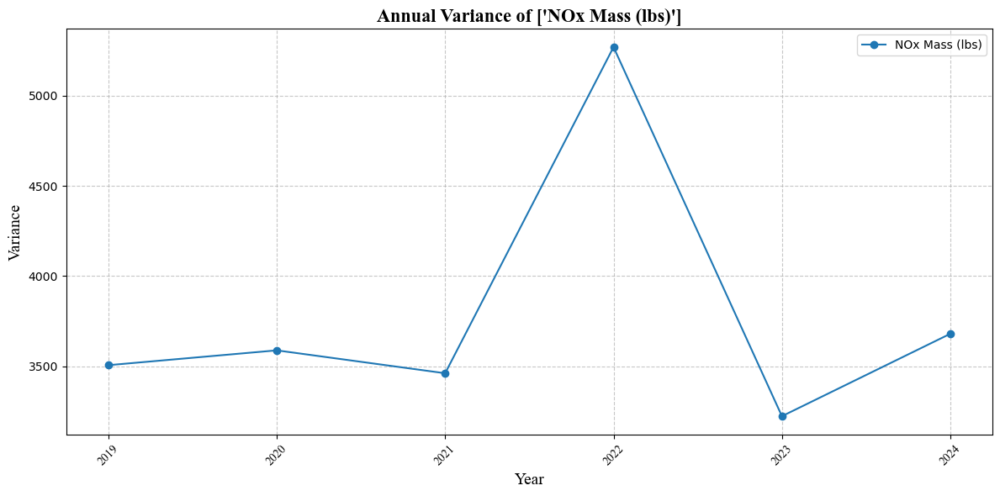

In [ ]:
# Look at yearly variance 

variables = ["NOx Mass (lbs)"]

# Set 'datetime' as index for resampling
campd_df["datetime"] = pd.to_datetime(campd_df["datetime"])
campd_df.set_index('datetime', inplace=True)
annual_variance = campd_df[variables].resample('YE').var()
annual_variance.index = annual_variance.index.year

plt.figure(figsize=(12, 6))

for var in variables:
    plt.plot(annual_variance.index, annual_variance[var], marker='o', label=var)

plt.title(f'Annual Variance of {variables}', fontsize=16, fontweight='bold', fontname='Times New Roman')
plt.xlabel('Year', fontsize=14, fontname='Times New Roman')
plt.ylabel('Variance', fontsize=14, fontname='Times New Roman')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.xticks(annual_variance.index, rotation=45, fontname='Times New Roman')
plt.tight_layout()
plt.show()


In [ ]:
# Year by Year (broken down by Unit and Fuel Type)

year_tuples = [(2019, 2020), (2020, 2021), (2021, 2022), (2022, 2023), (2023, 2024)]

# List of one-hot encoded fuel type columns and unit type columns
fuel_ohe_cols = [col for col in X_test.columns if col.startswith('cat__Primary Fuel Type_')]
unit_ohe_cols = [col for col in X_test.columns if col.startswith('cat__Unit Type_')]

for years in year_tuples:
    train_mask = (campd_df["Year"] == years[0]) & (campd_df["NOx Mass (lbs)"].notna())
    test_mask = (campd_df["Year"] == years[1]) & (campd_df["NOx Mass (lbs)"].notna())
    
    X_train_raw = campd_df.loc[train_mask, num_features + unencoded_cat_features + encoded_cat_features]
    y_train = campd_df.loc[train_mask, target_variable]
    X_test_raw = campd_df.loc[test_mask, num_features + unencoded_cat_features + encoded_cat_features]
    y_test = campd_df.loc[test_mask, target_variable]

    X_train = preprocessor.fit_transform(X_train_raw)
    X_test = preprocessor.transform(X_test_raw)

    dtrain = xgb.DMatrix(X_train, label=y_train)
    dtest = xgb.DMatrix(X_test, label=y_test)

    xgb_default_model = xgb.train(params=default_params, dtrain=dtrain, num_boost_round=100)

    y_pred = xgb_default_model.predict(dtest)
    y_pred[y_pred < 0] = 0

    print(f"Train: {years[0]}, Test: {years[1]} | Overall R^2: {r2_score(y_test, y_pred):.4f}, RMSE: {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}, nRMSE: {np.sqrt(mean_squared_error(y_test, y_pred))/np.std(y_test):.4f}")

    print("By Fuel Type:")
    for fuel_col in fuel_ohe_cols:
        if fuel_col not in X_test.columns:
            print(f"  {fuel_col}: no data")
        else:
            idx = X_test[fuel_col] == 1
            if idx.sum() > 10:
                print(f"  {fuel_col}: R^2: {r2_score(y_test[idx], y_pred[idx]):.4f}, RMSE: {np.sqrt(mean_squared_error(y_test[idx], y_pred[idx])):.4f}, nRMSE: {(np.sqrt(mean_squared_error(y_test[idx], y_pred[idx]))/np.std(y_test[idx])) if np.std(y_test[idx]) != 0 else 0:.4f}, Training: {len(X_train[X_train[fuel_col] == 1])}, Testing: {len(X_test[X_test[fuel_col] == 1])}")
            else:
                print(f"  {fuel_col}: not enough data")

    print("")

    print("By Unit Type:")
    for unit_col in unit_ohe_cols:
        if unit_col not in X_test.columns:
            print(f"  {unit_col}: no data")
        else:
            idx = X_test[unit_col] == 1
            if idx.sum() > 10:
                print(f"  {unit_col}: R^2: {r2_score(y_test[idx], y_pred[idx]):.4f}, RMSE: {np.sqrt(mean_squared_error(y_test[idx], y_pred[idx])):.4f}, nRMSE: {np.sqrt(mean_squared_error(y_test[idx], y_pred[idx]))/np.std(y_test[idx]) if np.std(y_test[idx]) != 0 else 0:.4f}, Training: {len(X_train[X_train[unit_col] == 1])}, Testing: {len(X_test[X_test[unit_col] == 1])}")
            else:
                print(f"  {unit_col}: not enough data")

    print("\n" + "="*60 + "\n")


Train: 2019, Test: 2020 | Overall R^2: 0.9527, RMSE: 13.0381, nRMSE: 0.2177
By Fuel Type:
  cat__Primary Fuel Type_Coal: R^2: 0.9309, RMSE: 74.6529, nRMSE: 0.2628, Training: 8523, Testing: 5803
  cat__Primary Fuel Type_Diesel Oil: R^2: 0.9436, RMSE: 3.9965, nRMSE: 0.2376, Training: 49564, Testing: 49500
  cat__Primary Fuel Type_Natural Gas: R^2: 0.0000, RMSE: 0.2106, nRMSE: 0.0000, Training: 719, Testing: 537
  cat__Primary Fuel Type_Other Oil: R^2: 0.0000, RMSE: 0.0652, nRMSE: 0.0000, Training: 2578, Testing: 2608
  cat__Primary Fuel Type_Pipeline Natural Gas: R^2: 0.9587, RMSE: 10.4671, nRMSE: 0.2033, Training: 411170, Testing: 434310
  cat__Primary Fuel Type_Residual Oil: R^2: 0.9607, RMSE: 26.3835, nRMSE: 0.1983, Training: 17012, Testing: 12746
  cat__Primary Fuel Type_Wood: R^2: 0.7527, RMSE: 4.4302, nRMSE: 0.4973, Training: 19350, Testing: 24310

By Unit Type:
  cat__Unit Type_Circulating fluidized bed boiler: R^2: 0.7527, RMSE: 4.4302, nRMSE: 0.4973, Training: 19350, Testing: 24

Train: 2019, Test: 2020 | Overall R^2: 0.9527, RMSE: 13.0381, nRMSE: 0.2177
R^2 Score: 0.9527
Mean Squared Error (MSE): 169.9912
Root Mean Squared Error (RMSE): 13.0381


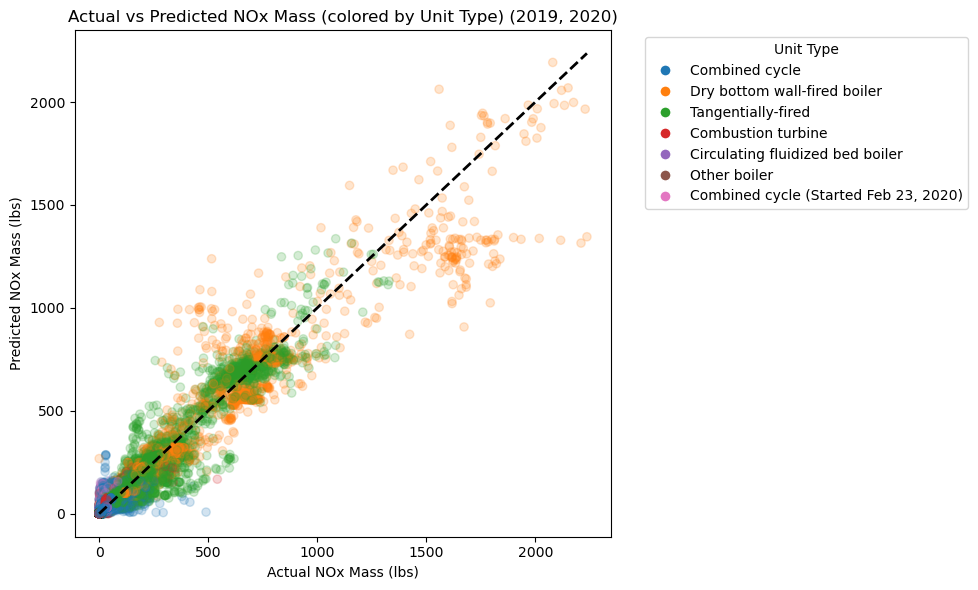

Train: 2020, Test: 2021 | Overall R^2: 0.9361, RMSE: 14.8728, nRMSE: 0.2524
R^2 Score: 0.9361
Mean Squared Error (MSE): 221.1993
Root Mean Squared Error (RMSE): 14.8728


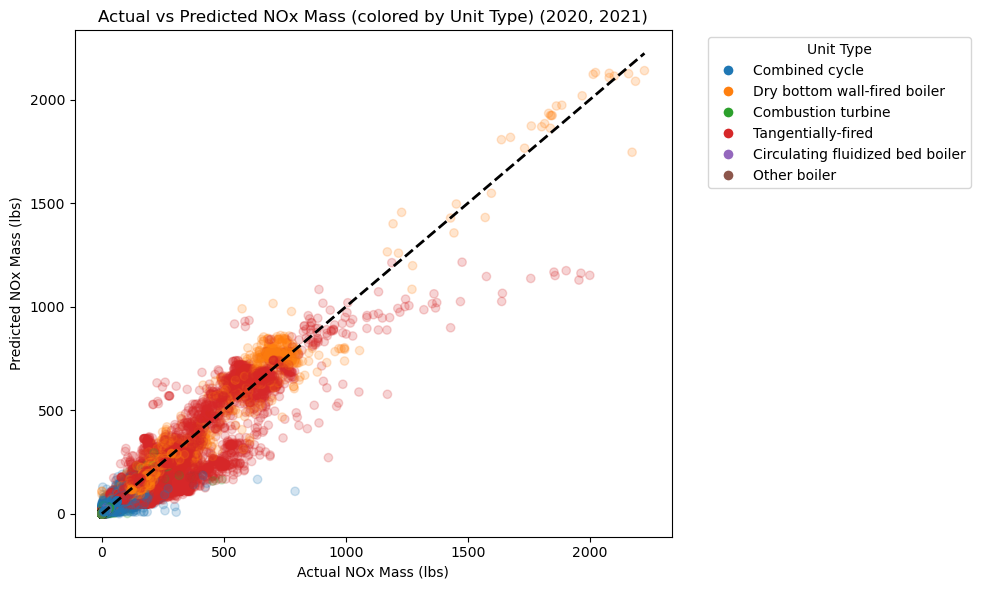

Train: 2021, Test: 2022 | Overall R^2: 0.9324, RMSE: 18.8764, nRMSE: 0.2600
R^2 Score: 0.9324
Mean Squared Error (MSE): 356.3183
Root Mean Squared Error (RMSE): 18.8764


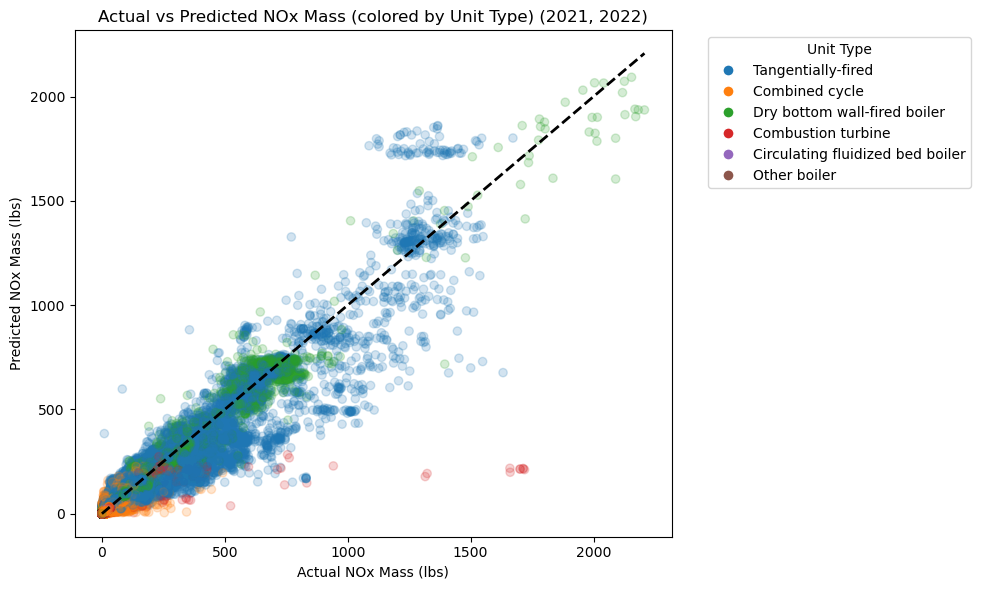

In [116]:
train_mask = (campd_df["Year"] == 2019) & (campd_df["NOx Mass (lbs)"].notna())
test_mask = (campd_df["Year"] == 2020) & (campd_df["NOx Mass (lbs)"].notna())

X_train_raw = campd_df.loc[train_mask, num_features + unencoded_cat_features + encoded_cat_features]
y_train = campd_df.loc[train_mask, target_variable]
X_test_raw = campd_df.loc[test_mask, num_features + unencoded_cat_features + encoded_cat_features]
y_test = campd_df.loc[test_mask, target_variable]

X_train = preprocessor.fit_transform(X_train_raw)
X_test = preprocessor.transform(X_test_raw)

dtrain = xgb.DMatrix(X_train, label=y_train)
dtest = xgb.DMatrix(X_test, label=y_test)

xgb_default_model = xgb.train(params=default_params, dtrain=dtrain, num_boost_round=100)

y_pred = xgb_default_model.predict(dtest)
y_pred[y_pred < 0] = 0

print(f"Train: {2019}, Test: {2020} | Overall R^2: {r2_score(y_test, y_pred):.4f}, RMSE: {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}, nRMSE: {np.sqrt(mean_squared_error(y_test, y_pred))/np.std(y_test):.4f}")

y_test = dtest.get_label()

print(f"R^2 Score: {r2_score(y_test, y_pred):.4f}")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test, y_pred):.4f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")

unit_types_test = campd_df.loc[test_mask, "Unit Type"].reset_index(drop=True)

y_test = pd.Series(y_test).reset_index(drop=True)
y_pred = pd.Series(y_pred).reset_index(drop=True)

unique_unit_types = unit_types_test.unique()
palette = sns.color_palette("tab10", len(unique_unit_types))  
color_mapping = dict(zip(unique_unit_types, palette))
colors = unit_types_test.map(color_mapping)

plt.figure(figsize=(10, 6))
scatter = plt.scatter(y_test, y_pred, c=colors, alpha=0.2)
plt.xlabel("Actual NOx Mass (lbs)")
plt.ylabel("Predicted NOx Mass (lbs)")
plt.title("Actual vs Predicted NOx Mass (colored by Unit Type) (2019, 2020)")
plt.plot(
    [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())],
    [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())],
    'k--', lw=2
)

handles = [plt.Line2D([0], [0], marker='o', color='w', label=ut,
                      markerfacecolor=color_mapping[ut], markersize=8)
           for ut in unique_unit_types]
plt.legend(handles=handles, title="Unit Type", bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()
plt.show()


train_mask = (campd_df["Year"] == 2020) & (campd_df["NOx Mass (lbs)"].notna())
test_mask = (campd_df["Year"] == 2021) & (campd_df["NOx Mass (lbs)"].notna())

X_train_raw = campd_df.loc[train_mask, num_features + unencoded_cat_features + encoded_cat_features]
y_train = campd_df.loc[train_mask, target_variable]
X_test_raw = campd_df.loc[test_mask, num_features + unencoded_cat_features + encoded_cat_features]
y_test = campd_df.loc[test_mask, target_variable]

X_train = preprocessor.fit_transform(X_train_raw)
X_test = preprocessor.transform(X_test_raw)

dtrain = xgb.DMatrix(X_train, label=y_train)
dtest = xgb.DMatrix(X_test, label=y_test)

xgb_default_model = xgb.train(params=default_params, dtrain=dtrain, num_boost_round=100)

y_pred = xgb_default_model.predict(dtest)
y_pred[y_pred < 0] = 0

print(f"Train: {2020}, Test: {2021} | Overall R^2: {r2_score(y_test, y_pred):.4f}, RMSE: {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}, nRMSE: {np.sqrt(mean_squared_error(y_test, y_pred))/np.std(y_test):.4f}")

y_test = dtest.get_label()

print(f"R^2 Score: {r2_score(y_test, y_pred):.4f}")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test, y_pred):.4f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")

unit_types_test = campd_df.loc[test_mask, "Unit Type"].reset_index(drop=True)

y_test = pd.Series(y_test).reset_index(drop=True)
y_pred = pd.Series(y_pred).reset_index(drop=True)

unique_unit_types = unit_types_test.unique()
palette = sns.color_palette("tab10", len(unique_unit_types)) 
color_mapping = dict(zip(unique_unit_types, palette))
colors = unit_types_test.map(color_mapping)

plt.figure(figsize=(10, 6))
scatter = plt.scatter(y_test, y_pred, c=colors, alpha=0.2)
plt.xlabel("Actual NOx Mass (lbs)")
plt.ylabel("Predicted NOx Mass (lbs)")
plt.title("Actual vs Predicted NOx Mass (colored by Unit Type) (2020, 2021)")
plt.plot(
    [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())],
    [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())],
    'k--', lw=2
)

handles = [plt.Line2D([0], [0], marker='o', color='w', label=ut,
                      markerfacecolor=color_mapping[ut], markersize=8)
           for ut in unique_unit_types]
plt.legend(handles=handles, title="Unit Type", bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()
plt.show()

train_mask = (campd_df["Year"] == 2021) & (campd_df["NOx Mass (lbs)"].notna())
test_mask = (campd_df["Year"] == 2022) & (campd_df["NOx Mass (lbs)"].notna())

X_train_raw = campd_df.loc[train_mask, num_features + unencoded_cat_features + encoded_cat_features]
y_train = campd_df.loc[train_mask, target_variable]
X_test_raw = campd_df.loc[test_mask, num_features + unencoded_cat_features + encoded_cat_features]
y_test = campd_df.loc[test_mask, target_variable]

X_train = preprocessor.fit_transform(X_train_raw)
X_test = preprocessor.transform(X_test_raw)

dtrain = xgb.DMatrix(X_train, label=y_train)
dtest = xgb.DMatrix(X_test, label=y_test)

xgb_default_model = xgb.train(params=default_params, dtrain=dtrain, num_boost_round=100)

y_pred = xgb_default_model.predict(dtest)
y_pred[y_pred < 0] = 0

print(f"Train: {2021}, Test: {2022} | Overall R^2: {r2_score(y_test, y_pred):.4f}, RMSE: {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}, nRMSE: {np.sqrt(mean_squared_error(y_test, y_pred))/np.std(y_test):.4f}")

y_test = dtest.get_label()

print(f"R^2 Score: {r2_score(y_test, y_pred):.4f}")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test, y_pred):.4f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")

unit_types_test = campd_df.loc[test_mask, "Unit Type"].reset_index(drop=True)

y_test = pd.Series(y_test).reset_index(drop=True)
y_pred = pd.Series(y_pred).reset_index(drop=True)

unique_unit_types = unit_types_test.unique()
palette = sns.color_palette("tab10", len(unique_unit_types))  
color_mapping = dict(zip(unique_unit_types, palette))
colors = unit_types_test.map(color_mapping)

plt.figure(figsize=(10, 6))
scatter = plt.scatter(y_test, y_pred, c=colors, alpha=0.2)
plt.xlabel("Actual NOx Mass (lbs)")
plt.ylabel("Predicted NOx Mass (lbs)")
plt.title("Actual vs Predicted NOx Mass (colored by Unit Type) (2021, 2022)")
plt.plot(
    [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())],
    [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())],
    'k--', lw=2
)

handles = [plt.Line2D([0], [0], marker='o', color='w', label=ut,
                      markerfacecolor=color_mapping[ut], markersize=8)
           for ut in unique_unit_types]
plt.legend(handles=handles, title="Unit Type", bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()
plt.show()

C:\Users\marce\AppData\Local\Temp\ipykernel_17032\938823226.py:79: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  color_map = plt.cm.get_cmap("tab10", 10)


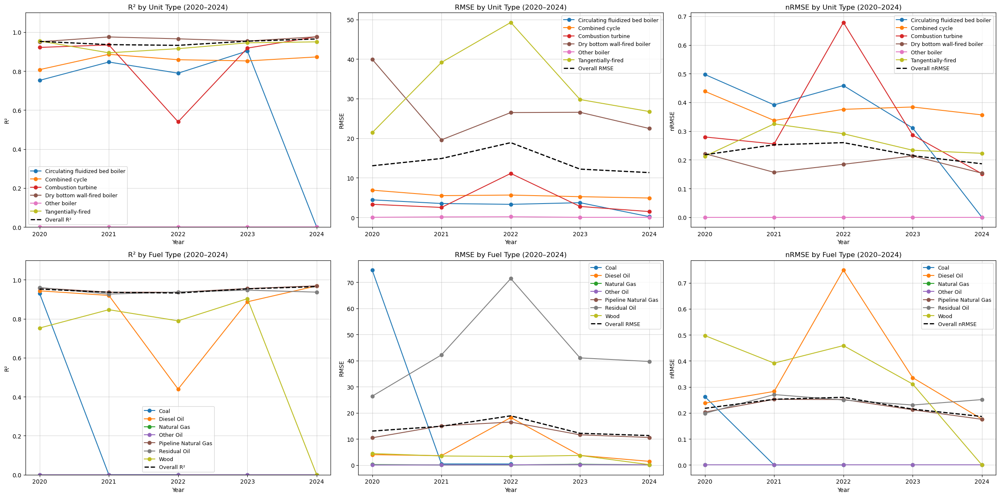

In [19]:

years = [2020, 2021, 2022, 2023, 2024]

fuel_types = [
    "Coal", "Diesel Oil", "Natural Gas", "Other Oil", 
    "Pipeline Natural Gas", "Residual Oil", "Wood"
]

unit_types = [
    "Circulating fluidized bed boiler", "Combined cycle", 
    "Combustion turbine", "Dry bottom wall-fired boiler", 
    "Other boiler", "Tangentially-fired"
]

# Define metric dictionaries
r2_fuel_types = {
    "Coal":       [0.9309, 0.0000, 0.0000, None, None],
    "Diesel Oil": [0.9436, 0.9200, 0.4395, 0.8874, 0.9689],
    "Natural Gas": [0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
    "Other Oil":  [0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
    "Pipeline Natural Gas": [0.9587, 0.9363, 0.9366, 0.9551, 0.9692],
    "Residual Oil": [0.9607, 0.9268, 0.9377, 0.9469, 0.9369],
    "Wood":       [0.7527, 0.8468, 0.7896, 0.9033, 0.0000],
}

rmse_fuel_types = {
    "Coal":       [74.6529, 0.4653, 0.4428, None, None],
    "Diesel Oil": [3.9965, 3.6256, 18.2084, 3.7178, 1.4476],
    "Natural Gas": [0.2106, 0.0736, 0.0552, 0.3433, 0.1039],
    "Other Oil":  [0.0652, 0.0675, 0.1223, 0.1956, 0.1400],
    "Pipeline Natural Gas": [10.4671, 15.0609, 16.4819, 11.6010, 10.5972],
    "Residual Oil": [26.3835, 42.1977, 71.4033, 41.0440, 39.6774],
    "Wood":       [4.4302, 3.5059, 3.2916, 3.7105, 0.1813],
}

nrmse_fuel_types = {
    "Coal":       [0.2628, 0.0000, 0.0000, None, None],
    "Diesel Oil": [0.2376, 0.2826, 0.7488, 0.3355, 0.1763],
    "Natural Gas": [0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
    "Other Oil":  [0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
    "Pipeline Natural Gas": [0.2033, 0.2523, 0.2517, 0.2120, 0.1755],
    "Residual Oil": [0.1983, 0.2706, 0.2496, 0.2304, 0.2513],
    "Wood":       [0.4973, 0.3914, 0.4587, 0.3109, 0.0000],
}

r2_unit_types = {
    "Circulating fluidized bed boiler": [0.7527, 0.8468, 0.7896, 0.9033, 0.0000],
    "Combined cycle": [0.8077, 0.8863, 0.8586, 0.8526, 0.8729],
    "Combustion turbine": [0.9218, 0.9346, 0.5401, 0.9182, 0.9770],
    "Dry bottom wall-fired boiler": [0.9509, 0.9755, 0.9659, 0.9543, 0.9764],
    "Other boiler": [0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
    "Tangentially-fired": [0.9548, 0.8941, 0.9153, 0.9455, 0.9503],
}

rmse_unit_types = {
    "Circulating fluidized bed boiler": [4.4302, 3.5059, 3.2916, 3.7105, 0.1813],
    "Combined cycle": [6.8710, 5.4883, 5.6383, 5.2278, 4.8925],
    "Combustion turbine": [3.3011, 2.5093, 11.1043, 2.7566, 1.4651],
    "Dry bottom wall-fired boiler": [39.9279, 19.5892, 26.4772, 26.5459, 22.4484],
    "Other boiler": [0.0234, 0.1145, 0.1665, 0.0132, 0.0161],
    "Tangentially-fired": [21.4022, 39.1498, 49.2466, 29.7701, 26.7373],
}

nrmse_unit_types = {
    "Circulating fluidized bed boiler": [0.4973, 0.3914, 0.4587, 0.3109, 0.0000],
    "Combined cycle": [0.4386, 0.3372, 0.3759, 0.3840, 0.3565],
    "Combustion turbine": [0.2797, 0.2555, 0.6784, 0.2861, 0.1517],
    "Dry bottom wall-fired boiler": [0.2216, 0.1566, 0.1846, 0.2137, 0.1536],
    "Other boiler": [0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
    "Tangentially-fired": [0.2127, 0.3253, 0.2910, 0.2335, 0.2228],
}

# Overall metrics
overall_r2 = [0.9527, 0.9361, 0.9324, 0.9539, 0.9652]
overall_rmse = [13.0381, 14.8728, 18.8764, 12.1880, 11.3142]
overall_nrmse = [0.2177, 0.2524, 0.2600, 0.2146, 0.1863]


# Color maps
color_map = plt.cm.get_cmap("tab10", 10)
unit_color_dict = {unit: color_map(i / len(r2_unit_types)) for i, unit in enumerate(r2_unit_types)}
fuel_color_dict = {fuel: color_map(i / len(r2_fuel_types)) for i, fuel in enumerate(r2_fuel_types)}

# Create 2x3 subplots (2 rows, 3 columns)
fig, axs = plt.subplots(2, 3, figsize=(24, 12))

# Row 1 - Unit Types: R2, RMSE, nRMSE
# R² by Unit Type
for unit, values in r2_unit_types.items():
    axs[0, 0].plot(years, values, marker='o', label=unit, color=unit_color_dict[unit])
axs[0, 0].plot(years, overall_r2, linestyle='--', color='black', linewidth=2, label='Overall R²')
axs[0, 0].set_title("R² by Unit Type (2020–2024)")
axs[0, 0].set_xlabel("Year")
axs[0, 0].set_xticks(years)
axs[0, 0].set_ylabel("R²")
axs[0, 0].set_ylim(0, 1.1)
axs[0, 0].legend(fontsize=9)
axs[0, 0].grid(alpha=0.5)

# RMSE by Unit Type
for unit, values in rmse_unit_types.items():
    axs[0, 1].plot(years, values, marker='o', label=unit, color=unit_color_dict[unit])
axs[0, 1].plot(years, overall_rmse, linestyle='--', color='black', linewidth=2, label='Overall RMSE')
axs[0, 1].set_title("RMSE by Unit Type (2020–2024)")
axs[0, 1].set_xlabel("Year")
axs[0, 1].set_xticks(years)
axs[0, 1].set_ylabel("RMSE")
axs[0, 1].legend(fontsize=9)
axs[0, 1].grid(alpha=0.5)

# nRMSE by Unit Type
for unit, values in nrmse_unit_types.items():
    axs[0, 2].plot(years, values, marker='o', label=unit, color=unit_color_dict[unit])
axs[0, 2].plot(years, overall_nrmse, linestyle='--', color='black', linewidth=2, label='Overall nRMSE')
axs[0, 2].set_title("nRMSE by Unit Type (2020–2024)")
axs[0, 2].set_xlabel("Year")
axs[0, 2].set_xticks(years)
axs[0, 2].set_ylabel("nRMSE")
axs[0, 2].legend(fontsize=9)
axs[0, 2].grid(alpha=0.5)

# Row 2 - Fuel Types: R2, RMSE, nRMSE
# R² by Fuel Type
for fuel, values in r2_fuel_types.items():
    axs[1, 0].plot(years, values, marker='o', label=fuel, color=fuel_color_dict[fuel])
axs[1, 0].plot(years, overall_r2, linestyle='--', color='black', linewidth=2, label='Overall R²')
axs[1, 0].set_title("R² by Fuel Type (2020–2024)")
axs[1, 0].set_xlabel("Year")
axs[1, 0].set_xticks(years)
axs[1, 0].set_ylabel("R²")
axs[1, 0].set_ylim(0, 1.1)
axs[1, 0].legend(fontsize=9)
axs[1, 0].grid(alpha=0.5)

# RMSE by Fuel Type
for fuel, values in rmse_fuel_types.items():
    axs[1, 1].plot(years, values, marker='o', label=fuel, color=fuel_color_dict[fuel])
axs[1, 1].plot(years, overall_rmse, linestyle='--', color='black', linewidth=2, label='Overall RMSE')
axs[1, 1].set_title("RMSE by Fuel Type (2020–2024)")
axs[1, 1].set_xlabel("Year")
axs[1, 1].set_xticks(years)
axs[1, 1].set_ylabel("RMSE")
axs[1, 1].legend(fontsize=9)
axs[1, 1].grid(alpha=0.5)

# nRMSE by Fuel Type
for fuel, values in nrmse_fuel_types.items():
    axs[1, 2].plot(years, values, marker='o', label=fuel, color=fuel_color_dict[fuel])
axs[1, 2].plot(years, overall_nrmse, linestyle='--', color='black', linewidth=2, label='Overall nRMSE')
axs[1, 2].set_title("nRMSE by Fuel Type (2020–2024)")
axs[1, 2].set_xlabel("Year")
axs[1, 2].set_xticks(years)
axs[1, 2].set_ylabel("nRMSE")
axs[1, 2].legend(fontsize=9)
axs[1, 2].grid(alpha=0.5)

plt.tight_layout()
plt.show()


In [21]:
display(campd_df.groupby(by="Unit Type")["Primary Fuel Type"].value_counts())

Unit Type                              Primary Fuel Type   
Circulating fluidized bed boiler       Wood                      93571
Combined cycle                         Pipeline Natural Gas    1556746
Combined cycle (Started Feb 23, 2020)  Pipeline Natural Gas       4195
Combustion turbine                     Pipeline Natural Gas     629755
                                       Diesel Oil               349163
                                       Other Oil                 21124
Dry bottom wall-fired boiler           Pipeline Natural Gas     108146
                                       Residual Oil              46394
                                       Coal                       5040
                                       Natural Gas                4158
Other boiler                           Pipeline Natural Gas       2586
Tangentially-fired                     Pipeline Natural Gas     336546
                                       Residual Oil              25547
                 

In [117]:
# Year by Year

year_tuples = [(2019, 2020), (2020, 2021), (2021, 2022), (2022, 2023), (2023, 2024)] 

for years in year_tuples:

    X_train = campd_df[(campd_df["Year"] == years[0]) & (campd_df["NOx Mass (lbs)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
    y_train = campd_df[(campd_df["Year"] == years[0]) & (campd_df["NOx Mass (lbs)"].notna())][target_variable]  
    X_test = campd_df[(campd_df["Year"] == years[1]) & (campd_df["NOx Mass (lbs)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
    y_test = campd_df[(campd_df["Year"] ==  years[1]) & (campd_df["NOx Mass (lbs)"].notna())][target_variable]

    X_train = preprocessor.fit_transform(X_train)
    X_test = preprocessor.transform(X_test)

    dtrain = xgb.DMatrix(X_train, label=y_train)
    dtest = xgb.DMatrix(X_test, label=y_test)

    xgb_default_model = xgb.train(params=default_params, dtrain=dtrain, num_boost_round=100)

    y_pred = xgb_default_model.predict(dtest)

    y_pred[y_pred < 0] = 0

    print(f"Train: {years[0]}, Test: {years[1]} | R^2: {r2_score(y_test, y_pred):.4f}, MSE: {mean_squared_error(y_test, y_pred):.4f}, RMSE: {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}, nRMSE: {np.sqrt(mean_squared_error(y_test, y_pred)) / np.std(y_test):.4f}")


Train: 2019, Test: 2020 | R^2: 0.9527, MSE: 169.9912, RMSE: 13.0381, nRMSE: 0.2177
Train: 2020, Test: 2021 | R^2: 0.9361, MSE: 221.1993, RMSE: 14.8728, nRMSE: 0.2524
Train: 2021, Test: 2022 | R^2: 0.9324, MSE: 356.3183, RMSE: 18.8764, nRMSE: 0.2600
Train: 2022, Test: 2023 | R^2: 0.9539, MSE: 148.5485, RMSE: 12.1880, nRMSE: 0.2146
Train: 2023, Test: 2024 | R^2: 0.9652, MSE: 128.0112, RMSE: 11.3142, nRMSE: 0.1863


In [30]:
# Rolling Window

years = [2019, 2020, 2021, 2022, 2023, 2024]

for i in range(1, len(years)):
    train_years = years[:i]      # all years before the test year
    test_year = years[i]         # current year for testing

    X_train = campd_df[(campd_df["Year"].isin(train_years)) & (campd_df["NOx Mass (lbs)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
    y_train = campd_df[(campd_df["Year"].isin(train_years)) & (campd_df["NOx Mass (lbs)"].notna())][target_variable]

    X_test = campd_df[(campd_df["Year"] == test_year) & (campd_df["NOx Mass (lbs)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
    y_test = campd_df[(campd_df["Year"] == test_year) & (campd_df["NOx Mass (lbs)"].notna())][target_variable]

    X_train = preprocessor.fit_transform(X_train)
    X_test = preprocessor.transform(X_test)

    dtrain = xgb.DMatrix(X_train, label=y_train)
    dtest = xgb.DMatrix(X_test, label=y_test)

    xgb_default_model = xgb.train(params=default_params, dtrain=dtrain, num_boost_round=100)

    y_pred = xgb_default_model.predict(dtest)
    y_pred[y_pred < 0] = 0

    print(f"Train: {train_years}, Test: {test_year} | R^2: {r2_score(y_test, y_pred):.4f}, "
          f"MSE: {mean_squared_error(y_test, y_pred):.4f}, "
          f"RMSE: {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}, "
          f"nRMSE: {np.sqrt(mean_squared_error(y_test, y_pred)) / np.std(y_test):.4f}")



Train: [2019], Test: 2020 | R^2: 0.9527, MSE: 169.9912, RMSE: 13.0381, nRMSE: 0.2177
Train: [2019, 2020], Test: 2021 | R^2: 0.9364, MSE: 220.1571, RMSE: 14.8377, nRMSE: 0.2518
Train: [2019, 2020, 2021], Test: 2022 | R^2: 0.9353, MSE: 340.9423, RMSE: 18.4646, nRMSE: 0.2543
Train: [2019, 2020, 2021, 2022], Test: 2023 | R^2: 0.9604, MSE: 127.6584, RMSE: 11.2986, nRMSE: 0.1989
Train: [2019, 2020, 2021, 2022, 2023], Test: 2024 | R^2: 0.9681, MSE: 117.4326, RMSE: 10.8366, nRMSE: 0.1784


In [ ]:
# Static Prediction Horizon (2024)

years = [2019, 2020, 2021, 2022, 2023]
test_year = 2024

for i in range(1, len(years) + 1):
    train_years = years[:i]  # Use first i years as training set
    
    X_train = campd_df[(campd_df["Year"].isin(train_years)) & (campd_df["NOx Mass (lbs)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
    y_train = campd_df[(campd_df["Year"].isin(train_years)) & (campd_df["NOx Mass (lbs)"].notna())][target_variable]

    X_test = campd_df[(campd_df["Year"] == test_year) & (campd_df["NOx Mass (lbs)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
    y_test = campd_df[(campd_df["Year"] == test_year) & (campd_df["NOx Mass (lbs)"].notna())][target_variable]

    X_train = preprocessor.fit_transform(X_train)
    X_test = preprocessor.transform(X_test)

    dtrain = xgb.DMatrix(X_train, label=y_train)
    dtest = xgb.DMatrix(X_test, label=y_test)

    xgb_default_model = xgb.train(params=default_params, dtrain=dtrain, num_boost_round=100)

    y_pred = xgb_default_model.predict(dtest)
    y_pred[y_pred < 0] = 0

    print(f"Train: {train_years}, Test: {test_year} | "
          f"R^2: {r2_score(y_test, y_pred):.4f}, "
          f"MSE: {mean_squared_error(y_test, y_pred):.4f}, "
          f"RMSE: {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}, "
          f"nRMSE: {np.sqrt(mean_squared_error(y_test, y_pred)) / np.std(y_test):.4f}")


Train: [2019], Test: 2024 | R^2: 0.9498, MSE: 184.8431, RMSE: 13.5957, nRMSE: 0.2239
Train: [2019, 2020], Test: 2024 | R^2: 0.9645, MSE: 130.7925, RMSE: 11.4365, nRMSE: 0.1883
Train: [2019, 2020, 2021], Test: 2024 | R^2: 0.9606, MSE: 144.8533, RMSE: 12.0355, nRMSE: 0.1982
Train: [2019, 2020, 2021, 2022], Test: 2024 | R^2: 0.9622, MSE: 139.2584, RMSE: 11.8008, nRMSE: 0.1943
Train: [2019, 2020, 2021, 2022, 2023], Test: 2024 | R^2: 0.9681, MSE: 117.4326, RMSE: 10.8366, nRMSE: 0.1784


In [ ]:
# Time Series Split

# conducted on dataset no lags, no unmeasured, with temps

n_splits = 5
tscv = TimeSeriesSplit(n_splits=n_splits)
best_iterations = []
rmse_scores = []
r2_scores = []

# iterate over each fold and assign the train and test values based on the indeces of the TimeSeriesSplit
for fold, (train_idx, test_idx) in enumerate(tscv.split(X_train)):
    current_X_train, current_X_test = X_train.iloc[train_idx], X_train.iloc[test_idx]
    current_y_train, current_y_test = y_train.iloc[train_idx], y_train.iloc[test_idx]
    
    current_dtrain = xgb.DMatrix(current_X_train, label=current_y_train)
    current_dtest = xgb.DMatrix(current_X_test, label=current_y_test)
    
    # train a model on the current training data and validate it on testing data. create models with up to 1000 boost round until validation shows no more progress (after 20 rounds)
    model = xgb.train(
        default_params,
        current_dtrain,
        num_boost_round=1000,
        early_stopping_rounds=20,
        evals=[(current_dtest, "validation")],
        verbose_eval=False # prevents printing at each boosting stage
    )
    
    # predict on validation for this fold and store the evaluation metric rmse
    y_pred = model.predict(current_dtest)
    rmse = root_mean_squared_error(current_y_test, y_pred)
    r2 = r2_score(current_y_test, y_pred)
    
    best_iterations.append(model.best_iteration)
    rmse_scores.append(rmse)
    r2_scores.append(r2)
    
    print(f"Fold {fold+1}: best_iteration={model.best_iteration}, RMSE={rmse:.4f}, R2={r2:.4f}")

# average best iteration across all folds
optimal_rounds = int(np.mean(best_iterations))
print(f"\nOptimal num_boost_round (avg): {optimal_rounds}")
print(f"Average RMSE across folds: {np.mean(rmse_scores):.4f}")
print(f"Average R2 across folds: {np.mean(r2_scores):.4f}")


Fold 1: best_iteration=105, RMSE=13.3941, R2=0.9498
Fold 2: best_iteration=72, RMSE=14.1404, R2=0.9444
Fold 3: best_iteration=23, RMSE=18.0127, R2=0.9357
Fold 4: best_iteration=118, RMSE=14.7544, R2=0.9432
Fold 5: best_iteration=77, RMSE=10.6622, R2=0.9636

Optimal num_boost_round (avg): 79
Average RMSE across folds: 14.1928
Average R2 across folds: 0.9473


In [ ]:
# Time Series Split

# conducted on dataset with lags, no unmeasured, with temps

n_splits = 5
tscv = TimeSeriesSplit(n_splits=n_splits)
best_iterations = []
rmse_scores = []
r2_scores = []

# iterate over each fold and assign the train and test values based on the indeces of the TimeSeriesSplit
for fold, (train_idx, test_idx) in enumerate(tscv.split(X_train)):
    current_X_train, current_X_test = X_train.iloc[train_idx], X_train.iloc[test_idx]
    current_y_train, current_y_test = y_train.iloc[train_idx], y_train.iloc[test_idx]
    
    current_dtrain = xgb.DMatrix(current_X_train, label=current_y_train)
    current_dtest = xgb.DMatrix(current_X_test, label=current_y_test)
    
    # train a model on the current training data and validate it on testing data. create models with up to 1000 boost round until validation shows no more progress (after 20 rounds)
    model = xgb.train(
        default_params,
        current_dtrain,
        num_boost_round=1000,
        early_stopping_rounds=20,
        evals=[(current_dtest, "validation")],
        verbose_eval=False # prevents printing at each boosting stage
    )
    
    # predict on validation for this fold and store the evaluation metric rmse
    y_pred = model.predict(current_dtest)
    rmse = root_mean_squared_error(current_y_test, y_pred)
    r2 = r2_score(current_y_test, y_pred)
    
    best_iterations.append(model.best_iteration)
    rmse_scores.append(rmse)
    r2_scores.append(r2)
    
    print(f"Fold {fold+1}: best_iteration={model.best_iteration}, RMSE={rmse:.4f}, R2={r2:.4f}")

# average best iteration across all folds
optimal_rounds = int(np.mean(best_iterations))
print(f"\nOptimal num_boost_round (avg): {optimal_rounds}")
print(f"Average RMSE across folds: {np.mean(rmse_scores):.4f}")
print(f"Average R2 across folds: {np.mean(r2_scores):.4f}")


Fold 1: best_iteration=17, RMSE=14.1850, R2=0.9437
Fold 2: best_iteration=111, RMSE=10.0866, R2=0.9717
Fold 3: best_iteration=69, RMSE=11.1816, R2=0.9752
Fold 4: best_iteration=34, RMSE=11.8458, R2=0.9634
Fold 5: best_iteration=139, RMSE=7.8996, R2=0.9800

Optimal num_boost_round (avg): 74
Average RMSE across folds: 11.0397
Average R2 across folds: 0.9668


<h5>Train All, Test Year 2024</h5>

c:\Users\marce\anaconda3\Lib\site-packages\xgboost\core.py:158: UserWarning: [15:17:19] WARNING: C:\b\abs_90_bwj_86a\croot\xgboost-split_1724073762025\work\src\context.cc:196: XGBoost is not compiled with CUDA support.
  warnings.warn(smsg, UserWarning)


R^2 Score: 0.9445
Mean Squared Error (MSE): 217.9756
Root Mean Squared Error (RMSE): 14.7640


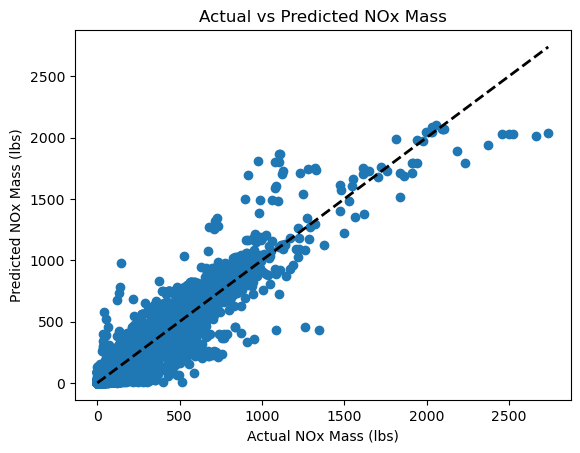

In [ ]:
# model with default parameters (no lags, with unmeasured data, no temps)

xgb_default_model = xgb.train(params=default_params, dtrain=dtrain, num_boost_round=100)

# dump model
xgb_default_model.save_model("NY/Hourly/Concatted File/Modeling/XGB/NOx/Trained Models/xgb_default_model_ny_no_lags_with_unmeasured_no_temps.json")

y_pred = xgb_default_model.predict(dtest)

# set all predictions below 0 to 0
y_pred[y_pred < 0] = 0

y_test = dtest.get_label() # get y_test from dmatrix

print(f"R^2 Score: {r2_score(y_test, y_pred):.4f}")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test, y_pred):.4f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")

plt.scatter(y_test, y_pred)
plt.xlabel("Actual NOx Mass (lbs)")
plt.ylabel("Predicted NOx Mass (lbs)")
plt.title("Actual vs Predicted NOx Mass")
plt.plot([min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], 'k--', lw=2)
plt.show()

R^2 Score: 0.9641
Mean Squared Error (MSE): 132.2916
Root Mean Squared Error (RMSE): 11.5018


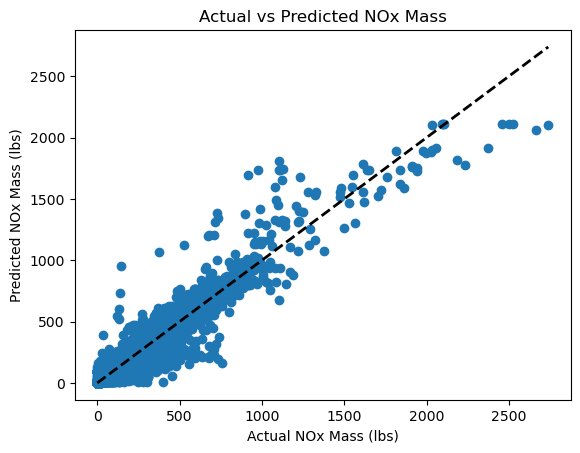

In [ ]:
# model with default parameters (no lags, no unmeasured data, no temps)

# no cyclical cols, with categorical encoding of month, day, hour

xgb_default_model = xgb.train(params=default_params, dtrain=dtrain, num_boost_round=100)

# dump model
xgb_default_model.save_model("NY/Hourly/Concatted File/Modeling/XGB/NOx/Trained Models/xgb_default_model_ny_no_lags_no_unmeasured_no_temps.json")

y_pred = xgb_default_model.predict(dtest)

# set all predictions below 0 to 0
y_pred[y_pred < 0] = 0

y_test = dtest.get_label() # get y_test from dmatrix

print(f"R^2 Score: {r2_score(y_test, y_pred):.4f}")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test, y_pred):.4f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")

plt.scatter(y_test, y_pred)
plt.xlabel("Actual NOx Mass (lbs)")
plt.ylabel("Predicted NOx Mass (lbs)")
plt.title("Actual vs Predicted NOx Mass")
plt.plot([min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], 'k--', lw=2)
plt.show()

R^2 Score: 0.9592
Mean Squared Error (MSE): 150.0323
Root Mean Squared Error (RMSE): 12.2488


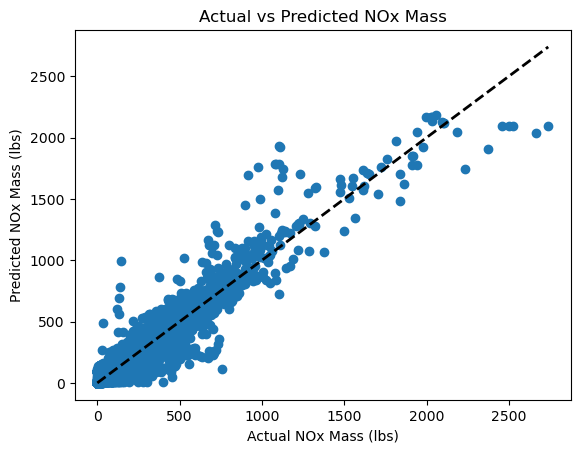

In [ ]:
# model with default parameters (no lags, no unmeasured data, no temps)

# with cyclical cols, no categorical encoding of month, day, hour

xgb_default_model = xgb.train(params=default_params, dtrain=dtrain, num_boost_round=100)

# dump model
#xgb_default_model.save_model("NY/Hourly/Concatted File/Modeling/XGB/NOx/Trained Models/xgb_default_model_ny_no_lags_no_unmeasured_no_temps.json")

y_pred = xgb_default_model.predict(dtest)

# set all predictions below 0 to 0
y_pred[y_pred < 0] = 0

y_test = dtest.get_label() # get y_test from dmatrix

print(f"R^2 Score: {r2_score(y_test, y_pred):.4f}")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test, y_pred):.4f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")

plt.scatter(y_test, y_pred)
plt.xlabel("Actual NOx Mass (lbs)")
plt.ylabel("Predicted NOx Mass (lbs)")
plt.title("Actual vs Predicted NOx Mass")
plt.plot([min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], 'k--', lw=2)
plt.show()

R^2 Score: 0.9624
Mean Squared Error (MSE): 138.3572
Root Mean Squared Error (RMSE): 11.7625


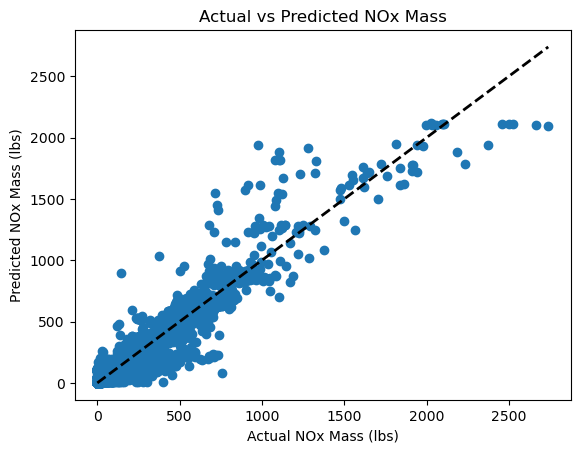

In [ ]:
# model with default parameters (no lags, no unmeasured data, no temps)

# no cyclical cols, no categorical encoding of month, day, hour

xgb_default_model = xgb.train(params=default_params, dtrain=dtrain, num_boost_round=100)

# dump model
#xgb_default_model.save_model("NY/Hourly/Concatted File/Modeling/XGB/NOx/Trained Models/xgb_default_model_ny_no_lags_no_unmeasured_no_temps.json")

y_pred = xgb_default_model.predict(dtest)

# set all predictions below 0 to 0
y_pred[y_pred < 0] = 0

y_test = dtest.get_label() # get y_test from dmatrix

print(f"R^2 Score: {r2_score(y_test, y_pred):.4f}")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test, y_pred):.4f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")

plt.scatter(y_test, y_pred)
plt.xlabel("Actual NOx Mass (lbs)")
plt.ylabel("Predicted NOx Mass (lbs)")
plt.title("Actual vs Predicted NOx Mass")
plt.plot([min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], 'k--', lw=2)
plt.show()

In [94]:
dtrain_no_HI = xgb.DMatrix(X_train.drop(columns="num__Heat Input (mmBtu)"), label=y_train)
dtest_no_HI = xgb.DMatrix(X_test.drop(columns="num__Heat Input (mmBtu)"), label=y_test)
dtrain_no_GL = xgb.DMatrix(X_train.drop(columns="num__Gross Load (MW)"), label=y_train)
dtest_no_GL = xgb.DMatrix(X_test.drop(columns="num__Gross Load (MW)"), label=y_test)

R^2 Score: 0.9538
Mean Squared Error (MSE): 170.1969
Root Mean Squared Error (RMSE): 13.0460
Normalized RMSE (by std): 0.2150


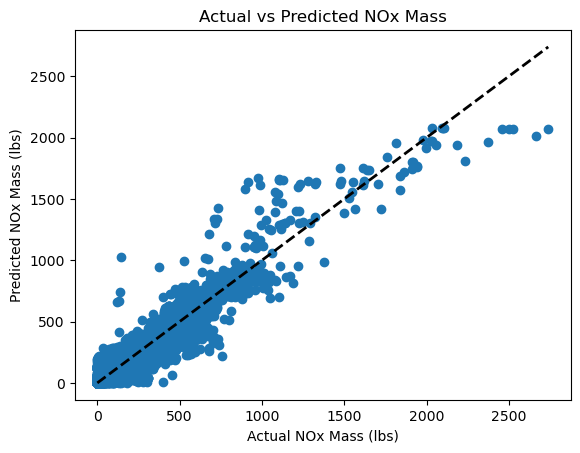

In [ ]:
# model with default parameters (no lags, no unmeasured data, with temps)

xgb_default_model = xgb.train(params=default_params, dtrain=dtrain_no_HI, num_boost_round=100)

y_pred = xgb_default_model.predict(dtest_no_HI)

# set all predictions below 0 to 0
y_pred[y_pred < 0] = 0

y_test = dtest_no_HI.get_label() # get y_test from dmatrix

print(f"R^2 Score: {r2_score(y_test, y_pred):.4f}")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test, y_pred):.4f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")
print(f"Normalized RMSE (by std): {np.sqrt(mean_squared_error(y_test, y_pred)) / np.std(y_test):.4f}")

plt.scatter(y_test, y_pred)
plt.xlabel("Actual NOx Mass (lbs)")
plt.ylabel("Predicted NOx Mass (lbs)")
plt.title("Actual vs Predicted NOx Mass")
plt.plot([min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], 'k--', lw=2)
plt.show()

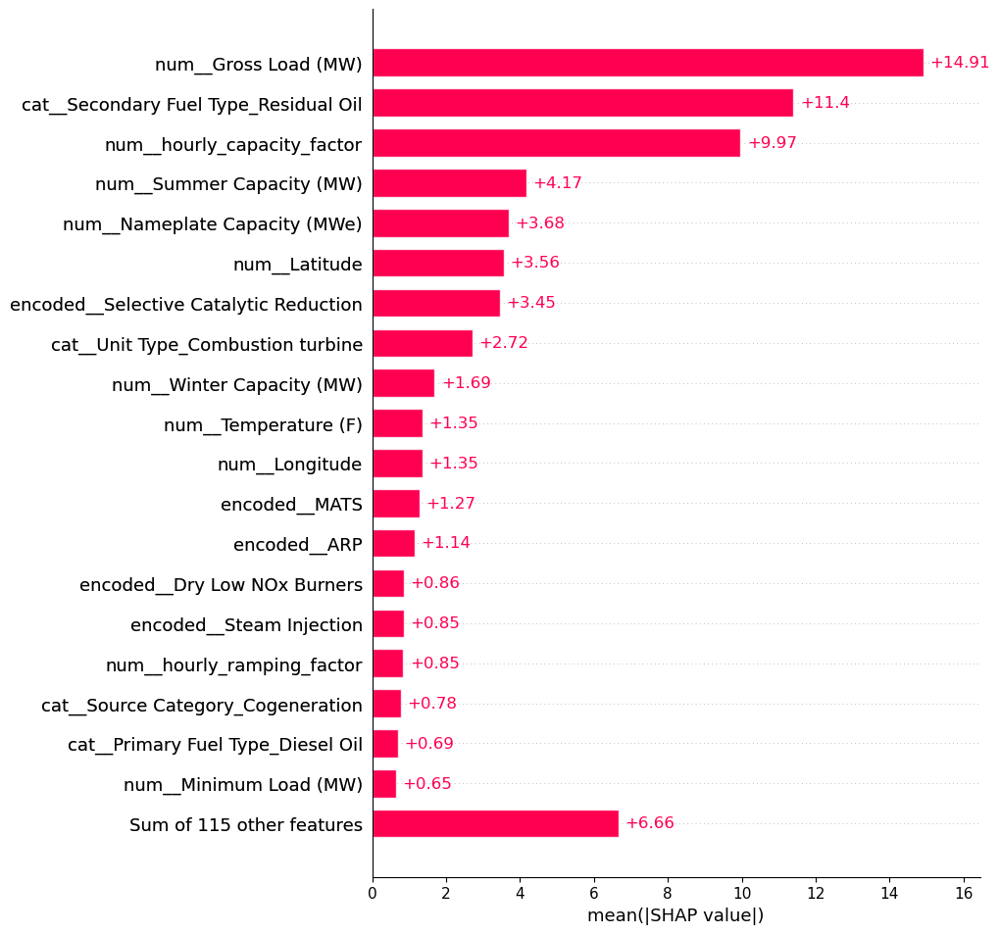

In [100]:
explainer = shap.TreeExplainer(xgb_default_model)
shap_values = explainer(X_test.drop(columns="num__Heat Input (mmBtu)"), approximate=False)
shap.plots.bar(shap_values, max_display=20)

R^2 Score: 0.9672
Mean Squared Error (MSE): 120.7082
Root Mean Squared Error (RMSE): 10.9867
Normalized RMSE (by std): 0.1811


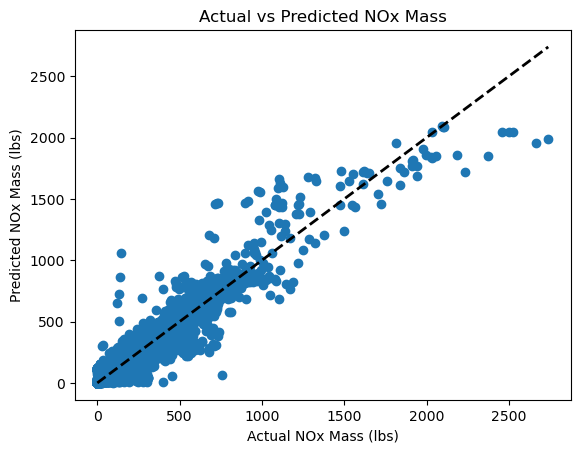

In [101]:
# model with default parameters (no lags, no unmeasured data, with temps)

xgb_default_model = xgb.train(params=default_params, dtrain=dtrain_no_GL, num_boost_round=100)

y_pred = xgb_default_model.predict(dtest_no_GL)

# set all predictions below 0 to 0
y_pred[y_pred < 0] = 0

y_test = dtest_no_GL.get_label() # get y_test from dmatrix

print(f"R^2 Score: {r2_score(y_test, y_pred):.4f}")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test, y_pred):.4f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")
print(f"Normalized RMSE (by std): {np.sqrt(mean_squared_error(y_test, y_pred)) / np.std(y_test):.4f}")

plt.scatter(y_test, y_pred)
plt.xlabel("Actual NOx Mass (lbs)")
plt.ylabel("Predicted NOx Mass (lbs)")
plt.title("Actual vs Predicted NOx Mass")
plt.plot([min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], 'k--', lw=2)
plt.show()

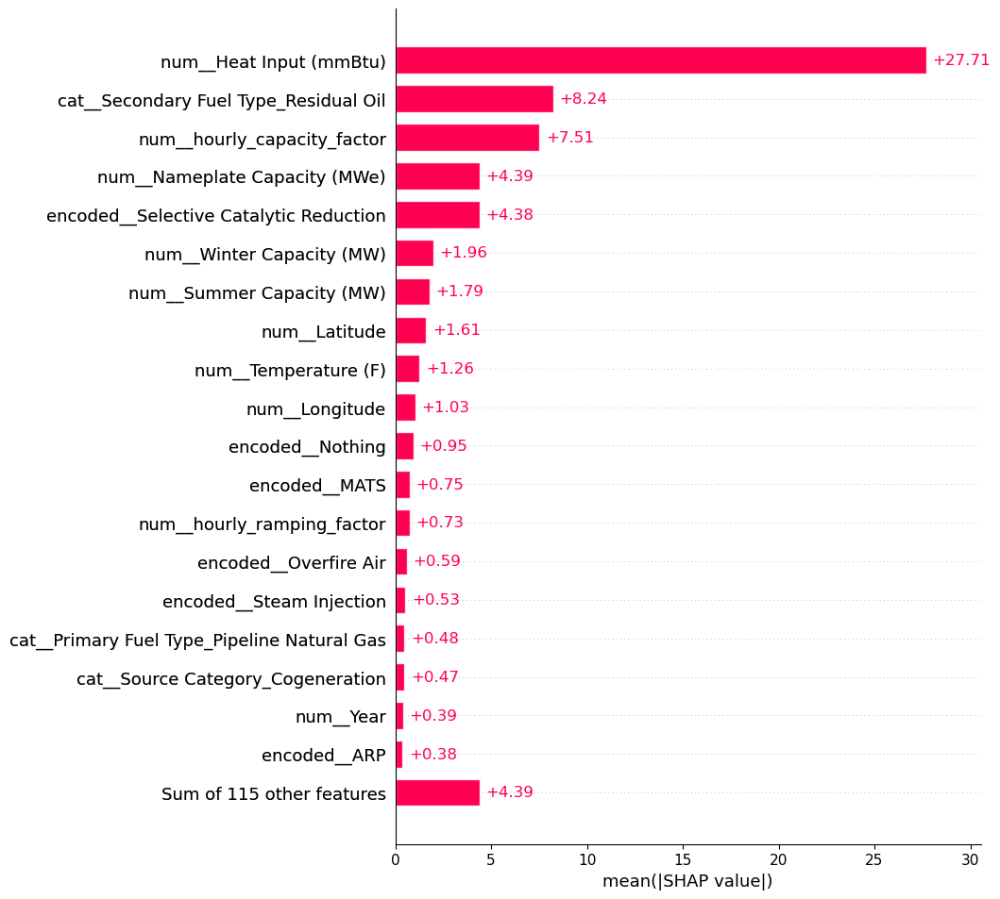

In [102]:
explainer = shap.TreeExplainer(xgb_default_model)
shap_values = explainer(X_test.drop(columns="num__Gross Load (MW)"), approximate=False)
shap.plots.bar(shap_values, max_display=20)

R^2 Score: 0.9681
Mean Squared Error (MSE): 117.4326
Root Mean Squared Error (RMSE): 10.8366
Normalized RMSE (by std): 0.1786


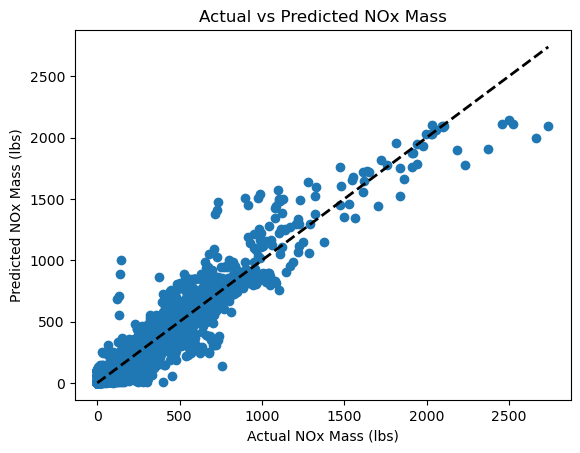

In [ ]:
# model with default parameters (no lags, no unmeasured data, with temps)

xgb_default_model = xgb.train(params=default_params, dtrain=dtrain, num_boost_round=100)

# dump model
xgb_default_model.save_model("NY/Hourly/Concatted File/Modeling/XGB/NOx/Trained Models/xgb_default_model_ny_no_lags_no_unmeasured_with_temps.json")

y_pred = xgb_default_model.predict(dtest)

# set all predictions below 0 to 0
y_pred[y_pred < 0] = 0

y_test = dtest.get_label() # get y_test from dmatrix

print(f"R^2 Score: {r2_score(y_test, y_pred):.4f}")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test, y_pred):.4f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")
print(f"Normalized RMSE (by std): {np.sqrt(mean_squared_error(y_test, y_pred)) / np.std(y_test):.4f}")

plt.scatter(y_test, y_pred)
plt.xlabel("Actual NOx Mass (lbs)")
plt.ylabel("Predicted NOx Mass (lbs)")
plt.title("Actual vs Predicted NOx Mass")
plt.plot([min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], 'k--', lw=2)
plt.show()

R^2 Score: 0.9829
Mean Squared Error (MSE): 62.9226
Root Mean Squared Error (RMSE): 7.9324
Normalized RMSE (by std): 0.1308


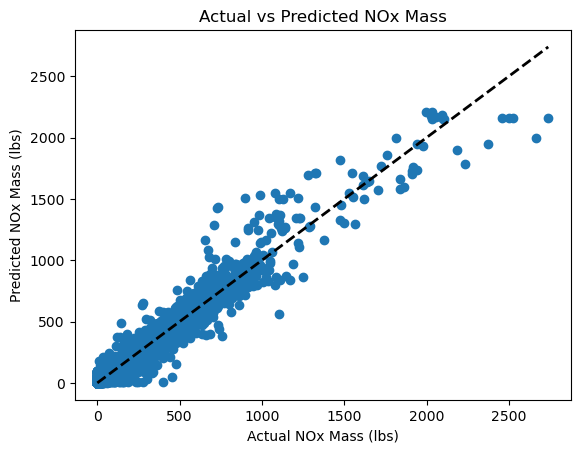

In [ ]:
# model with default parameters (with lags, no unmeasured data, with temps)

xgb_default_model = xgb.train(params=default_params, dtrain=dtrain, num_boost_round=100)

# dump model
xgb_default_model.save_model("NY/Hourly/Concatted File/Modeling/XGB/NOx/Trained Models/xgb_default_model_ny_with_lags_no_unmeasured_with_temps.json")

y_pred = xgb_default_model.predict(dtest)

# set all predictions below 0 to 0
y_pred[y_pred < 0] = 0

y_test = dtest.get_label() # get y_test from dmatrix

print(f"R^2 Score: {r2_score(y_test, y_pred):.4f}")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test, y_pred):.4f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")
print(f"Normalized RMSE (by std): {np.sqrt(mean_squared_error(y_test, y_pred)) / np.std(y_test):.4f}")

plt.scatter(y_test, y_pred)
plt.xlabel("Actual NOx Mass (lbs)")
plt.ylabel("Predicted NOx Mass (lbs)")
plt.title("Actual vs Predicted NOx Mass")
plt.plot([min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], 'k--', lw=2)
plt.show()

In [48]:
mask_below_500 = y_test < 500
mask_above_500 = y_test >= 500

print(f"RMSE for NOx Mass below 500 lbs: {np.sqrt(mean_squared_error(y_test[mask_below_500], y_pred[mask_below_500])):.4f}")
print(f"Normalized RMSE (by std): {np.sqrt(mean_squared_error(y_test[mask_below_500], y_pred[mask_below_500])) / np.std(y_test[mask_below_500]):.4f}")
print("")
print(f"RMSE for NOx Mass below 500 lbs: {np.sqrt(mean_squared_error(y_test[mask_above_500], y_pred[mask_above_500])):.4f}")
print(f"Normalized RMSE (by std): {np.sqrt(mean_squared_error(y_test[mask_above_500], y_pred[mask_above_500])) / np.std(y_test[mask_above_500]):.4f}")


RMSE for NOx Mass below 500 lbs: 5.7844
Normalized RMSE (by std): 0.1451

RMSE for NOx Mass below 500 lbs: 83.2018
Normalized RMSE (by std): 0.3920


excursion into ramping

In [52]:
full_pred_df = pd.concat([X_test, y_df], axis=1)
full_pred_df[["encoded__lag_1_hour","num__hourly_ramping_factor", "Test", "Pred"]].sort_values(by="num__hourly_ramping_factor", key=abs, ascending=False).head(10) # sort by absolute value of ramping

,encoded__lag_1_hour,num__hourly_ramping_factor,Test,Pred
371861,37.632,-1.619048,0.000000,0.000000
130576,22.236,-1.476190,0.000000,4.275095
158693,7.705,-1.428572,0.000000,0.570687
368937,4.416,1.190476,32.500000,31.849003
498181,14.325,-1.172222,17.950001,11.306944
431045,33.000,-1.071428,0.690000,0.000000
63574,3.200,-1.044444,0.000000,1.743948
502042,3.200,-1.044444,2.088000,1.843998
47428,4.000,-1.044444,2.064000,1.850520
486531,3.600,-1.044444,2.016000,1.216592


In [ ]:
top_ramping_df = full_pred_df[["encoded__lag_1_hour","num__hourly_ramping_factor", "Test", "Pred"]].sort_values(by="num__hourly_ramping_factor", ascending=False).head(1000)
rmse_top_ramping = np.sqrt(mean_squared_error(top_ramping_df["Test"], top_ramping_df["Pred"]))

print(f"R^2 for top ramping vals: {r2_score(top_ramping_df["Test"], top_ramping_df["Pred"]):.4f}")
print(f"RMSE for top ramping vals: {rmse_top_ramping:.4f}")

R^2 for top ramping vals: 0.7921
RMSE for top ramping vals: 6.1064


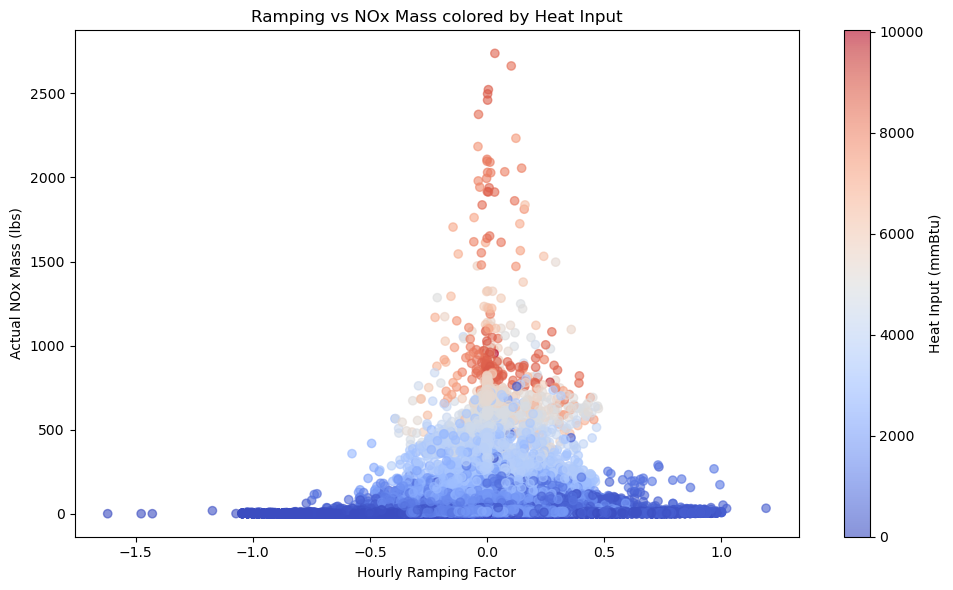

In [90]:
plt.figure(figsize=(10, 6))
sc = plt.scatter(
    full_pred_df["num__hourly_ramping_factor"], 
    full_pred_df["Test"], 
    c=full_pred_df["num__Heat Input (mmBtu)"], 
    cmap="coolwarm", 
    alpha=0.6
)

plt.xlabel("Hourly Ramping Factor")
plt.ylabel("Actual NOx Mass (lbs)")
plt.title("Ramping vs NOx Mass colored by Heat Input")
plt.colorbar(sc, label="Heat Input (mmBtu)")  
plt.tight_layout()
plt.show()

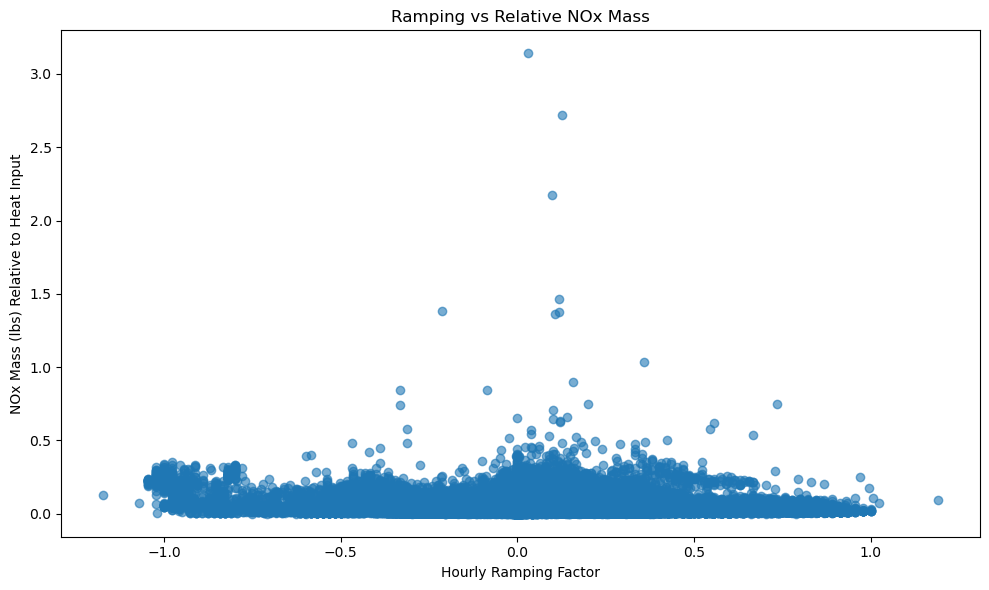

In [ ]:
plt.figure(figsize=(10, 6))
sc = plt.scatter(
    full_pred_df["num__hourly_ramping_factor"], 
    full_pred_df["Test"] / full_pred_df["num__Heat Input (mmBtu)"], 
    alpha=0.6
)

plt.xlabel("Hourly Ramping Factor")
plt.ylabel("NOx Mass (lbs) Relative to Heat Input")
plt.title("Ramping vs Relative NOx Mass")
plt.tight_layout()
plt.show()

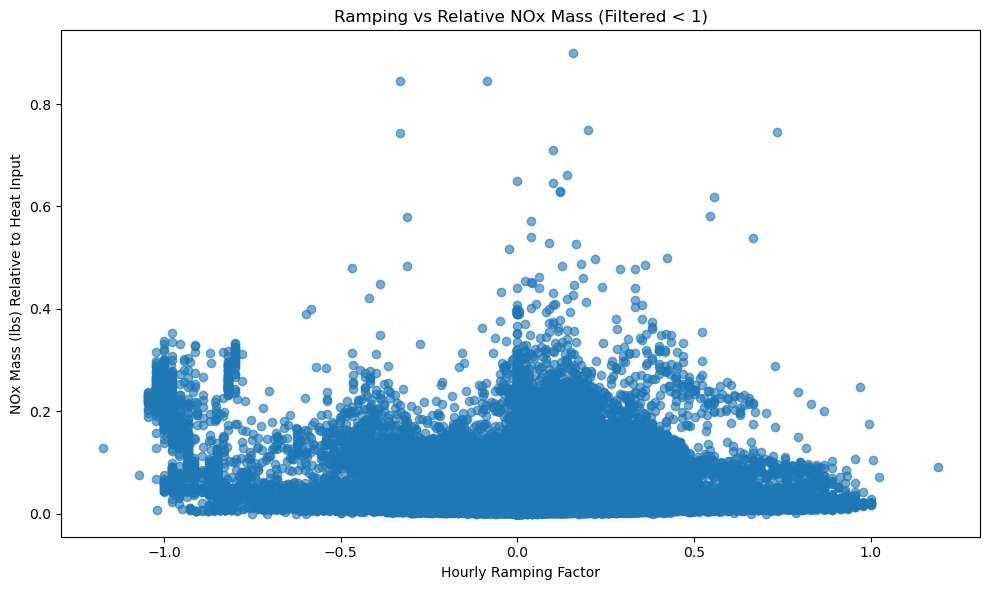

In [99]:
filtered_df = full_pred_df[
    (full_pred_df["Test"] / full_pred_df["num__Heat Input (mmBtu)"]) < 1
]

plt.figure(figsize=(10, 6))
sc = plt.scatter(
    filtered_df["num__hourly_ramping_factor"], 
    filtered_df["Test"] / filtered_df["num__Heat Input (mmBtu)"], 
    alpha=0.6
)

plt.xlabel("Hourly Ramping Factor")
plt.ylabel("NOx Mass (lbs) Relative to Heat Input")
plt.title("Ramping vs Relative NOx Mass (Filtered < 1)")
plt.tight_layout()
plt.show()

In [ ]:
# calc metrics across 10 fixed-width bins

full_pred_df["ramp_bin_fixed_width"] = pd.cut(full_pred_df["num__hourly_ramping_factor"], bins=10)

def compute_metrics(group):
    r2 = r2_score(group["Test"], group["Pred"])
    rmse = root_mean_squared_error(group["Test"], group["Pred"])
    count = len(group)
    mean_nox = np.mean(group["Test"])
    return pd.Series({"R2": r2, "RMSE": rmse, "Count": count, "Mean Test Emissions": mean_nox})

metrics_by_bin = (
    full_pred_df
    .groupby("ramp_bin_fixed_width")
    .apply(compute_metrics)
    .reset_index()
)

In [86]:
metrics_by_bin

,ramp_bin_fixed_width,R2,RMSE,Count,Mean Test Emissions
0,"(-1.622, -1.338]",0.000000,2.490122,3.0,0.000000
1,"(-1.338, -1.057]",0.700536,4.722621,2.0,9.320001
2,"(-1.057, -0.776]",-0.487048,1.436735,1411.0,1.061179
3,"(-0.776, -0.495]",0.868645,6.189381,1251.0,4.171484
4,"(-0.495, -0.214]",0.911735,18.812243,5969.0,36.788219
5,"(-0.214, 0.0667]",0.987105,6.801737,390164.0,19.430792
6,"(0.0667, 0.348]",0.966640,17.545080,28009.0,51.215557
7,"(0.348, 0.629]",0.953916,16.938181,3559.0,31.469406
8,"(0.629, 0.91]",0.713526,7.975979,2840.0,6.995909
9,"(0.91, 1.19]",0.939245,4.750748,269.0,9.684276


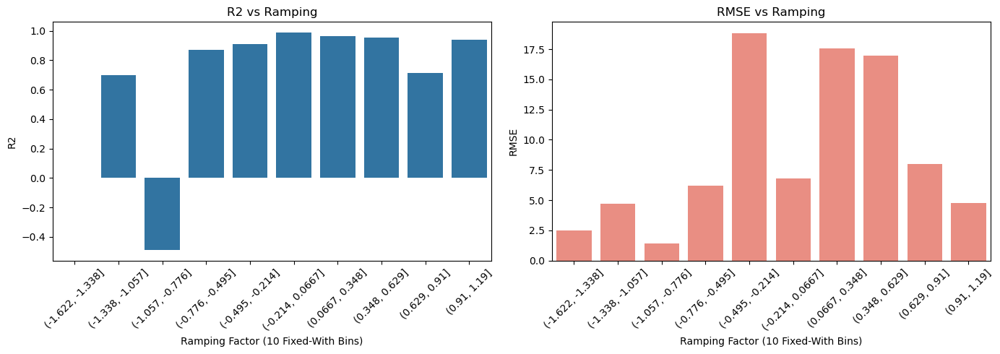

In [75]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharex=True)

sns.barplot(x=metrics_by_bin["ramp_bin_fixed_width"], y=metrics_by_bin["R2"], ax=axes[0])
axes[0].set_title("R2 vs Ramping")
axes[0].set_ylabel("R2")

sns.barplot(x=metrics_by_bin["ramp_bin_fixed_width"], y=metrics_by_bin["RMSE"], ax=axes[1], color="salmon")
axes[1].set_title("RMSE vs Ramping")
axes[1].set_ylabel("RMSE")

for ax in axes:
    ax.set_xlabel("Ramping Factor (10 Fixed-With Bins)")
    ax.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

In [ ]:
explainer = shap.TreeExplainer(xgb_default_model_with_lags)
shap_values = explainer(X_test, approximate=False)


# this took just 1 min

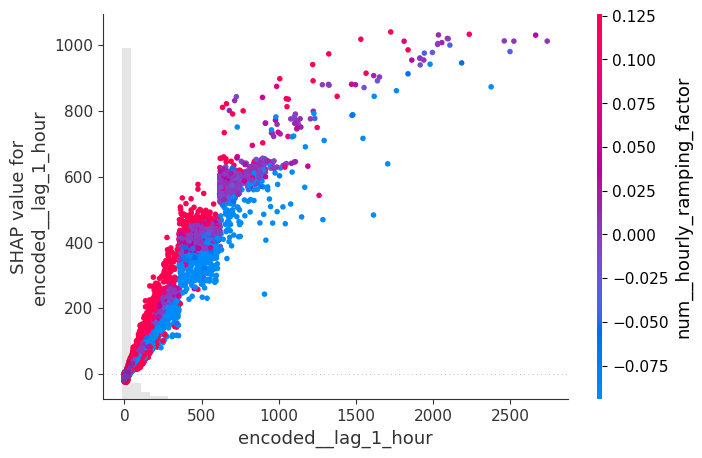

In [ ]:
shap.plots.scatter(shap_values[:, "encoded__lag_1_hour"], color=shap_values[:, "num__hourly_ramping_factor"])

# the "interpolation" of the 1 hour lag interacts with the ramping factor such that a higher factor increases the lag shap value
# (a sharp in-/decrease shifts it in the respective direction naturally)


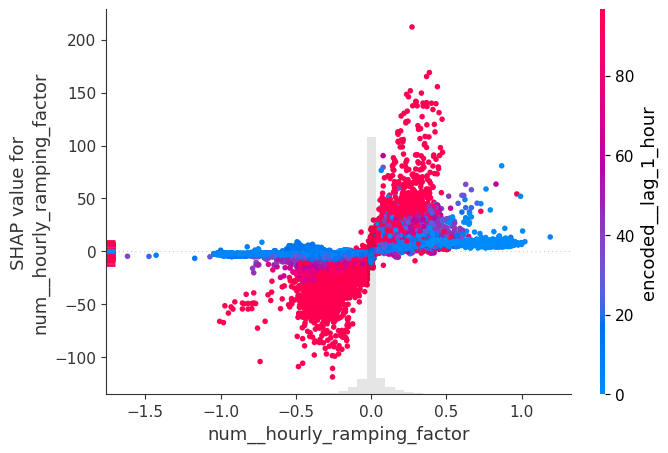

In [ ]:
shap.plots.scatter(shap_values[:, "num__hourly_ramping_factor"], color=shap_values[:, "encoded__lag_1_hour"])

# here, ramping factor becomes an immense predictor when lags do not tell the full story
# e. g. during start or shutdown, ramping interacts with lags (and HI, Gross Load etc)
# remember that we are predicting total mass and not the rate (relative to Heat Input), in that case we would expect a U-shape where start and shutdown both cause an increase in relative emissions

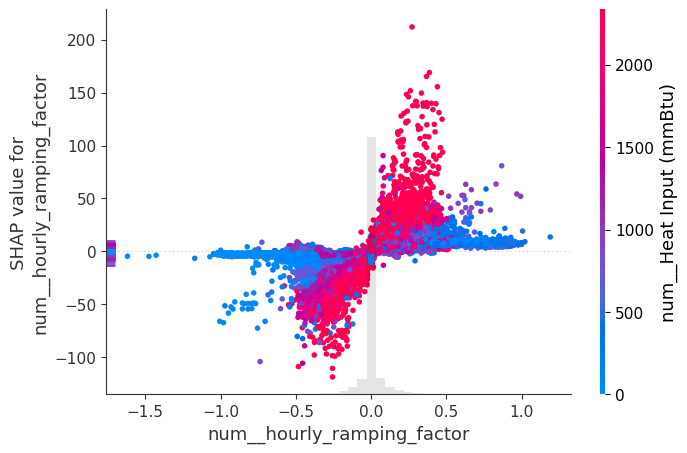

In [49]:
shap.plots.scatter(shap_values[:, "num__hourly_ramping_factor"], color=shap_values[:, "num__Heat Input (mmBtu)"])

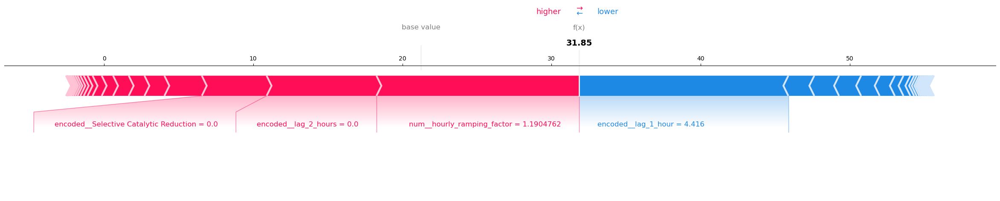

In [40]:
shap.plots.force(explainer(X_test.loc[[368937]]), matplotlib=True, contribution_threshold=0.1, figsize=(30,4))

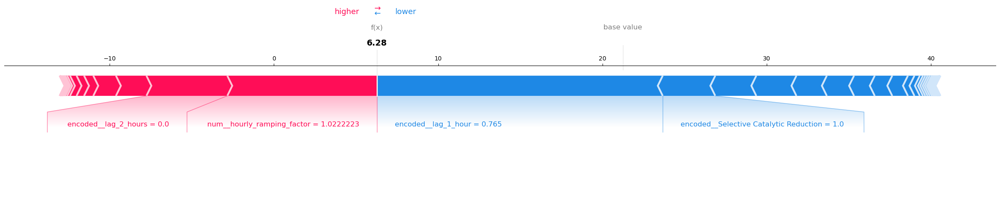

In [41]:
shap.plots.force(explainer(X_test.loc[[499592]]), matplotlib=True, contribution_threshold=0.1, figsize=(30,4))

<h5>Scenario Analysis</h5>

In [56]:
# use the default model with no lags, no unmeasured data, with temps to compare
y_pred_real = y_pred # prediction from model with real X_test


In [ ]:
y_pred_sum = sum(y_pred_real)
y_test_sum = sum(y_test)

print(f"Total Predicted NOx Mass (lbs): {y_pred_sum:.4f}")
print(f"Total Actual NOx Mass (lbs): {y_test_sum:.4f}")
print(f"Relative Difference: {(y_pred_sum - y_test_sum) / y_test_sum:.4%}")
print(f"Total Difference: {y_pred_sum - y_test_sum:.4f}")

# the original model miscalculates actual NOx sum by 0.76% which is reasonably low in relative terms
# about 83,000 lbs off in absolute terms

Total Predicted NOx Mass (lbs): 10945558.7010
Total Actual NOx Mass (lbs): 10862861.9763
Relative Difference: 0.7613%
Total Difference: 82696.7248


In [ ]:
# simulate all units having SCR in X_test (2024) and look at difference to prediction using real data
X_test_all_SCR = X_test
X_test_all_SCR["encoded__Selective Catalytic Reduction"] = 1
dtrain = xgb.DMatrix(X_train, label=y_train)
dtest_all_SCR = xgb.DMatrix(X_test_all_SCR, label=y_test)


In [ ]:
# model with default parameters (no short-term lags, no unmeasured data, with temps)

# predict on data with all SCR = 1

xgb_default_model = xgb.train(params=default_params, dtrain=dtrain, num_boost_round=100)

y_pred_all_scr = xgb_default_model.predict(dtest_all_SCR)

# set all predictions below 0 to 0
y_pred_all_scr[y_pred_all_scr < 0] = 0

In [ ]:
# Difference between real prediction and prediction with all SCR
print(f"Relative Difference: {(y_pred_real.sum() - y_pred_all_scr.sum()) / y_pred_real.sum():.4%}")
print(f"Total Difference: {y_pred_real.sum() - y_pred_all_scr.sum():.4f}")

Relative Difference: 9.3750%
Total Difference: 1026151.0000


<h5>Transferability Tests</h5>

In [ ]:
# use NY model to predict TX emissions

In [ ]:
campd_tx = pd.read_csv("TX/Hourly/Concatted File/Modeling/XGB/NOx/tx_2019_2024_complete_cleaned_Full_manually_encoded_downsampled_only_measured.gz", dtype=campd_type_dict)

In [6]:
X_test_tx = pd.read_csv("TX/Hourly/Concatted File/Modeling/XGB/NOx/X_test_processed.gz", dtype=campd_type_dict)
y_test_tx = pd.read_csv("TX/Hourly/Concatted File/Modeling/XGB/NOx/y_test.gz")

In [ ]:
print("NY - by Unit Type and Primary Fuel Type:")
display(
    campd_df.groupby(["Unit Type", "Primary Fuel Type"])["NOx Mass (lbs)"]
    .sum()
    #.sort_values(ascending=False)
)

print("TX - by Unit Type and Primary Fuel Type:")
display(
    campd_tx.groupby(["Unit Type", "Primary Fuel Type"])["NOx Mass (lbs)"]
    .sum()
    #.sort_values(ascending=False)
)


NY - by Unit Type and Primary Fuel Type:


Unit Type                              Primary Fuel Type   
Circulating fluidized bed boiler       Wood                    2508647.75
Combined cycle                         Pipeline Natural Gas   21837738.00
Combined cycle (Started Feb 23, 2020)  Pipeline Natural Gas      46284.04
Combustion turbine                     Diesel Oil               414186.25
                                       Other Oil                     0.00
                                       Pipeline Natural Gas    2250384.50
Dry bottom wall-fired boiler           Coal                    1255641.12
                                       Natural Gas                   0.00
                                       Pipeline Natural Gas   10115554.00
                                       Residual Oil             678843.56
Other boiler                           Pipeline Natural Gas          0.00
Tangentially-fired                     Coal                     273577.97
                                       Natural Gas  

TX - by Unit Type and Primary Fuel Type:


Unit Type                         Primary Fuel Type   
Bubbling fluidized bed boiler     Wood                     1483502.75
Circulating fluidized bed boiler  Coal                    23344982.00
Combined cycle                    Natural Gas              1485804.38
                                  Other Gas                1664143.62
                                  Pipeline Natural Gas   175227968.00
Combustion turbine                Natural Gas               857225.62
                                  Pipeline Natural Gas    14169771.00
Dry bottom wall-fired boiler      Coal                   174859616.00
                                  Natural Gas                 3571.64
                                  Pipeline Natural Gas    83874632.00
Nothing                           Pipeline Natural Gas           0.00
Tangentially-fired                Coal                   416862464.00
                                  Pipeline Natural Gas    93228952.00
Name: NOx Mass (lbs), dtype: float3

In [ ]:
# only looking at pipeline natural gas combinations

print("NY - by Unit Type and Primary Fuel Type:")
display(
    campd_df[campd_df["Primary Fuel Type"] == "Pipeline Natural Gas"].groupby(["Unit Type", "Primary Fuel Type"])["NOx Mass (lbs)"]
    .sum()
    #.sort_values(ascending=False)
)

print("TX - by Unit Type and Primary Fuel Type:")
display(
    campd_tx[campd_tx["Primary Fuel Type"] == "Pipeline Natural Gas"].groupby(["Unit Type", "Primary Fuel Type"])["NOx Mass (lbs)"]
    .sum()
    #.sort_values(ascending=False)
)


NY - by Unit Type and Primary Fuel Type:


Unit Type                              Primary Fuel Type   
Combined cycle                         Pipeline Natural Gas   21837738.00
Combined cycle (Started Feb 23, 2020)  Pipeline Natural Gas      46284.04
Combustion turbine                     Pipeline Natural Gas    2250384.50
Dry bottom wall-fired boiler           Pipeline Natural Gas   10115554.00
Other boiler                           Pipeline Natural Gas          0.00
Tangentially-fired                     Pipeline Natural Gas   25955590.00
Name: NOx Mass (lbs), dtype: float32

TX - by Unit Type and Primary Fuel Type:


Unit Type                     Primary Fuel Type   
Combined cycle                Pipeline Natural Gas   175227968.00
Combustion turbine            Pipeline Natural Gas    14169771.00
Dry bottom wall-fired boiler  Pipeline Natural Gas    83874632.00
Nothing                       Pipeline Natural Gas           0.00
Tangentially-fired            Pipeline Natural Gas    93228952.00
Name: NOx Mass (lbs), dtype: float32

In [ ]:
pd.set_option('display.float_format', '{:.2f}'.format)

print("NY:")
display(campd_df.groupby(by="Unit Type")["NOx Mass (lbs)"].sum().sort_values(ascending=False))

display(campd_df.groupby(by="Primary Fuel Type")["NOx Mass (lbs)"].sum().sort_values(ascending=False))

print("TX:")
display(campd_tx.groupby(by="Unit Type")["NOx Mass (lbs)"].sum().sort_values(ascending=False))

display(campd_tx.groupby(by="Primary Fuel Type")["NOx Mass (lbs)"].sum().sort_values(ascending=False))


NY:


Unit Type
Tangentially-fired                      28829376.00
Combined cycle                          21837738.00
Dry bottom wall-fired boiler            12050039.00
Combustion turbine                       2664570.75
Circulating fluidized bed boiler         2508647.75
Combined cycle (Started Feb 23, 2020)      46284.04
Other boiler                                   0.00
Name: NOx Mass (lbs), dtype: float32

Primary Fuel Type
Pipeline Natural Gas   60205552.00
Residual Oil            3279051.00
Wood                    2508647.75
Coal                    1529219.12
Diesel Oil               414186.25
Natural Gas                   0.00
Other Oil                     0.00
Name: NOx Mass (lbs), dtype: float32

TX:


Unit Type
Tangentially-fired                 510091392.00
Dry bottom wall-fired boiler       258737808.00
Combined cycle                     178377920.00
Circulating fluidized bed boiler    23344982.00
Combustion turbine                  15026997.00
Bubbling fluidized bed boiler        1483502.75
Nothing                                    0.00
Name: NOx Mass (lbs), dtype: float32

Primary Fuel Type
Coal                   615067072.00
Pipeline Natural Gas   366501312.00
Natural Gas              2346601.50
Other Gas                1664143.62
Wood                     1483502.75
Name: NOx Mass (lbs), dtype: float32

In [9]:
xgb_default_model_no_lags = xgb.Booster()
xgb_default_model_no_lags.load_model("NY/Hourly/Concatted File/Modeling/XGB/NOx/Trained Models/xgb_default_model_ny_no_lags_no_unmeasured_with_temps.json")

In [10]:
encoded_lag_cols = [
    "encoded__lag_1_hour",
    "encoded__lag_2_hours",
    "encoded__lag_1_day",
    "encoded__lag_2_days",
    "encoded__lag_1_week",
    "encoded__lag_1_month",
    "encoded__lag_1_year"
       ]

X_test_tx = X_test_tx.drop(columns=encoded_lag_cols)

In [ ]:
# mostly consists of secondary fuel types

print("Columns only in tx, not ny")
print(set(X_test_tx.columns) - set(xgb_default_model_no_lags.feature_names))

Columns only in tx, not ny
{'cat__Secondary Fuel Type_Diesel Oil, Other Solid Fuel', 'cat__Secondary Fuel Type_Other Gas', 'encoded__Dry Low NOx Burners (Began Aug 03, 2022)', 'encoded__Dry Low NOx Burners (Began Jul 01, 2024)', 'cat__Secondary Fuel Type_Diesel Oil, Residual Oil', 'encoded__TXSO2', 'encoded__Steam Injection (Retired Jun 30, 2024)', 'cat__Secondary Fuel Type_Process Gas', 'cat__Unit Type_Nothing', 'encoded__Steam Injection (Retired Aug 02, 2022)', 'cat__Unit Type_Bubbling fluidized bed boiler', 'cat__Secondary Fuel Type_Diesel Oil, Other Oil', 'cat__Primary Fuel Type_Other Gas', 'cat__Secondary Fuel Type_Other Gas, Process Gas'}


In [63]:
# adjust columns such that tx has the same features as ny, if a (categorical) column exists in ny, but not tx we set it 0 for all rows

ny_features = xgb_default_model_no_lags.feature_names
tx_features = X_test_tx.columns.tolist()

X_test_tx_adjusted = X_test_tx.copy()

# Features to add (with 0s)
features_to_add = list(set(ny_features) - set(tx_features)) # features in ny, but not tx
for feature in features_to_add:
    X_test_tx_adjusted[feature] = 0

# Features to drop
features_to_drop = list(set(tx_features) - set(ny_features)) # features in tx, but not ny
X_test_tx_adjusted.drop(columns=features_to_drop, inplace=True)

# Reorder the columns to match ny_features
X_test_tx_adjusted = X_test_tx_adjusted[ny_features]

In [17]:
shared_unit_types = list(set(campd_tx["Unit Type"]).intersection(set(campd_df["Unit Type"].unique())))
print(shared_unit_types)

['Circulating fluidized bed boiler', 'Dry bottom wall-fired boiler', 'Combined cycle', 'Tangentially-fired', 'Combustion turbine']


In [101]:
# filter tx data to only include units part of ny training data
X_test_tx_adjusted_filtered = X_test_tx_adjusted[
    (X_test_tx_adjusted["cat__Unit Type_Tangentially-fired"] == 1) |
    (X_test_tx_adjusted["cat__Unit Type_Combustion turbine"] == 1) |
    (X_test_tx_adjusted["cat__Unit Type_Dry bottom wall-fired boiler"] == 1) |
    (X_test_tx_adjusted["cat__Unit Type_Circulating fluidized bed boiler"] == 1) |
    (X_test_tx_adjusted["cat__Unit Type_Combined cycle"] == 1)
]

y_test_tx_filtered = y_test_tx[X_test_tx_adjusted_filtered.index]

In [37]:
shared_fuel_types = list(set(campd_tx["Primary Fuel Type"]).intersection(set(campd_df["Primary Fuel Type"].unique())))
print(shared_fuel_types)

['Pipeline Natural Gas', 'Coal', 'Wood', 'Natural Gas']


In [106]:
# Filter TX data to only include pipeline natural gas

X_test_tx_adjusted_filtered = X_test_tx_adjusted_filtered[
    (X_test_tx_adjusted_filtered["cat__Primary Fuel Type_Pipeline Natural Gas"] == 1) &
    (X_test_tx_adjusted_filtered["cat__Primary Fuel Type_Coal"] == 0) &
    (X_test_tx_adjusted_filtered["cat__Primary Fuel Type_Wood"] == 0) &
    (X_test_tx_adjusted_filtered["cat__Primary Fuel Type_Natural Gas"] == 0)
]

y_test_tx_filtered = y_test_tx_filtered[X_test_tx_adjusted_filtered.index]

In [ ]:
X_test_tx_adjusted.shape[0] - X_test_tx_adjusted_filtered.shape[0]

# removed no of rows for filtered test set

238443

In [85]:
dtest_tx_adjusted = xgb.DMatrix(X_test_tx_adjusted, label=y_test_tx)
dtest_tx_adjusted_filtered = xgb.DMatrix(X_test_tx_adjusted_filtered, label=y_test_tx_filtered)

R^2 Score: 0.1330
Mean Squared Error (MSE): 36557.9648
Root Mean Squared Error (RMSE): 191.2014
Normalized RMSE (by std): 0.9311


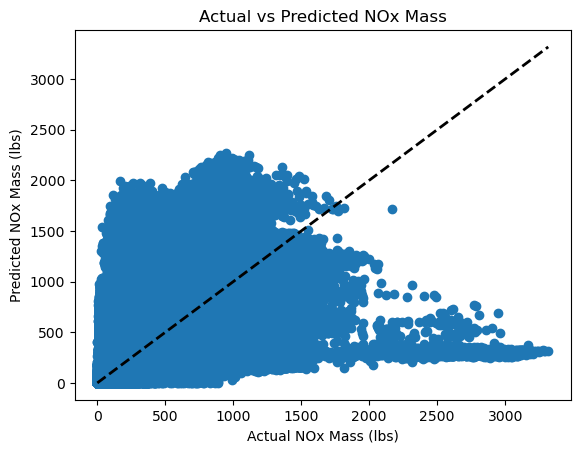

In [34]:
# model with default parameters (no lags, no unmeasured data, with temps)

y_pred = xgb_default_model_no_lags.predict(dtest_tx_adjusted)

# set all predictions below 0 to 0
y_pred[y_pred < 0] = 0

y_test = dtest_tx_adjusted.get_label() # get y_test from dmatrix

print(f"R^2 Score: {r2_score(y_test, y_pred):.4f}")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test, y_pred):.4f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")
print(f"Normalized RMSE (by std): {np.sqrt(mean_squared_error(y_test, y_pred)) / np.std(y_test):.4f}")

plt.scatter(y_test, y_pred)
plt.xlabel("Actual NOx Mass (lbs)")
plt.ylabel("Predicted NOx Mass (lbs)")
plt.title("Actual vs Predicted NOx Mass")
plt.plot([min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], 'k--', lw=2)
plt.show()

In [141]:
campd_tx["NOx Mass (lbs)"].describe()

count   9758706.00
mean        101.15
std         208.90
min           0.00
25%          10.80
50%          25.10
75%          61.70
max        8746.60
Name: NOx Mass (lbs), dtype: float64

In [140]:
campd_df["NOx Mass (lbs)"].describe()

count   3197828.00
mean         21.24
std          60.45
min           0.00
25%           0.00
50%           7.60
75%          14.80
max        2738.50
Name: NOx Mass (lbs), dtype: float64

R^2 Score: 0.0787
Mean Squared Error (MSE): 15897.1318
Root Mean Squared Error (RMSE): 126.0838
Normalized RMSE (by std): 0.9599


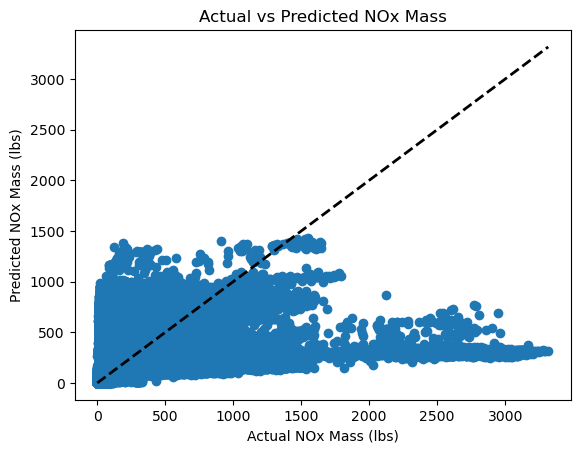

In [ ]:
# model with default parameters (no lags, no unmeasured data, with temps)

# only on TX pipeline natural gas data

y_pred = xgb_default_model_no_lags.predict(dtest_tx_adjusted_filtered)

# set all predictions below 0 to 0
y_pred[y_pred < 0] = 0

y_test = dtest_tx_adjusted_filtered.get_label() # get y_test from dmatrix

print(f"R^2 Score: {r2_score(y_test, y_pred):.4f}")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test, y_pred):.4f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")
print(f"Normalized RMSE (by std): {np.sqrt(mean_squared_error(y_test, y_pred)) / np.std(y_test):.4f}")

plt.scatter(y_test, y_pred)
plt.xlabel("Actual NOx Mass (lbs)")
plt.ylabel("Predicted NOx Mass (lbs)")
plt.title("Actual vs Predicted NOx Mass")
plt.plot([min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], 'k--', lw=2)
plt.show()

In [ ]:
# Filter original dataset and add predictions to look at how the NY model performs over time

campd_tx_filtered = campd_tx[(campd_tx["Unit Type"].isin(["Tangentially-fired", "Combustion turbine", "Dry bottom wall-fired boiler", 
                                      "Circulating fluidized bed boiler", "Combined cycle"]) 
                                    ) & (campd_tx["Primary Fuel Type"] == "Pipeline Natural Gas") & (campd_tx["Year"] == 2024)]

In [126]:
campd_tx_filtered = campd_tx_filtered.reset_index(drop=True)
y_test_tx_filtered = y_test_tx_filtered.reset_index(drop=True)

campd_tx_filtered["Y_test"] = y_test_tx_filtered
campd_tx_filtered["Y_pred"] = y_pred

In [128]:
campd_tx_filtered[["datetime","NOx Mass (lbs)", "Y_test", "Y_pred"]]

,datetime,NOx Mass (lbs),Y_test,Y_pred
0,2024-01-01 00:00:00,0.00,0.00,0.00
1,2024-01-01 00:00:00,21.30,21.30,22.28
2,2024-01-01 00:00:00,159.60,159.60,58.89
3,2024-01-01 00:00:00,122.10,122.10,57.88
4,2024-01-01 00:00:00,98.30,98.30,54.40
...,...,...,...,...
1481732,2024-12-31 23:00:00,21.10,21.10,866.90
1481733,2024-12-31 23:00:00,0.00,0.00,0.00
1481734,2024-12-31 23:00:00,0.00,0.00,0.00
1481735,2024-12-31 23:00:00,0.00,0.00,0.00


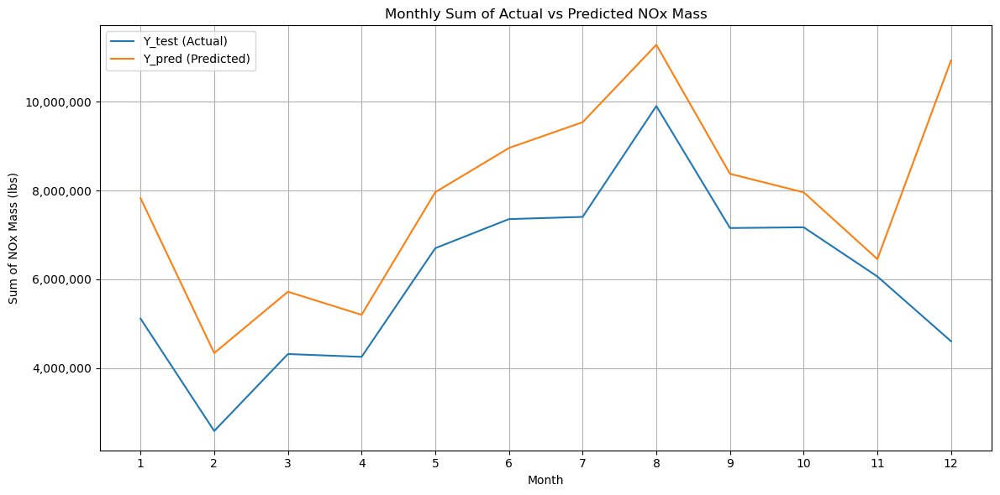

In [ ]:
campd_tx_filtered['datetime'] = pd.to_datetime(campd_tx_filtered['datetime'])

monthly_sum = campd_tx_filtered.groupby(campd_tx_filtered['datetime'].dt.month)[
    ["NOx Mass (lbs)", "Y_test", "Y_pred"]
].sum().reset_index()

plt.figure(figsize=(12,6))

plt.plot(monthly_sum['datetime'], monthly_sum['Y_test'], label='Y_test (Actual)')
plt.plot(monthly_sum['datetime'], monthly_sum['Y_pred'], label='Y_pred (Predicted)')

plt.xlabel('Month')
plt.xticks(range(1, 13))
plt.ylabel('Sum of NOx Mass (lbs)')
plt.title('Monthly Sum of Actual vs Predicted NOx Mass')

plt.legend()
plt.grid(True)

# Format y-axis ticks with commas
ax = plt.gca()
ax.yaxis.set_major_formatter(FuncFormatter(lambda x, _: f'{int(x):,}'))

plt.tight_layout()
plt.show()

# the model consistently underestimates, though trends are largely similar except for the end of the year

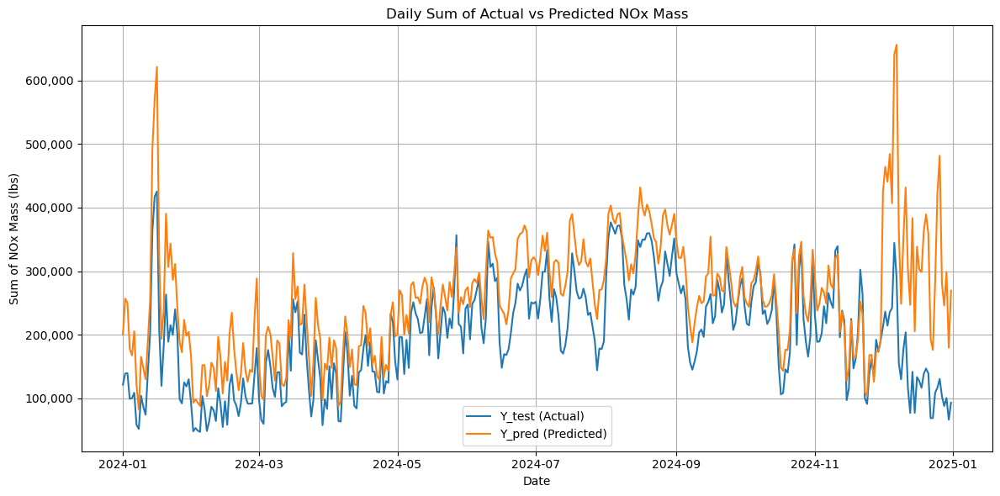

In [ ]:
daily_sum = campd_tx_filtered.groupby(campd_tx_filtered['datetime'].dt.date)[
    ["NOx Mass (lbs)", "Y_test", "Y_pred"]
].sum().reset_index()


plt.figure(figsize=(12,6))

plt.plot(daily_sum['datetime'], daily_sum['Y_test'], label='Y_test (Actual)')
plt.plot(daily_sum['datetime'], daily_sum['Y_pred'], label='Y_pred (Predicted)')

plt.xlabel('Date')
plt.ylabel('Sum of NOx Mass (lbs)')
plt.title('Daily Sum of Actual vs Predicted NOx Mass')
plt.legend()
plt.grid(True)

# Format y-axis ticks with commas
ax = plt.gca()
ax.yaxis.set_major_formatter(FuncFormatter(lambda x, _: f'{int(x):,}'))

plt.tight_layout()
plt.show()


<h5>HPO</h5>

<h6>Optuna Trials</h6>

In [4]:
# default parameters for comparison
# optimization has bias variance tradeoff, see documentation: https://xgboost.readthedocs.io/en/stable/tutorials/param_tuning.html

default_params = {
    # "n_estimators": 100, # number of trees (larger value, more likely to overfit)
    # "max_depth":  6, # max depth of a tree (larger value, more complex, more likely to overfit)
    # "learning_rate": 0.5, # step size shrinkage eta (lower value, more conservative)
    # "subsample": 1, # random subset size of data to use for each tree (lower value, more conservative)
    # "colsample_bytree": 1, # random subset of features to consider for each tree (lower value, more conservative)
    # "gamma": 0, # min loss reduction to make a split (larger value, more conservative)
    # "reg_alpha": 0, # L1 regularization on weights (larger value, more conservative)
    # "reg_lambda": 1, # L2 regularization on weights (larger value, more conservative)
    # "min_child_weight": 1, # min sum of instance weight (hessian) needed in a child (larger value, more conservative)
    # "tree_method": "auto" # automatically chooses exact or approximation method based on data size

    # needed params for xgb.train
    "objective": "reg:squarederror",
    'eval_metric': 'rmse',
    #"device": "cuda", # use gpu (if unavailable, will use cpu)
    'seed': 42 # like random_state, but for xgb.train
}

In [5]:
# objective function for optuna
def objective(trial):
    print(f"Starting trial {trial.number}")

    params = {
        "max_depth": trial.suggest_int("max_depth", 4, 25),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.25),
        "subsample": trial.suggest_float("subsample", 0.3, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.7, 1.0),
        "gamma": trial.suggest_float("gamma", 0, 0.5),
        "reg_alpha": trial.suggest_float("reg_alpha", 0, 0.2),
        "reg_lambda": trial.suggest_float("reg_lambda", 0.1, 6.0),
        "min_child_weight": trial.suggest_int("min_child_weight", 1, 15),
        "objective": "reg:squarederror",
        "eval_metric": "rmse"
        }

    tscv = TimeSeriesSplit(n_splits=5)
    rmse_folds = []
    best_iterations = []

    for fold, (train_idx, test_idx) in enumerate(tscv.split(X_train)):
        current_X_train, current_X_test = X_train.iloc[train_idx], X_train.iloc[test_idx]
        current_y_train, current_y_test = y_train.iloc[train_idx], y_train.iloc[test_idx]

        current_dtrain = xgb.DMatrix(current_X_train, label=current_y_train)
        current_dtest = xgb.DMatrix(current_X_test, label=current_y_test)

        evals_result = {}
        model = xgb.train(
            params,
            current_dtrain,
            num_boost_round=1000,
            evals=[(current_dtest, "validation")],
            early_stopping_rounds=20,
            verbose_eval=False, # prevents printing at each boosting stage
            evals_result=evals_result
        )

        best_iterations.append(model.best_iteration)
        # Get last RMSE from evals_result
        fold_rmse = evals_result["validation"]["rmse"][model.best_iteration - 1] # (0-indexed)
        rmse_folds.append(fold_rmse)

        print(f"Fold {fold+1} rmse: {fold_rmse:.4f} best_iteration: {model.best_iteration}")

    avg_rmse = np.mean(rmse_folds)
    avg_best_iter = int(np.mean(best_iterations))

    print(f"Trial {trial.number} avg RMSE: {avg_rmse:.4f}, avg best_iteration: {avg_best_iter}")

    # manually store the avg best boosting rounds and full list of rmse folds (we output the avg rmse separately)
    trial.set_user_attr("best_iteration", avg_best_iter)
    trial.set_user_attr("fold_rmses", rmse_folds)

    return avg_rmse


In [11]:
study = optuna.create_study(study_name="HPT 14.07.25 12:45", storage="sqlite:///optuna_studies.db", direction="minimize")
study.optimize(objective, n_trials=50) 
print("Best params:", study.best_params)

[I 2025-07-14 12:46:01,108] A new study created in RDB with name: HPT 14.07.25 12:45


Starting trial 0
Fold 1 rmse: 12.1556 best_iteration: 90
Fold 2 rmse: 13.9257 best_iteration: 68
Fold 3 rmse: 18.0070 best_iteration: 58
Fold 4 rmse: 15.6120 best_iteration: 89
Fold 5 rmse: 10.5280 best_iteration: 87
Trial 0 avg RMSE: 14.0456, avg best_iteration: 78


[I 2025-07-14 12:47:46,875] Trial 0 finished with value: 14.045640649843396 and parameters: {'max_depth': 6, 'learning_rate': 0.2226532556974822, 'subsample': 0.43950119217824357, 'colsample_bytree': 0.8455943925076057, 'gamma': 0.37975852167307994, 'reg_alpha': 0.12435929487649773, 'reg_lambda': 5.844394357954579, 'min_child_weight': 8}. Best is trial 0 with value: 14.045640649843396.


Starting trial 1
Fold 1 rmse: 12.1404 best_iteration: 78
Fold 2 rmse: 13.7137 best_iteration: 40
Fold 3 rmse: 16.9376 best_iteration: 29
Fold 4 rmse: 14.9755 best_iteration: 31
Fold 5 rmse: 10.2322 best_iteration: 35
Trial 1 avg RMSE: 13.5999, avg best_iteration: 42


[I 2025-07-14 12:49:18,748] Trial 1 finished with value: 13.599896228626116 and parameters: {'max_depth': 14, 'learning_rate': 0.18395333016154417, 'subsample': 0.5544391117330754, 'colsample_bytree': 0.9832331761436925, 'gamma': 0.3345142582830209, 'reg_alpha': 0.048989690418669386, 'reg_lambda': 3.117938521577432, 'min_child_weight': 13}. Best is trial 1 with value: 13.599896228626116.


Starting trial 2
Fold 1 rmse: 12.0318 best_iteration: 57
Fold 2 rmse: 13.5814 best_iteration: 32
Fold 3 rmse: 17.3921 best_iteration: 24
Fold 4 rmse: 14.8960 best_iteration: 27
Fold 5 rmse: 10.3253 best_iteration: 20
Trial 2 avg RMSE: 13.6453, avg best_iteration: 32


... (92 outputs left out)

[I 2025-07-14 16:42:39,126] Trial 48 finished with value: 13.435184275955535 and parameters: {'max_depth': 9, 'learning_rate': 0.03669319662694954, 'subsample': 0.3056076179291112, 'colsample_bytree': 0.9682946932327363, 'gamma': 0.40296869773002925, 'reg_alpha': 0.027058541771413203, 'reg_lambda': 1.4729384560944307, 'min_child_weight': 15}. Best is trial 37 with value: 13.243242756636992.


Starting trial 49
Fold 1 rmse: 12.0327 best_iteration: 422
Fold 2 rmse: 13.4152 best_iteration: 343
Fold 3 rmse: 16.7370 best_iteration: 395
Fold 4 rmse: 14.4272 best_iteration: 249
Fold 5 rmse: 9.8322 best_iteration: 416
Trial 49 avg RMSE: 13.2888, avg best_iteration: 365


[I 2025-07-14 16:50:37,149] Trial 49 finished with value: 13.288829276775392 and parameters: {'max_depth': 12, 'learning_rate': 0.01614469903830295, 'subsample': 0.33704135631692844, 'colsample_bytree': 0.9385903617299025, 'gamma': 0.4725227245566479, 'reg_alpha': 0.00796245027230531, 'reg_lambda': 0.1800669823876878, 'min_child_weight': 9}. Best is trial 37 with value: 13.243242756636992.


Best params: {'max_depth': 15, 'learning_rate': 0.026674106865370917, 'subsample': 0.5039738597255868, 'colsample_bytree': 0.854449947986361, 'gamma': 0.4744678310260708, 'reg_alpha': 0.04472171913014087, 'reg_lambda': 0.7832131243941791, 'min_child_weight': 12}


In [13]:
study = optuna.load_study(
    study_name="HPT 14.07.25 12:45", 
    storage="sqlite:///optuna_studies.db"
)

# Get the best 5 trials
sorted_trials = sorted(
    [t for t in study.trials if t.value is not None], 
    key=lambda t: t.value
)

for i, trial in enumerate(sorted_trials[:5], 1):
    print(f"\nTrial {i}:")
    print(f"  Value (Objective): {trial.value}")
    print(f"  Number: {trial.number}")
    print(f"  Params:")
    for key, val in trial.params.items():
        print(f"    {key}: {val}")
    print(f"best_iteration: {trial.user_attrs.get("best_iteration")}")


Trial 1:
  Value (Objective): 13.243242756636992
  Number: 37
  Params:
    max_depth: 15
    learning_rate: 0.026674106865370917
    subsample: 0.5039738597255868
    colsample_bytree: 0.854449947986361
    gamma: 0.4744678310260708
    reg_alpha: 0.04472171913014087
    reg_lambda: 0.7832131243941791
    min_child_weight: 12
best_iteration: 235

Trial 2:
  Value (Objective): 13.254512784314983
  Number: 36
  Params:
    max_depth: 14
    learning_rate: 0.026858179435223867
    subsample: 0.5149772363406635
    colsample_bytree: 0.856216656145951
    gamma: 0.4634789467807331
    reg_alpha: 0.03755197839802418
    reg_lambda: 1.6563556154913386
    min_child_weight: 12
best_iteration: 269

Trial 3:
  Value (Objective): 13.263874621068435
  Number: 46
  Params:
    max_depth: 12
    learning_rate: 0.016061124651689733
    subsample: 0.3068567646627661
    colsample_bytree: 0.9284687424987255
    gamma: 0.43609659298369263
    reg_alpha: 0.011175439292312801
    reg_lambda: 0.617800377

In [14]:
print("Best params:", study.best_params)
print("Best value (RMSE):", study.best_value)
print(study.best_trial.user_attrs.get("best_iteration")) 

# HPO visualizations
fig1 = vis.plot_param_importances(study)
fig2 = vis.plot_optimization_history(study)
fig3 = vis.plot_slice(study)

# update font to Times New Roman
for fig in [fig1, fig2, fig3]:
    fig.update_layout(font=dict(family="Times New Roman", size=14)) 
    fig.show()

Best params: {'max_depth': 15, 'learning_rate': 0.026674106865370917, 'subsample': 0.5039738597255868, 'colsample_bytree': 0.854449947986361, 'gamma': 0.4744678310260708, 'reg_alpha': 0.04472171913014087, 'reg_lambda': 0.7832131243941791, 'min_child_weight': 12}
Best value (RMSE): 13.243242756636992
235


<h6>Model</h6>

In [33]:
# best params found
hpo_params = {
    **study.best_params,
    #"n_estimators": study.best_trial.user_attrs.get("best_iteration"), # 235
    "objective": "reg:squarederror",
    'eval_metric': 'rmse',
    "seed": 42
}

In [ ]:
default_params = {
    "n_estimators": 100, # number of trees (larger value, more likely to overfit)
    "max_depth":  6, # max depth of a tree (larger value, more complex, more likely to overfit)
    "learning_rate": 0.5, # step size shrinkage eta (lower value, more conservative)
    "subsample": 1, # random subset size of data to use for each tree (lower value, more conservative)
    "colsample_bytree": 1, # random subset of features to consider for each tree (lower value, more conservative)
    "gamma": 0, # min loss reduction to make a split (larger value, more conservative)
    "reg_alpha": 0, # L1 regularization on weights (larger value, more conservative)
    "reg_lambda": 1, # L2 regularization on weights (larger value, more conservative)
    "min_child_weight": 1, # min sum of instance weight (hessian) needed in a child (larger value, more conservative)
    "tree_method": "auto" # automatically chooses exact or approximation method based on data size
}

In [20]:
dtrain = xgb.DMatrix(X_train, label=y_train)
dtest = xgb.DMatrix(X_test, label=y_test)

c:\Users\marce\anaconda3\Lib\site-packages\xgboost\core.py:158: UserWarning:

[16:56:22] WARNING: C:\b\abs_90_bwj_86a\croot\xgboost-split_1724073762025\work\src\learner.cc:740: 
Parameters: { "n_estimators" } are not used.




R^2 Score: 0.9711
Mean Squared Error (MSE): 106.4017
Root Mean Squared Error (RMSE): 10.3151


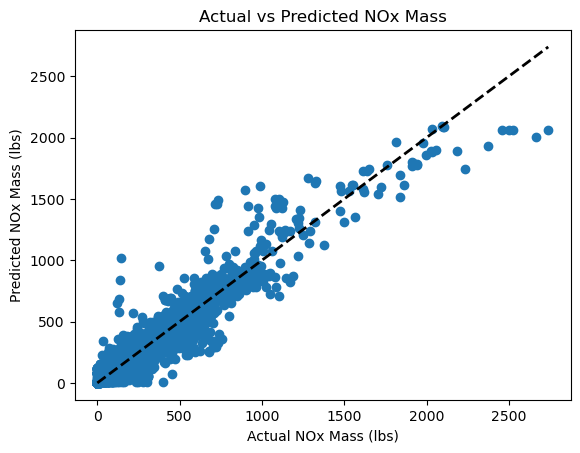

In [21]:
# model with best hpo parameters (no lags, no unmeasured data)

xgb_hpo_model = xgb.train(params=hpo_params, dtrain=dtrain, num_boost_round=235)

# dump model
xgb_hpo_model.save_model("NY/Hourly/Concatted File/Modeling/XGB/NOx/Trained Models/xgb_hpo_model_ny_no_lags_no_unmeasured.json")

y_pred = xgb_hpo_model.predict(dtest)

# set all predictions below 0 to 0
y_pred[y_pred < 0] = 0

y_test = dtest.get_label() # get y_test from dmatrix

print(f"R^2 Score: {r2_score(y_test, y_pred):.4f}")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test, y_pred):.4f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")

plt.scatter(y_test, y_pred)
plt.xlabel("Actual NOx Mass (lbs)")
plt.ylabel("Predicted NOx Mass (lbs)")
plt.title("Actual vs Predicted NOx Mass")
plt.plot([min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], 'k--', lw=2)
plt.show()

In [23]:
print(f"Normalized RMSE (by std): {np.sqrt(mean_squared_error(y_test, y_pred)) / np.std(y_test):.4f}")

Normalized RMSE (by std): 0.1700


In [36]:
# Year by Year (hpo model)

year_tuples = [(2019, 2020), (2020, 2021), (2021, 2022), (2022, 2023), (2023, 2024)] 

for years in year_tuples:

    X_train = campd_df[(campd_df["Year"] == years[0]) & (campd_df["NOx Mass (lbs)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
    y_train = campd_df[(campd_df["Year"] == years[0]) & (campd_df["NOx Mass (lbs)"].notna())][target_variable]  
    X_test = campd_df[(campd_df["Year"] == years[1]) & (campd_df["NOx Mass (lbs)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
    y_test = campd_df[(campd_df["Year"] ==  years[1]) & (campd_df["NOx Mass (lbs)"].notna())][target_variable]

    X_train = preprocessor.fit_transform(X_train)
    X_test = preprocessor.transform(X_test)

    dtrain = xgb.DMatrix(X_train, label=y_train)
    dtest = xgb.DMatrix(X_test, label=y_test)

    current_xgb_hpo_model = xgb.train(params=hpo_params, dtrain=dtrain, num_boost_round=235)

    y_pred = current_xgb_hpo_model.predict(dtest)

    y_pred[y_pred < 0] = 0

    print(f"Train: {years[0]}, Test: {years[1]} | R^2: {r2_score(y_test, y_pred):.4f}, MSE: {mean_squared_error(y_test, y_pred):.4f}, RMSE: {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}, nRMSE: {np.sqrt(mean_squared_error(y_test, y_pred)) / np.std(y_test):.4f}")


Train: 2019, Test: 2020 | R^2: 0.9587, MSE: 148.6200, RMSE: 12.1910, nRMSE: 0.2037
Train: 2020, Test: 2021 | R^2: 0.9385, MSE: 212.8453, RMSE: 14.5892, nRMSE: 0.2477
Train: 2021, Test: 2022 | R^2: 0.9372, MSE: 331.0059, RMSE: 18.1936, nRMSE: 0.2507
Train: 2022, Test: 2023 | R^2: 0.9610, MSE: 125.6723, RMSE: 11.2104, nRMSE: 0.1974
Train: 2023, Test: 2024 | R^2: 0.9687, MSE: 115.3654, RMSE: 10.7408, nRMSE: 0.1768


In [34]:
# Rolling Window (hpo model)

years = [2019, 2020, 2021, 2022, 2023, 2024]

for i in range(1, len(years)):
    train_years = years[:i]      # all years before the test year
    test_year = years[i]         # current year for testing

    X_train = campd_df[(campd_df["Year"].isin(train_years)) & (campd_df["NOx Mass (lbs)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
    y_train = campd_df[(campd_df["Year"].isin(train_years)) & (campd_df["NOx Mass (lbs)"].notna())][target_variable]

    X_test = campd_df[(campd_df["Year"] == test_year) & (campd_df["NOx Mass (lbs)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
    y_test = campd_df[(campd_df["Year"] == test_year) & (campd_df["NOx Mass (lbs)"].notna())][target_variable]

    X_train = preprocessor.fit_transform(X_train)
    X_test = preprocessor.transform(X_test)

    dtrain = xgb.DMatrix(X_train, label=y_train)
    dtest = xgb.DMatrix(X_test, label=y_test)

    current_xgb_hpo_model = xgb.train(params=hpo_params, dtrain=dtrain, num_boost_round=235)

    y_pred = current_xgb_hpo_model.predict(dtest)
    y_pred[y_pred < 0] = 0

    print(f"Train: {train_years}, Test: {test_year} | R^2: {r2_score(y_test, y_pred):.4f}, "
          f"MSE: {mean_squared_error(y_test, y_pred):.4f}, "
          f"RMSE: {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}, "
          f"nRMSE: {np.sqrt(mean_squared_error(y_test, y_pred)) / np.std(y_test):.4f}")



Train: [2019], Test: 2020 | R^2: 0.9587, MSE: 148.6200, RMSE: 12.1910, nRMSE: 0.2037
Train: [2019, 2020], Test: 2021 | R^2: 0.9404, MSE: 206.4370, RMSE: 14.3679, nRMSE: 0.2439
Train: [2019, 2020, 2021], Test: 2022 | R^2: 0.9437, MSE: 296.7022, RMSE: 17.2250, nRMSE: 0.2374
Train: [2019, 2020, 2021, 2022], Test: 2023 | R^2: 0.9646, MSE: 113.9171, RMSE: 10.6732, nRMSE: 0.1880
Train: [2019, 2020, 2021, 2022, 2023], Test: 2024 | R^2: 0.9709, MSE: 107.2864, RMSE: 10.3579, nRMSE: 0.1705


In [37]:
# Static Prediction Horizon (2024) (hpo model)

years = [2019, 2020, 2021, 2022, 2023]
test_year = 2024

for i in range(1, len(years) + 1):
    train_years = years[:i]  # Use first i years as training set
    
    X_train = campd_df[(campd_df["Year"].isin(train_years)) & (campd_df["NOx Mass (lbs)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
    y_train = campd_df[(campd_df["Year"].isin(train_years)) & (campd_df["NOx Mass (lbs)"].notna())][target_variable]

    X_test = campd_df[(campd_df["Year"] == test_year) & (campd_df["NOx Mass (lbs)"].notna())][num_features + unencoded_cat_features + encoded_cat_features]
    y_test = campd_df[(campd_df["Year"] == test_year) & (campd_df["NOx Mass (lbs)"].notna())][target_variable]

    X_train = preprocessor.fit_transform(X_train)
    X_test = preprocessor.transform(X_test)

    dtrain = xgb.DMatrix(X_train, label=y_train)
    dtest = xgb.DMatrix(X_test, label=y_test)

    current_xgb_hpo_model = xgb.train(params=hpo_params, dtrain=dtrain, num_boost_round=235)

    y_pred = current_xgb_hpo_model.predict(dtest)
    y_pred[y_pred < 0] = 0

    print(f"Train: {train_years}, Test: {test_year} | "
          f"R^2: {r2_score(y_test, y_pred):.4f}, "
          f"MSE: {mean_squared_error(y_test, y_pred):.4f}, "
          f"RMSE: {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}, "
          f"nRMSE: {np.sqrt(mean_squared_error(y_test, y_pred)) / np.std(y_test):.4f}")


Train: [2019], Test: 2024 | R^2: 0.9603, MSE: 146.1917, RMSE: 12.0910, nRMSE: 0.1991
Train: [2019, 2020], Test: 2024 | R^2: 0.9674, MSE: 119.9954, RMSE: 10.9542, nRMSE: 0.1804
Train: [2019, 2020, 2021], Test: 2024 | R^2: 0.9632, MSE: 135.4907, RMSE: 11.6400, nRMSE: 0.1917
Train: [2019, 2020, 2021, 2022], Test: 2024 | R^2: 0.9641, MSE: 132.1010, RMSE: 11.4935, nRMSE: 0.1892
Train: [2019, 2020, 2021, 2022, 2023], Test: 2024 | R^2: 0.9709, MSE: 107.2864, RMSE: 10.3579, nRMSE: 0.1705


In [41]:
r2_scores = [0.9587, 0.9385, 0.9372, 0.9610, 0.9687]
mse_values = [148.6200, 212.8453, 331.0059, 125.6723, 115.3654]
rmse_values = [12.1910, 14.5892, 18.1936, 11.2104, 10.7408]
nrmse_values = [0.2037, 0.2477, 0.2507, 0.1974, 0.1768]

avg_r2 = sum(r2_scores) / len(r2_scores)
avg_mse = sum(mse_values) / len(mse_values)
avg_rmse = sum(rmse_values) / len(rmse_values)
avg_nrmse = sum(nrmse_values) / len(nrmse_values)

print("\nYear by Year")
print(f"Average R2: {avg_r2:.4f}")
print(f"Average MSE: {avg_mse:.4f}")
print(f"Average RMSE: {avg_rmse:.4f}")
print(f"Average nRMSE: {avg_nrmse:.4f}")

r2_scores = [0.9587, 0.9404, 0.9437, 0.9646, 0.9709]
mse_values = [148.6200, 206.4370, 296.7022, 113.9171, 107.2864]
rmse_values = [12.1910, 14.3679, 17.2250, 10.6732, 10.3579]
nrmse_values = [0.2037, 0.2439, 0.2374, 0.1880, 0.1705]

avg_r2 = sum(r2_scores) / len(r2_scores)
avg_mse = sum(mse_values) / len(mse_values)
avg_rmse = sum(rmse_values) / len(rmse_values)
avg_nrmse = sum(nrmse_values) / len(nrmse_values)

print("\nRolling Window")
print(f"Average R2: {avg_r2:.4f}")
print(f"Average MSE: {avg_mse:.4f}")
print(f"Average RMSE: {avg_rmse:.4f}")
print(f"Average nRMSE: {avg_nrmse:.4f}")

r2_scores = [0.9603, 0.9674, 0.9632, 0.9641, 0.9709]
mse_values = [146.1917, 119.9954, 135.4907, 132.1010, 107.2864]
rmse_values = [12.0910, 10.9542, 11.6400, 11.4935, 10.3579]
nrmse_values = [0.1991, 0.1804, 0.1917, 0.1892, 0.1705]

avg_r2 = sum(r2_scores) / len(r2_scores)
avg_mse = sum(mse_values) / len(mse_values)
avg_rmse = sum(rmse_values) / len(rmse_values)
avg_nrmse = sum(nrmse_values) / len(nrmse_values)

print("\nStatic Prediction Horizon (2024)")
print(f"Average R2: {avg_r2:.4f}")
print(f"Average MSE: {avg_mse:.4f}")
print(f"Average RMSE: {avg_rmse:.4f}")
print(f"Average nRMSE: {avg_nrmse:.4f}")


Year by Year
Average R2: 0.9528
Average MSE: 186.7018
Average RMSE: 13.3850
Average nRMSE: 0.2153

Rolling Window
Average R2: 0.9557
Average MSE: 174.5925
Average RMSE: 12.9630
Average nRMSE: 0.2087

Static Prediction Horizon (2024)
Average R2: 0.9652
Average MSE: 128.2130
Average RMSE: 11.3073
Average nRMSE: 0.1862


<h2>Interpretability</h2>

<h5>Read-in Models</h5>

In [ ]:
# load saved models

mlp_default_model_no_lags = joblib.load("NY/Hourly/Concatted File/Modeling/MLP/NOx/Trained Models/mlp_default_model_ny_no_lags_no_unmeasured_with_temps_NO_MEDIAN.json")

rf_default_model_no_lags = joblib.load("NY/Hourly/Concatted File/Modeling/RF/NOx/Trained Models/rf_default_model_ny_no_lags_with_unmeasured_with_temps.json")

rf_default_model_with_lags = joblib.load("NY/Hourly/Concatted File/Modeling/RF/NOx/Trained Models/rf_default_model_ny_with_lags_with_unmeasured_with_temps.json")

xgb_default_model_with_lags = xgb.Booster()
xgb_default_model_with_lags.load_model("NY/Hourly/Concatted File/Modeling/XGB/NOx/Trained Models/xgb_default_model_ny_with_lags_no_unmeasured_with_temps.json")

xgb_default_model_no_lags = xgb.Booster()
xgb_default_model_no_lags.load_model("NY/Hourly/Concatted File/Modeling/XGB/NOx/Trained Models/xgb_default_model_ny_no_lags_no_unmeasured_with_temps.json")

In [ ]:
xgb_hpo_model = xgb.Booster()
xgb_hpo_model.load_model("NY/Hourly/Concatted File/Modeling/XGB/NOx/Trained Models/xgb_hpo_model_ny_with_lags_no_unmeasured.json")

<h3>RF (model-specific)</h3>

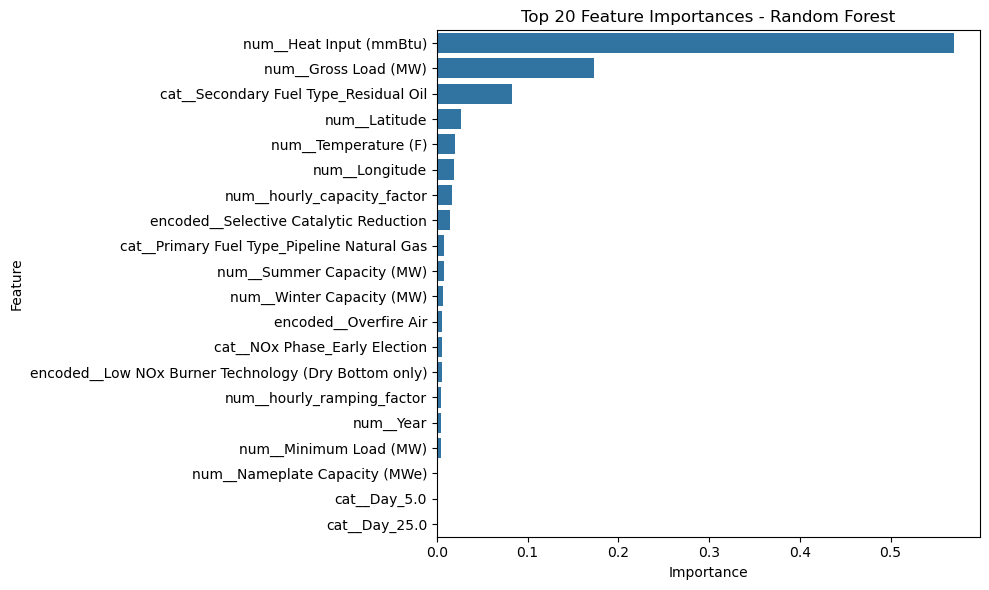

In [ ]:
# for default rf model no lags, no unmeasured data, with temps

importances = rf_default_model_no_lags.feature_importances_

feat_imp_df = pd.DataFrame({
    'Feature': X_sampled.columns,
    'Importance': importances
})

feat_imp_df = feat_imp_df.sort_values(by='Importance', ascending=False)

# uses MDI (Mean Decrease in Impurity)
plt.figure(figsize=(10, 6))
sns.barplot(data=feat_imp_df.head(20), x='Importance', y='Feature')
plt.title('Top 20 Feature Importances - Random Forest')
plt.tight_layout()
plt.show()


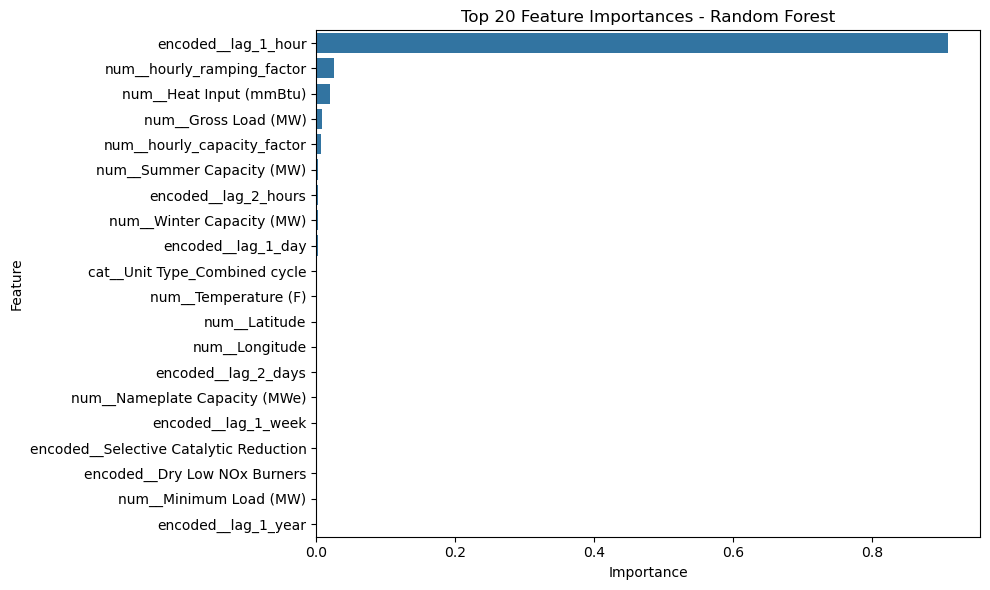

In [ ]:
# for default rf model with lags, no unmeasured data, with temps

importances = rf_default_model_with_lags.feature_importances_

feat_imp_df = pd.DataFrame({
    'Feature': X_sampled.columns,
    'Importance': importances
})

feat_imp_df = feat_imp_df.sort_values(by='Importance', ascending=False)

# uses MDI (Mean Decrease in Impurity)
plt.figure(figsize=(10, 6))
sns.barplot(data=feat_imp_df.head(20), x='Importance', y='Feature')
plt.title('Top 20 Feature Importances - Random Forest')
plt.tight_layout()
plt.show()


<h3>XGB (model-specific)</h3>

<h5>Default Params</h5>

<Axes: title={'center': 'Feature importance'}, xlabel='F score', ylabel='Features'>

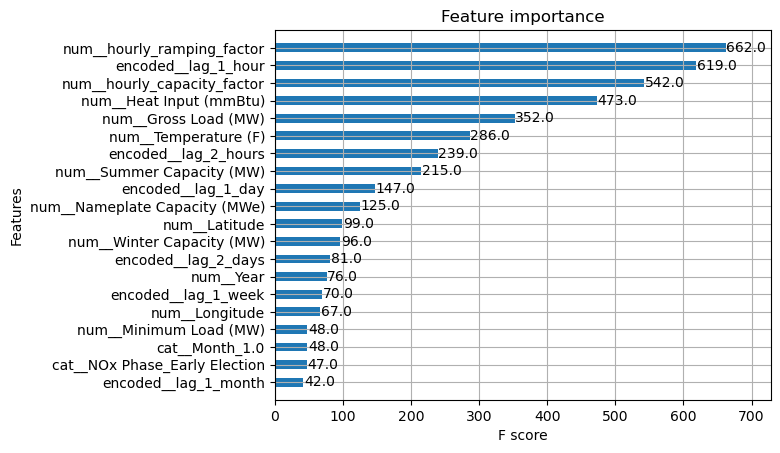

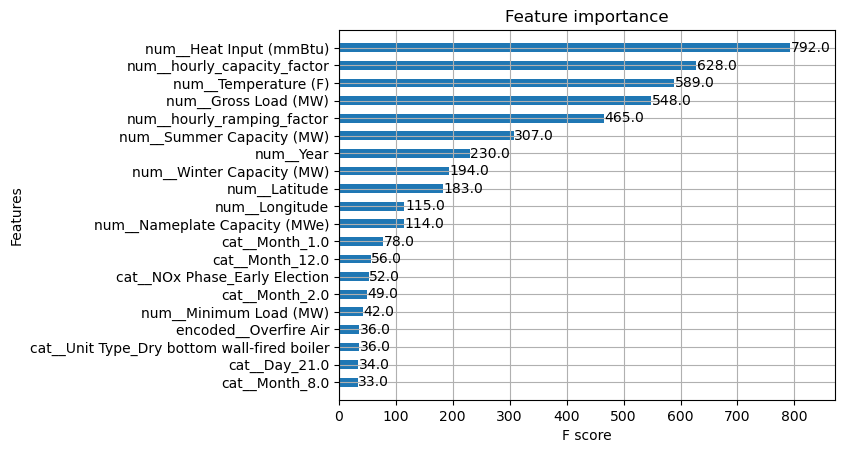

In [70]:
# use weight for feature importance (how often the feature is used in splits)
plot_importance(
    xgb_default_model_with_lags, 
    importance_type='weight',
    max_num_features=20,       
    height=0.5,
    show_values=True,
    grid=True
)

plot_importance(
    xgb_default_model_no_lags, 
    importance_type='weight',
    max_num_features=20,       
    height=0.5,
    show_values=True,
    grid=True
)

<Axes: title={'center': 'Feature importance'}, xlabel='F score', ylabel='Features'>

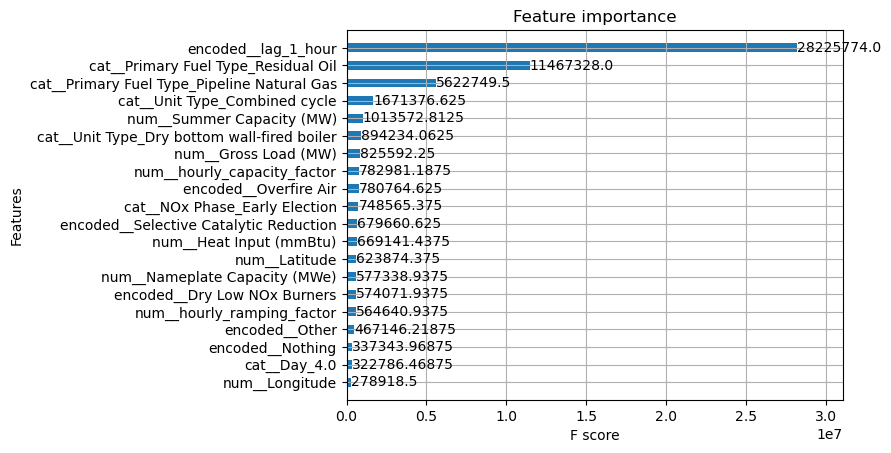

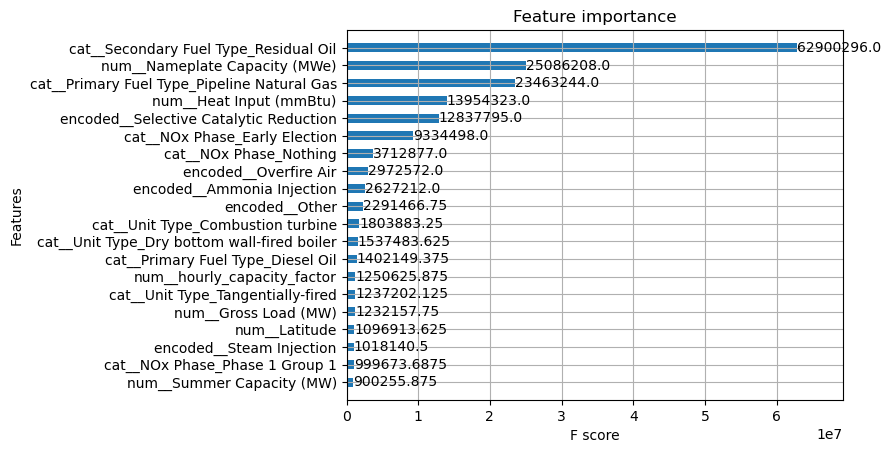

In [71]:
# use gain for feature importance (Average improvement in loss from splits involving that feature)
plot_importance(
    xgb_default_model_with_lags, 
    importance_type='gain',
    max_num_features=20,       
    height=0.5,
    show_values=True,
    grid=True
)

plot_importance(
    xgb_default_model_no_lags, 
    importance_type='gain',
    max_num_features=20,       
    height=0.5,
    show_values=True,
    grid=True
)

<Axes: title={'center': 'Feature importance'}, xlabel='F score', ylabel='Features'>

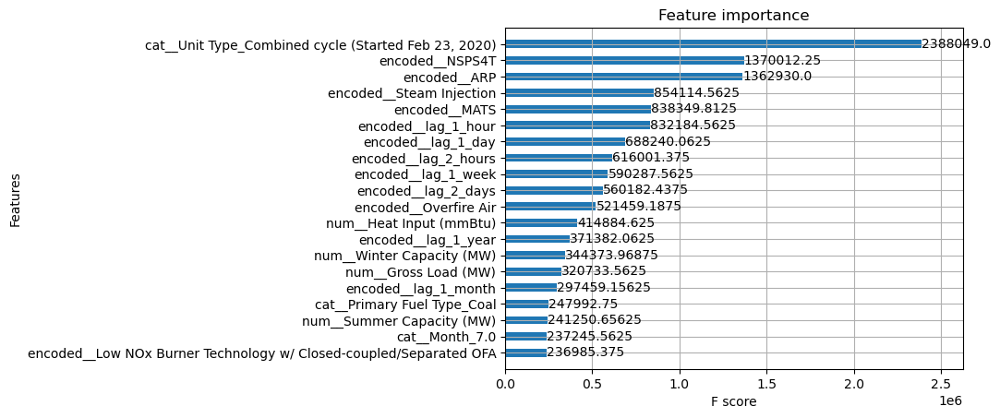

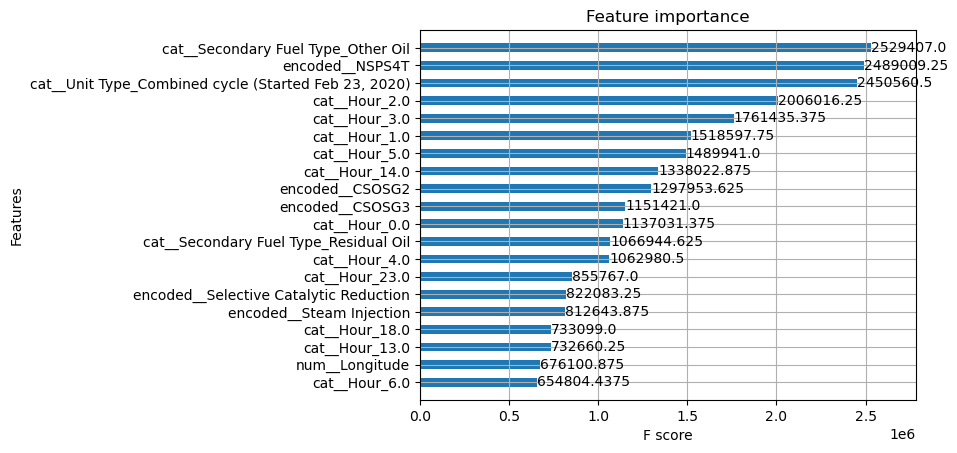

In [72]:
# use cover for feature importance (how many observations are affected by the feature)
plot_importance(
    xgb_default_model_with_lags, 
    importance_type='cover',
    max_num_features=20,       
    height=0.5,
    show_values=True,
    grid=True
)

plot_importance(
    xgb_default_model_no_lags, 
    importance_type='cover',
    max_num_features=20,       
    height=0.5,
    show_values=True,
    grid=True
)

<h3>Partial Dependence Plots</h3>

In [8]:
xgb_default_model_no_lags_regressor = XGBRegressor()
xgb_default_model_no_lags_regressor._Booster = xgb_default_model_no_lags

c:\Users\marce\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


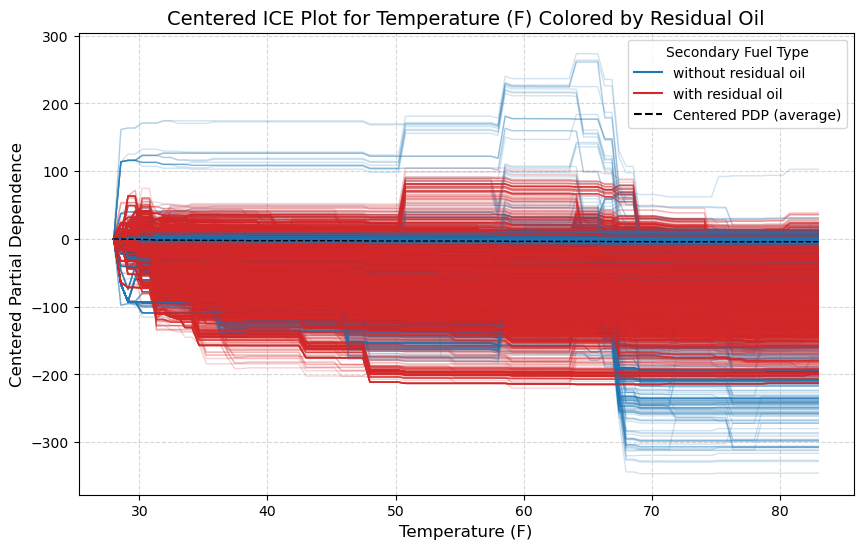

In [ ]:
from sklearn.inspection import partial_dependence

X_sampled = X_test #.sample(100000, random_state=42)

# Compute partial dependence with both ICE and PDP
pdp_lines = partial_dependence(
    xgb_default_model_no_lags_regressor,
    X_sampled,
    ["num__Temperature (F)"],
    kind="both"
)

# Define the color feature and colors for ICE curves
color_feature = "cat__Secondary Fuel Type_Residual Oil"
colors = ["tab:blue", "tab:red"]

plt.figure(figsize=(10, 6))

# Plot centered ICE curves for each instance
for i in range(0, X_sampled.shape[0]):
    # Ensure binary values for the color feature
    color = colors[int(round(X_sampled[color_feature].values[i]))]
    
    # Center the ICE curve by subtracting the first prediction value (or use another reference point)
    centered_curve = pdp_lines["individual"][0][i] - pdp_lines["individual"][0][i][0]
    
    plt.plot(
        pdp_lines["grid_values"][0],  # x-axis: temperature grid
        centered_curve,  # y-axis: centered prediction curve
        linewidth=1,
        color=color,
        alpha=0.2  # Add transparency for overlapping curves
    )

# Overlay the PDP (average of ICE curves), also centered
pdp = pdp_lines["average"][0]
centered_pdp = pdp - pdp[0]  # Center the PDP by subtracting the first value
plt.plot(
    pdp_lines["grid_values"][0],
    centered_pdp,
    linewidth=1,
    color="black",
    linestyle="--",
    label="Centered PDP (average)"
)

plt.ylabel("Centered Partial Dependence", size=12)
plt.xlabel("Temperature (F)", size=12)
plt.title("Centered ICE Plot for Temperature (F) Colored by Residual Oil", size=14)
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend(
    handles=[
        plt.Line2D([0], [0], color=colors[0], label="without residual oil"),
        plt.Line2D([0], [0], color=colors[1], label="with residual oil"),
        plt.Line2D([0], [0], color="black", linestyle="--", label="Centered PDP (average)")
    ],
    title="Secondary Fuel Type"
)
plt.show()

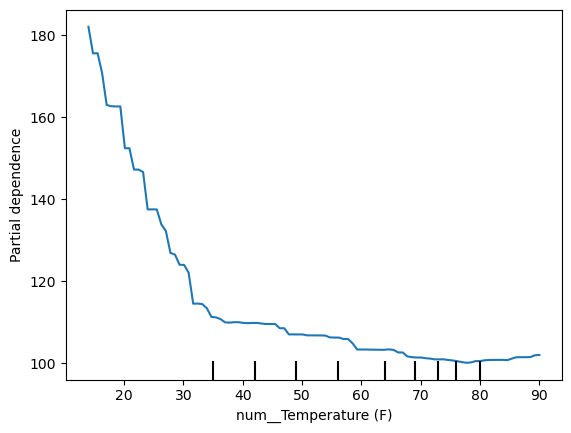

In [ ]:
PartialDependenceDisplay.from_estimator(xgb_default_model_no_lags_regressor, X_test[X_test["cat__Secondary Fuel Type_Residual Oil"] == 1], ["num__Temperature (F)"], percentiles=(0.001,0.99), kind="average", n_jobs=-1)

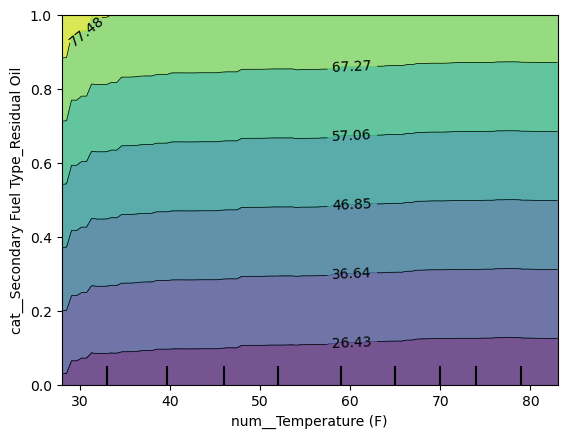

In [ ]:
PartialDependenceDisplay.from_estimator(xgb_default_model_no_lags_regressor, X_test, [("num__Temperature (F)", "cat__Secondary Fuel Type_Residual Oil")])

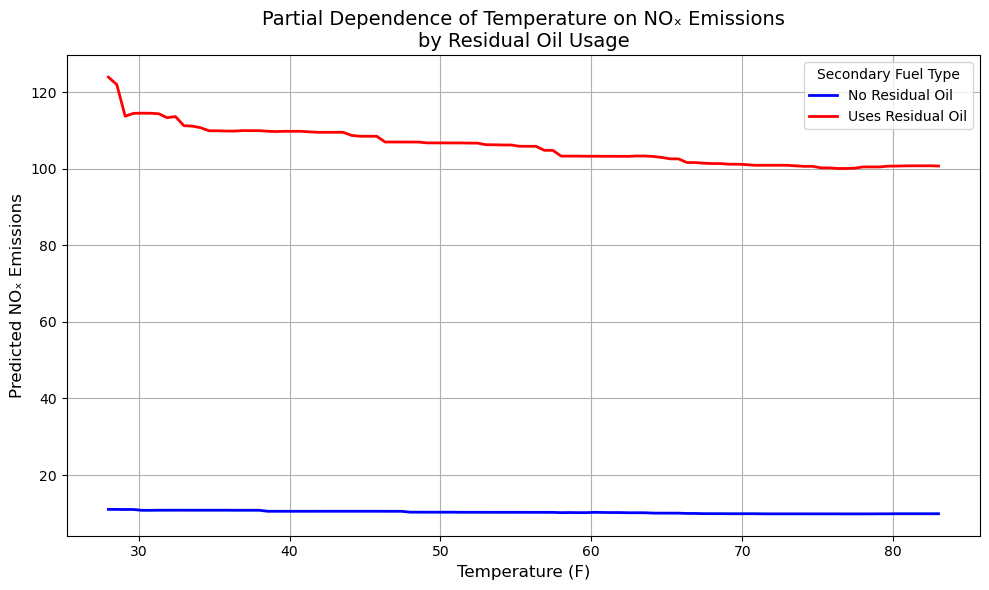

In [ ]:
feature = "num__Temperature (F)"
group_feature = "cat__Secondary Fuel Type_Residual Oil"

X_no_residual = X_test[X_test[group_feature] == 0]
X_with_residual = X_test[X_test[group_feature] == 1]

pdp_no_residual = partial_dependence(
    xgb_default_model_no_lags_regressor,
    X_no_residual,
    features=[feature],
    kind="average"
)

pdp_with_residual = partial_dependence(
    xgb_default_model_no_lags_regressor,
    X_with_residual,
    features=[feature],
    kind="average"
)

grid = pdp_no_residual["grid_values"][0]
avg_no_residual = pdp_no_residual["average"][0]
avg_with_residual = pdp_with_residual["average"][0]

plt.figure(figsize=(10, 6))
plt.plot(grid, avg_no_residual, label="No Residual Oil", color="blue", linewidth=2)
plt.plot(grid, avg_with_residual, label="Uses Residual Oil", color="red", linewidth=2)

plt.xlabel("Temperature (F)", fontsize=12)
plt.ylabel("Predicted NOₓ Emissions", fontsize=12)
plt.title("Partial Dependence of Temperature on NOₓ Emissions\nby Residual Oil Usage", fontsize=14)
plt.legend(title="Secondary Fuel Type")
plt.grid(True)
plt.tight_layout()
plt.show()

# the relationship is similar, but scaling is different (units with Residual Oil as Secondary Fuel emit more on average)

<h3>Permutation Importance</h3>

<h4>Default Params</h4>

In [5]:
regressor = XGBRegressor()
regressor._Booster = xgb_default_model_no_lags

In [17]:
result = permutation_importance(regressor, X_test, y_test, n_repeats=3, random_state=42, scoring='neg_mean_squared_error', n_jobs=-1)

importance_df = pd.DataFrame({
    'feature': X_test.columns,
    'importance_mean': result.importances_mean,
    'importance_std': result.importances_std
}).sort_values(by='importance_mean', ascending=False)

display(importance_df)


,feature,importance_mean,importance_std
97,num__Heat Input (mmBtu),11724.908880,23.573007
96,num__Gross Load (MW),2396.952011,1.034504
101,num__hourly_capacity_factor,1829.990463,3.513026
100,num__Nameplate Capacity (MWe),1432.571070,11.385595
94,cat__Secondary Fuel Type_Residual Oil,965.793727,3.417246
...,...,...,...
7,cat__Month_8.0,-0.471741,0.082753
112,encoded__Low NOx Burner Technology w/ Closed-c...,-0.514760,0.033586
62,cat__Day_27.0,-1.122091,0.063228
57,cat__Day_22.0,-1.159053,0.085806


<h4>Ungrouped</h4>

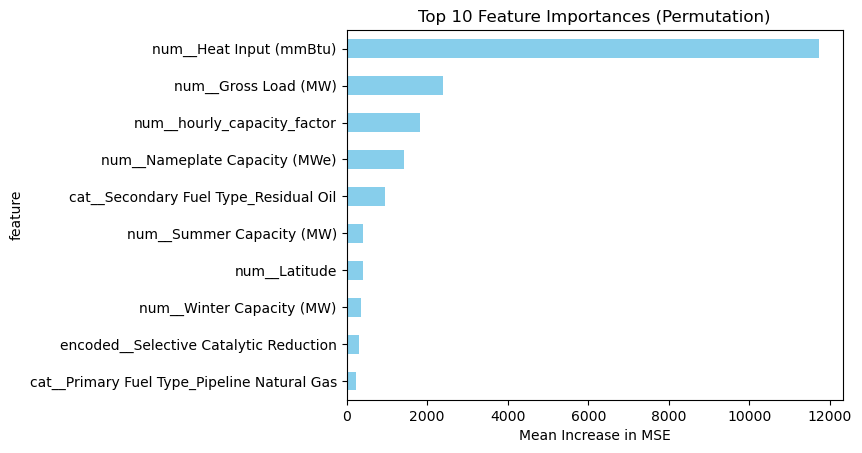

In [18]:
importance_df.head(10).plot.barh(
    x='feature', 
    y='importance_mean', 
    legend=False,
    color='skyblue'
)

plt.xlabel('Mean Increase in MSE')
plt.title('Top 10 Feature Importances (Permutation)')
plt.gca().invert_yaxis()  # get the most important on top
plt.show()


In [ ]:
campd_df[(campd_df["Year"] == 2024)]["Secondary Fuel Type"].value_counts()

Secondary Fuel Type
Diesel Oil                                             238205
Nothing                                                175731
Residual Oil                                            59658
Pipeline Natural Gas                                    26007
Wood                                                     8559
Other Oil                                                2092
Other Solid Fuel, Petroleum Coke, Tire Derived Fuel      1293
Natural Gas, Wood                                          51
Name: count, dtype: Int64

In [27]:
campd_df[(campd_df["Year"] == 2024)].groupby(by="Secondary Fuel Type")["NOx Mass (lbs)"].median()

Secondary Fuel Type
Diesel Oil                                              9.300000
Natural Gas, Wood                                       0.000000
Nothing                                                 3.200000
Other Oil                                               2.400000
Other Solid Fuel, Petroleum Coke, Tire Derived Fuel     0.000000
Pipeline Natural Gas                                    0.000000
Residual Oil                                           74.699997
Wood                                                   16.400000
Name: NOx Mass (lbs), dtype: float32

In [19]:
# num features
num_features = ['num__Gross Load (MW)',
                 'num__Heat Input (mmBtu)', 
                 'num__Latitude', 
                 'num__Longitude', 
                 'num__Nameplate Capacity (MWe)',
                   'num__hourly_capacity_factor', 
                   'num__hourly_ramping_factor', 
                   'num__Summer Capacity (MW)', 
                   'num__Winter Capacity (MW)', 
                   'num__Minimum Load (MW)'] # we ignore day, hour, month, year

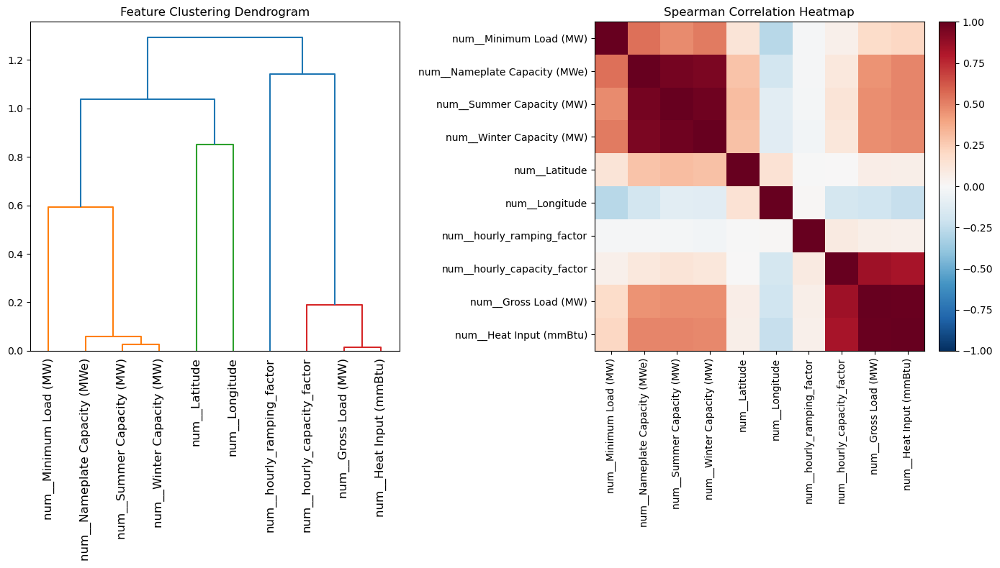

In [20]:
# group features systematically (cluster on correlation)

X_subset = X_test[num_features]
X_subset = X_subset.dropna()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 8))

# Compute Spearman correlation matrix on selected features
corr = spearmanr(X_subset).correlation

# Make symmetric and fill diagonal with 1s
corr = (corr + corr.T) / 2
np.fill_diagonal(corr, 1)

# Convert correlation to distance matrix for clustering
distance_matrix = 1 - np.abs(corr)
dist_linkage = hierarchy.ward(squareform(distance_matrix))

# Plot dendrogram
dendro = hierarchy.dendrogram(
    dist_linkage, labels=X_subset.columns.to_list(), ax=ax1, leaf_rotation=90
)
dendro_idx = np.arange(len(dendro["ivl"]))

# Plot reordered heatmap of correlations
im = ax2.imshow(corr[dendro["leaves"], :][:, dendro["leaves"]],
                cmap='RdBu_r', vmin=-1, vmax=1)
ax2.set_xticks(dendro_idx)
ax2.set_yticks(dendro_idx)
ax2.set_xticklabels(dendro["ivl"], rotation=90)
ax2.set_yticklabels(dendro["ivl"])

# Add colorbar
fig.colorbar(im, ax=ax2, fraction=0.046, pad=0.04)

ax1.set_title("Feature Clustering Dendrogram")
ax2.set_title("Spearman Correlation Heatmap")

plt.tight_layout()
plt.show()

# distance here is calculated as 1 - Spearman correlation coefficient


In [ ]:
# select only one feature per group of features with distance <0.2 -> Heat Input, Nameplate Capacity (MWe)

In [29]:
X_train = pd.read_csv("NY/Hourly/Concatted File/Modeling/XGB/X_train_processed", dtype=campd_type_dict)
X_test = pd.read_csv("NY/Hourly/Concatted File/Modeling/XGB/X_test_processed", dtype=campd_type_dict)
y_train = pd.read_csv("NY/Hourly/Concatted File/Modeling/XGB/y_train")
y_test = pd.read_csv("NY/Hourly/Concatted File/Modeling/XGB/y_test")

In [21]:
# group features below threshold of 0.2 (over 80% correlation) and retrain

X_train = X_train.drop(columns=["num__hourly_capacity_factor", "num__Gross Load (MW)", "num__Summer Capacity (MW)",
                "num__Winter Capacity (MW)"])
X_test = X_test.drop(columns=["num__hourly_capacity_factor", "num__Gross Load (MW)", "num__Summer Capacity (MW)",
                "num__Winter Capacity (MW)"])

# Convert to DMatrix for XGBoost
dtrain = xgb.DMatrix(X_train, label=y_train) 
dtest = xgb.DMatrix(X_test, label=y_test)

R^2 Score: 0.9605
Mean Squared Error (MSE): 145.2922
Root Mean Squared Error (RMSE): 12.0537


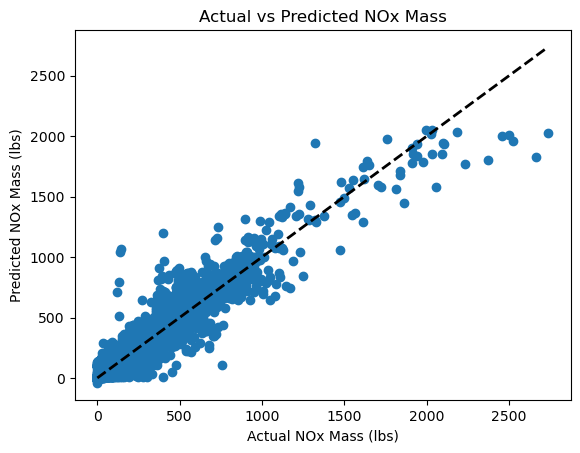

In [ ]:
xgb_default_model_no_corr = xgb.train(params=default_params, dtrain=dtrain, num_boost_round=100)

y_pred = xgb_default_model_no_corr.predict(dtest)
y_test = dtest.get_label()
print(f"R^2 Score: {r2_score(y_test, y_pred):.4f}")
print(f"Mean Squared Error (MSE): {mean_squared_error(y_test, y_pred):.4f}")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")

plt.scatter(y_test, y_pred)
plt.xlabel("Actual NOx Mass (lbs)")
plt.ylabel("Predicted NOx Mass (lbs)")
plt.title("Actual vs Predicted NOx Mass")
plt.plot([min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())], 'k--', lw=2)
plt.show()

In [25]:
regressor = XGBRegressor()
regressor._Booster = xgb_default_model_no_corr

In [26]:
result = permutation_importance(regressor, X_test, y_test, n_repeats=3, random_state=42, scoring='neg_mean_squared_error')

In [27]:
importance_df = pd.DataFrame({
    'feature': X_test.columns,
    'importance_mean': result.importances_mean,
    'importance_std': result.importances_std
}).sort_values(by='importance_mean', ascending=False)

print(importance_df)


                                               feature  importance_mean  \
96                             num__Heat Input (mmBtu)     10104.394613   
99                       num__Nameplate Capacity (MWe)      1933.974365   
94               cat__Secondary Fuel Type_Residual Oil      1267.873454   
101                             num__Minimum Load (MW)       502.353231   
115             encoded__Selective Catalytic Reduction       373.037577   
..                                                 ...              ...   
50                                       cat__Day_15.0        -0.500361   
108  encoded__Low NOx Burner Technology w/ Closed-c...        -0.581757   
57                                       cat__Day_22.0        -0.656265   
5                                       cat__Month_6.0        -0.741221   
11                                     cat__Month_12.0        -3.522715   

     importance_std  
96        86.214419  
99        10.873814  
94         4.096822  
101        

<h4>Grouped</h4>

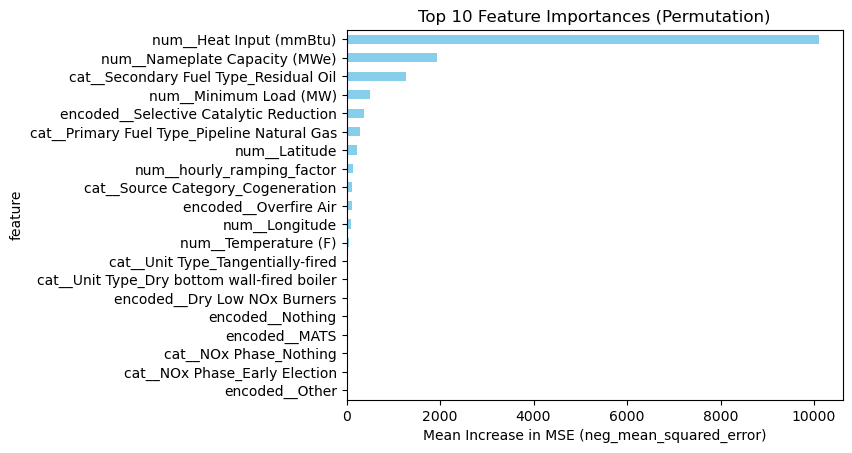

In [28]:
importance_df.head(20).plot.barh(
    x='feature', 
    y='importance_mean', 
    legend=False,
    color='skyblue'
)

plt.xlabel('Mean Increase in MSE (neg_mean_squared_error)')
plt.title('Top 10 Feature Importances (Permutation)')
plt.gca().invert_yaxis()  # get the most important on top
plt.show()


<h3>SHAP</h3>

<h4>LR</h4>

In [ ]:
# interventional algorithm stays "true to the model" -> shows how the model actually uses features without respect for correlation
# correlation_dependent stays "true to the data" -> distributes attributions between correlated features
# https://shap.readthedocs.io/en/latest/generated/shap.LinearExplainer.html

In [ ]:
# lr model with ridge regularization 
explainer = shap.LinearExplainer(lr_model, shap.sample(X_train, random_state=42))
shap_values = explainer(X_test)

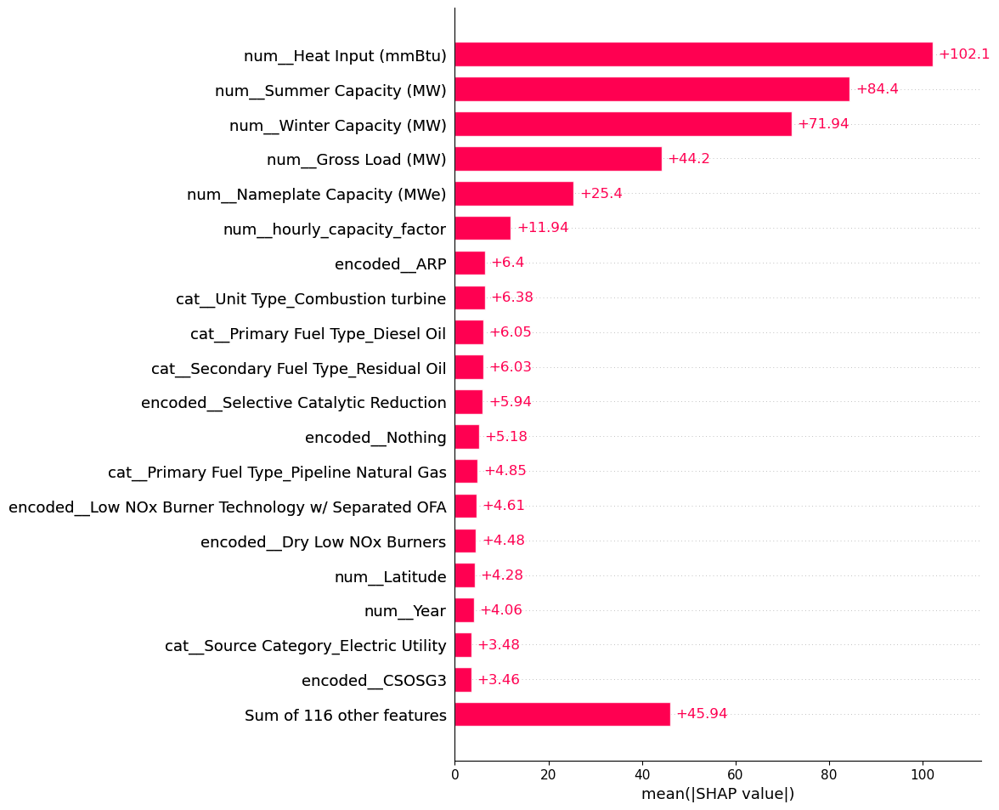

In [165]:
shap.plots.bar(shap_values, max_display=20)

In [ ]:
# normal LR without ridge regression
explainer = shap.LinearExplainer(lr_model, shap.sample(X_train, random_state=42), feature_perturbation="correlation_dependent")

In [ ]:
shap_values = explainer(X_test)

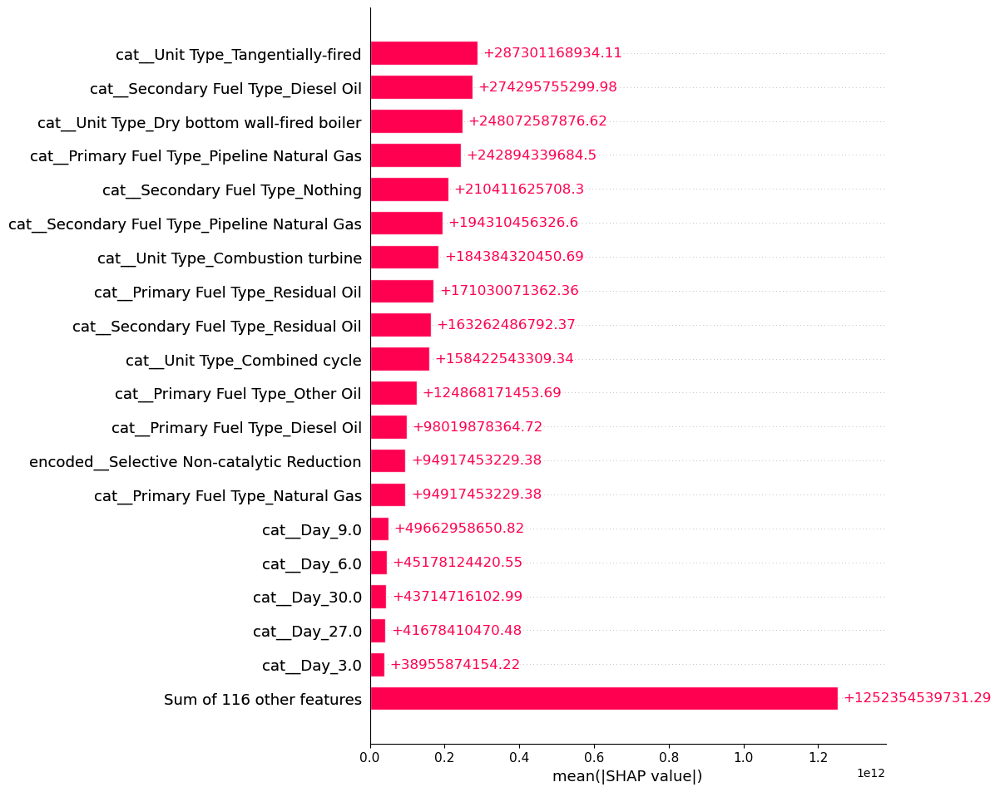

In [ ]:
shap.plots.bar(shap_values, max_display=20)

# coefficients are extremely large and nonsensical

<h4>MLP</h4>

In [ ]:
# we cannot use deepexplainer since it is only compatible with tensorflow and keras (we are using sklearn)

# this would take extremely long
# explainer = shap.KernelExplainer(mlp_default_model_no_lags.predict, shap.sample(X_train, random_state=42))

# we use the permutation algorithm which is similar to kernelshap, uses permutation for approximation
explainer = shap.Explainer(mlp_default_model_no_lags.predict, shap.sample(X_train, random_state=42), algorithm="permutation")
shap_values = explainer(X_test.sample(20000, random_state=42))

# this still took 15mins


PermutationExplainer explainer: 20001it [13:21, 24.63it/s]                           


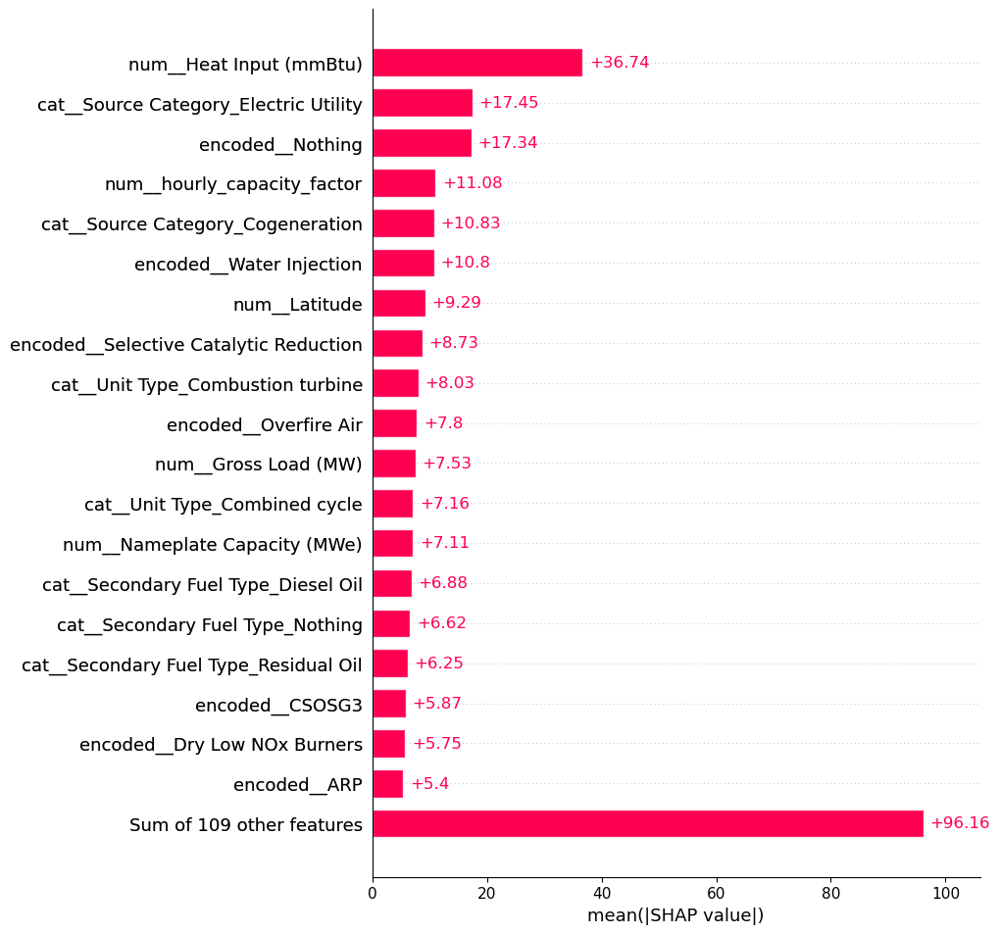

In [124]:
shap.plots.bar(shap_values, max_display=20)

<h4>RF</h4>

In [6]:
explainer = shap.TreeExplainer(rf_default_model_no_lags)

In [ ]:
# takes over 15 mins without approximation
shap_values = explainer(X_test, approximate=True)

In [8]:
joblib.dump(shap_values, "NY/Hourly/Concatted File/Modeling/RF/NOx/Trained Models/shap_values_rf_default_model_ny_no_lags_no_unmeasured_with_temps.pkl")

['NY/Hourly/Concatted File/Modeling/RF/NOx/Trained Models/shap_values_rf_default_model_ny_no_lags_no_unmeasured_with_temps.pkl']

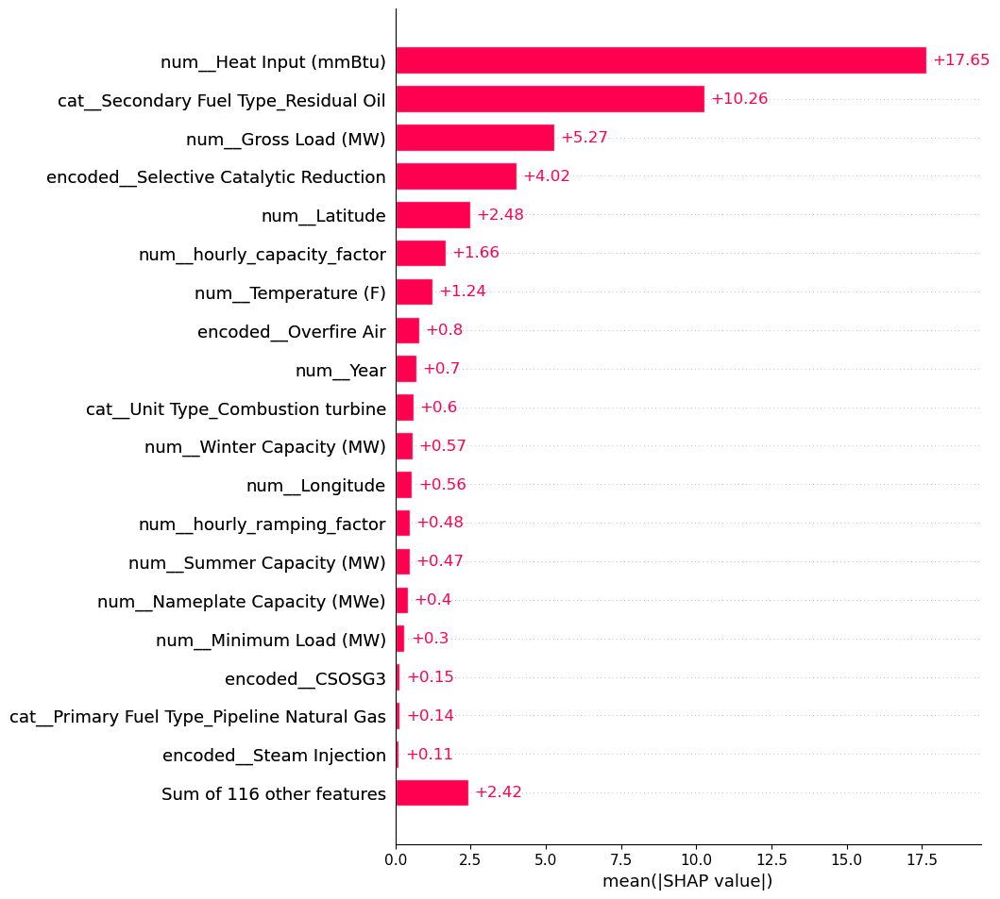

In [9]:
shap.plots.bar(shap_values, max_display=20)

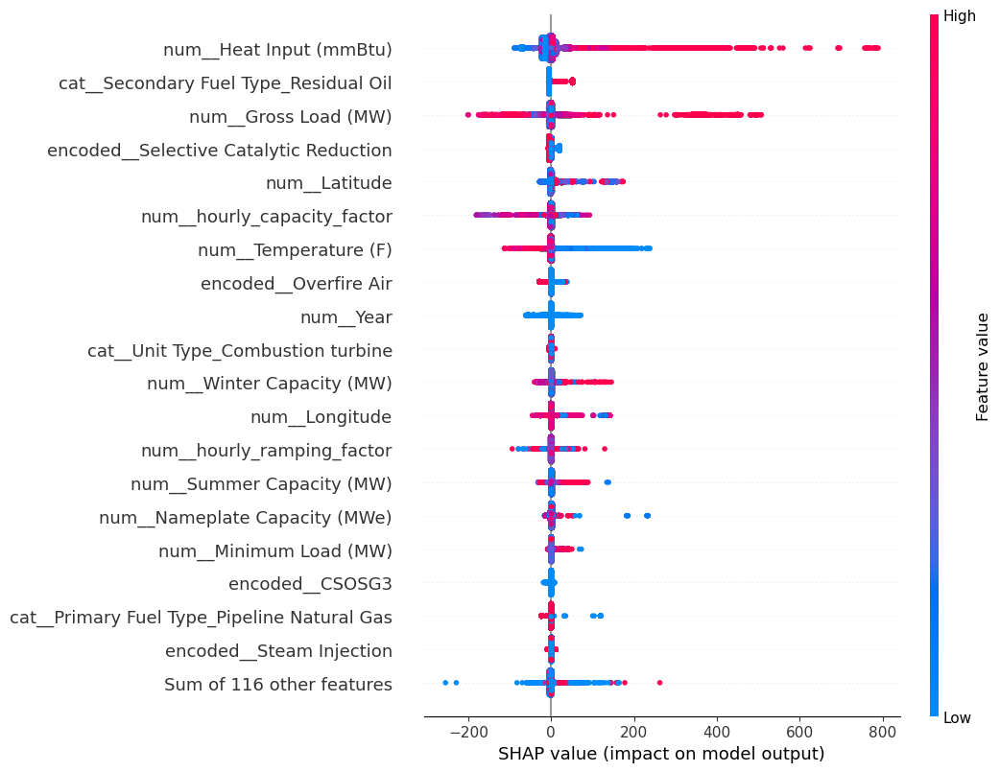

In [10]:
shap.plots.beeswarm(shap_values, max_display=20)

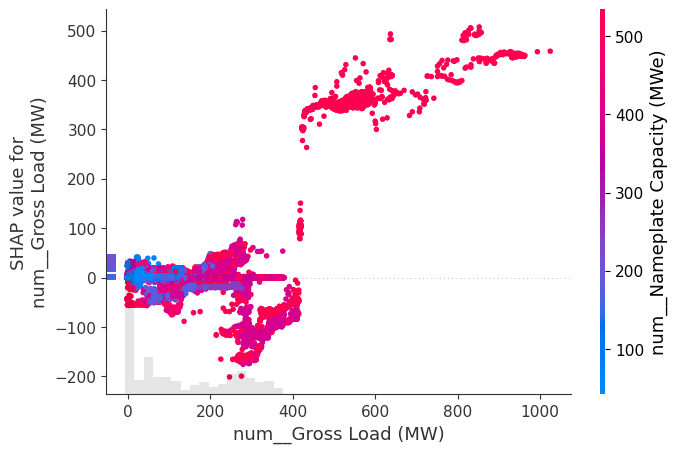

In [11]:
shap.plots.scatter(shap_values[:,"num__Gross Load (MW)"], color=shap_values[:,"num__Nameplate Capacity (MWe)"])

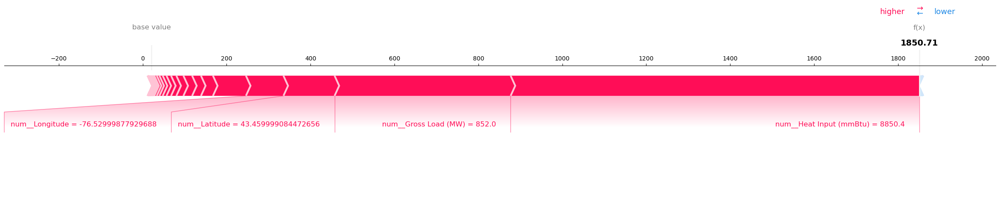

In [12]:

# Fit model and select a single sample
# Show force plot
shap.plots.force(explainer(X_test.iloc[[482884]]), matplotlib=True, contribution_threshold=0.1, figsize=(30,4))

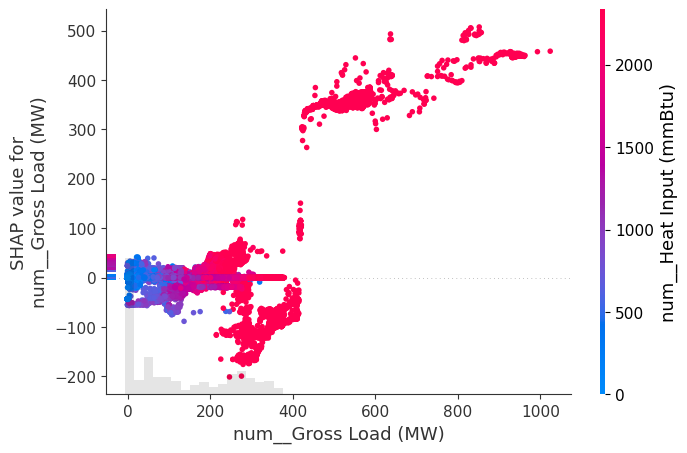

In [33]:
shap.plots.scatter(shap_values[:,"num__Gross Load (MW)"], color=shap_values[:,"num__Heat Input (mmBtu)"])


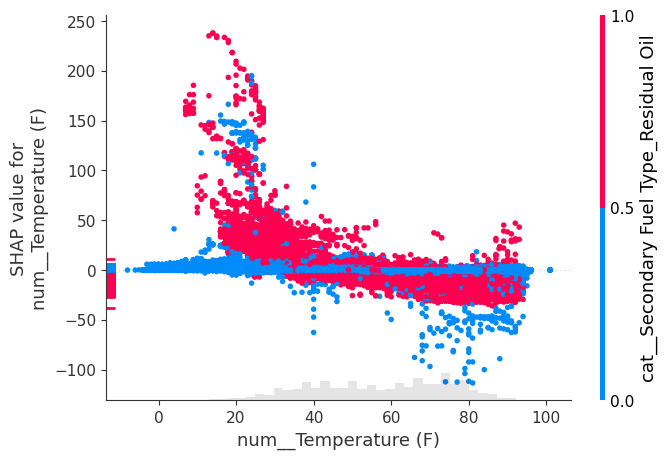

In [32]:
shap.plots.scatter(shap_values[:,"num__Temperature (F)"], color=shap_values[:,"cat__Secondary Fuel Type_Residual Oil"])

# hypothesis: shap values of temp are largely driven by interactions with 
# secondary fuel type residual oil.

In [ ]:
shap.plots.scatter(shap_values[:,"cat__Secondary Fuel Type_Residual Oil"], color=shap_values[:,"num__Temperature (F)"])


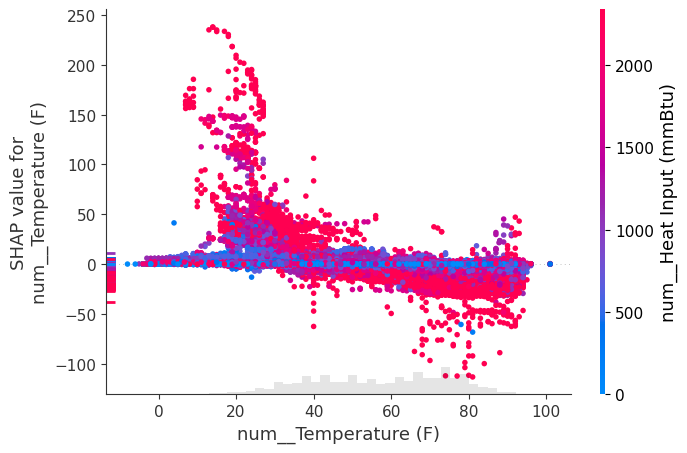

In [31]:
shap.plots.scatter(shap_values[:,"num__Temperature (F)"], color=shap_values[:,"num__Heat Input (mmBtu)"])


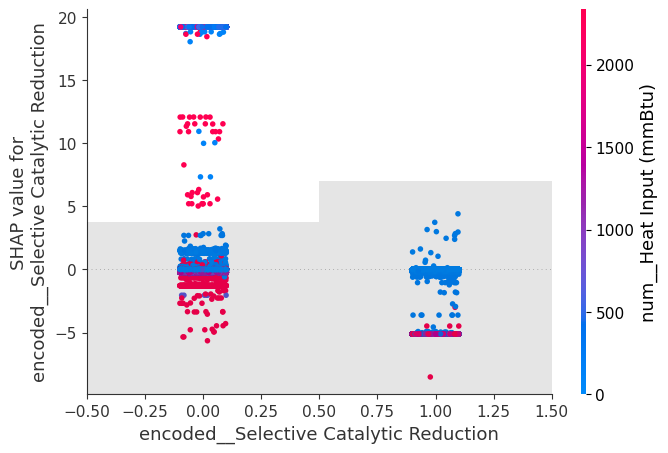

In [24]:
shap.plots.scatter(shap_values[:,"encoded__Selective Catalytic Reduction"], color=shap_values[:,"num__Heat Input (mmBtu)"])


<h4>XGB</h4>

In [1]:
# (using default parameters, no hpo)

<h5>SHAP Values</h5>

In [10]:
explainer = shap.TreeExplainer(xgb_default_model_no_lags)

In [150]:

def model_predict(data_asarray):
    data_asframe = pd.DataFrame(data_asarray, columns=X_train.columns)
    return regressor.predict(data_asframe)

# Sample a small background set
background = shap.sample(X_train, 100)

# Initialize KernelExplainer with the wrapped function
kernelExplainer = shap.KernelExplainer(model_predict, background)

In [ ]:

# KernelSHAP is very much non-deterministic

# Sample to explain
sample = X_test.iloc[[48384]]
sample_array = sample.values

# Store SHAP values across runs
shap_values_list = []

for _ in range(100):
    shap_values = kernelExplainer.shap_values(sample_array, nsamples=1000, silent=True)
    shap_values_list.append(shap_values[0])  # assuming regression

# Stack SHAP values into a matrix
shap_matrix = np.vstack(shap_values_list)

# Compute mean and std deviation
shap_mean = np.mean(shap_matrix, axis=0)
shap_std = np.std(shap_matrix, axis=0)
shap_abs_mean = np.mean(np.abs(shap_matrix), axis=0)

# Create a DataFrame for analysis
shap_df = pd.DataFrame({
    'Feature': X_train.columns,
    'Mean Attribution': shap_mean,
    'Std Dev': shap_std,
    'Mean Abs Attribution': shap_abs_mean
})

# Sort by absolute mean attribution and select top 20
top_20_df = shap_df.sort_values(by='Mean Abs Attribution', ascending=False).head(20)

# Display results
display(top_20_df[['Feature', 'Mean Attribution', 'Std Dev']])

,Feature,Mean Attribution,Std Dev
96,num__Gross Load (MW),20.130447,0.539127
119,encoded__Selective Catalytic Reduction,12.770243,0.514456
97,num__Heat Input (mmBtu),-12.297606,0.736018
121,encoded__Steam Injection,4.915623,0.396901
101,num__hourly_capacity_factor,2.349016,0.623238
98,num__Latitude,-1.877245,0.873427
107,num__Temperature (F),1.118977,0.807711
103,num__Summer Capacity (MW),-0.776240,0.848178
110,encoded__Dry Low NOx Burners,-0.636337,0.814974
82,cat__Primary Fuel Type_Diesel Oil,-0.561028,0.816853


In [ ]:
shap_values = explainer(X_test, approximate=False)

# this took just 1 min

In [ ]:
joblib.dump(shap_values, "NY/Hourly/Concatted File/Modeling/XGB/NOx/Trained Models/shap_values_xgb_default_model_ny_no_lags_no_unmeasured_with_temps.pkl")

In [4]:
shap_values = joblib.load("NY/Hourly/Concatted File/Modeling/XGB/NOx/Trained Models/shap_values_xgb_default_model_ny_no_lags_no_unmeasured_with_temps.pkl")

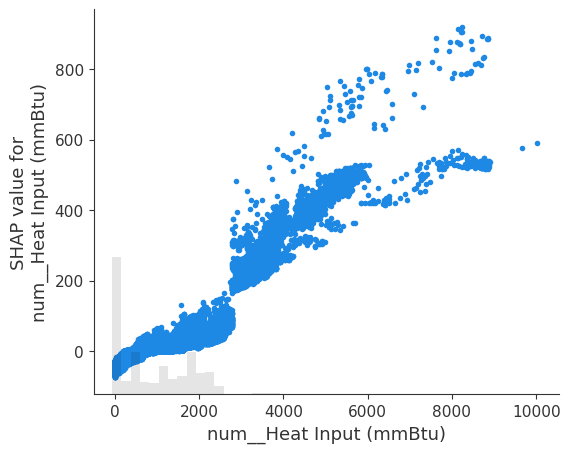

In [6]:
shap.plots.scatter(shap_values[:,"num__Heat Input (mmBtu)"])

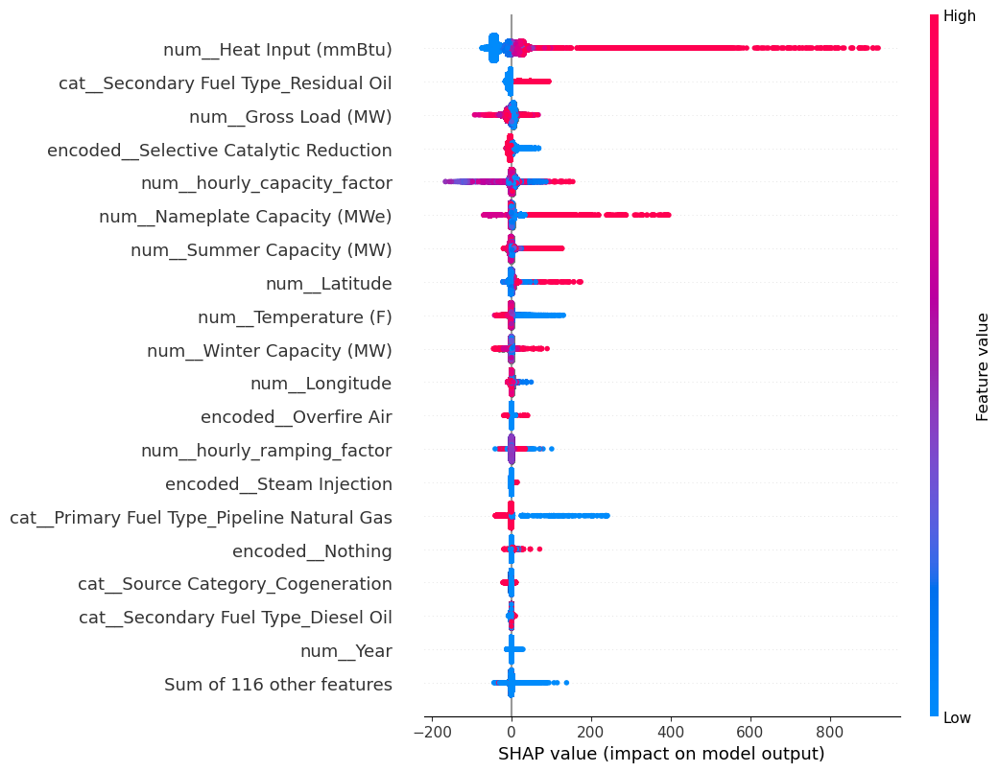

In [5]:
shap.plots.beeswarm(shap_values, max_display=20)


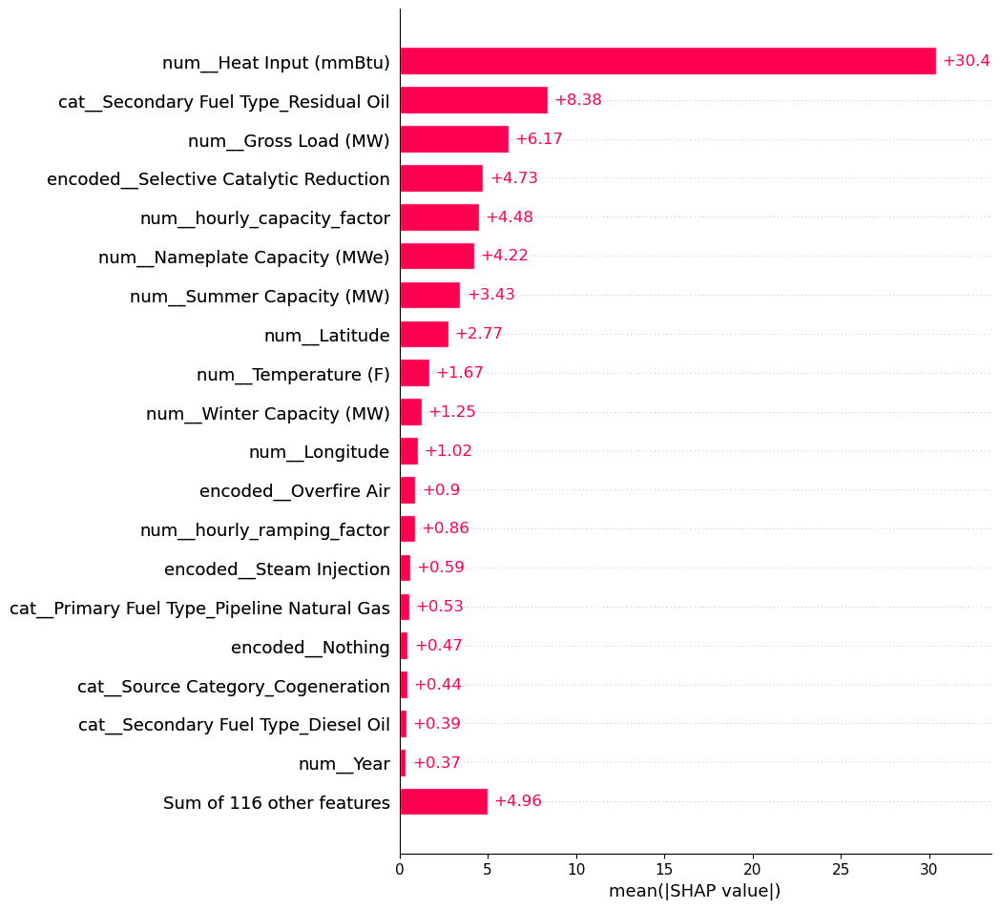

In [22]:
shap.plots.bar(shap_values, max_display=20) # global mean absolute shap values for comparison

In [ ]:
# define feature groups (important for aggregation of encoded cols)
feature_groups = {
    "Source Category": [
        'cat__Source Category_Cogeneration',
        'cat__Source Category_Electric Utility',
        'cat__Source Category_Missing'
    ],
    
    "NOx Phase": [
        'cat__NOx Phase_Early Election',
        'cat__NOx Phase_Nothing',
        'cat__NOx Phase_Phase 1 Group 1',
        'cat__NOx Phase_Phase 2 Group 1'
    ],
    
    "Unit Type": [
        'cat__Unit Type_Circulating fluidized bed boiler',
        'cat__Unit Type_Combined cycle',
        'cat__Unit Type_Combined cycle (Started Feb 23, 2020)',
        'cat__Unit Type_Combustion turbine',
        'cat__Unit Type_Dry bottom wall-fired boiler',
        'cat__Unit Type_Other boiler',
        'cat__Unit Type_Tangentially-fired'
    ],
    
    "Primary Fuel Type": [
        'cat__Primary Fuel Type_Coal',
        'cat__Primary Fuel Type_Diesel Oil',
        'cat__Primary Fuel Type_Natural Gas',
        'cat__Primary Fuel Type_Other Oil',
        'cat__Primary Fuel Type_Pipeline Natural Gas',
        'cat__Primary Fuel Type_Residual Oil',
        'cat__Primary Fuel Type_Wood'
    ],
    
    "Secondary Fuel Type": [
        'cat__Secondary Fuel Type_Diesel Oil',
        'cat__Secondary Fuel Type_Natural Gas, Wood',
        'cat__Secondary Fuel Type_Nothing',
        'cat__Secondary Fuel Type_Other Oil',
        'cat__Secondary Fuel Type_Other Solid Fuel, Petroleum Coke, Tire Derived Fuel',
        'cat__Secondary Fuel Type_Pipeline Natural Gas',
        'cat__Secondary Fuel Type_Residual Oil',
        'cat__Secondary Fuel Type_Wood'
    ],

    "Gross Load (MW)": ['num__Gross Load (MW)'],
    "Heat Input (mmBtu)": ['num__Heat Input (mmBtu)'],
    "Latitude": ['num__Latitude'],
    "Longitude": ['num__Longitude'],
    "Nameplate Capacity (MWe)": ['num__Nameplate Capacity (MWe)'],
    "hourly_capacity_factor": ['num__hourly_capacity_factor'],
    "hourly_ramping_factor": ['num__hourly_ramping_factor'],
    "Summer Capacity (MW)": ['num__Summer Capacity (MW)'],
    "Winter Capacity (MW)": ['num__Winter Capacity (MW)'],
    "Minimum Load (MW)": ['num__Minimum Load (MW)'],
    "Year": ['num__Year'],

    "Control Technologies": [
        'encoded__Ammonia Injection',
        'encoded__Combustion Modification/Fuel Reburning',
        'encoded__Dry Low NOx Burners',
        'encoded__Low NOx Burner Technology (Dry Bottom only)',
        'encoded__Low NOx Burner Technology w/ Closed-coupled OFA',
        'encoded__Low NOx Burner Technology w/ Closed-coupled/Separated OFA',
        'encoded__Low NOx Burner Technology w/ Overfire Air',
        'encoded__Low NOx Burner Technology w/ Separated OFA',
        'encoded__Nothing',
        'encoded__Other',
        'encoded__Overfire Air',
        'encoded__Selective Catalytic Reduction',
        'encoded__Selective Non-catalytic Reduction',
        'encoded__Steam Injection',
        'encoded__Water Injection',
        'encoded__Water Injection (Began Jul 01, 2022)'
    ],

    "Programs / Regulations": [
        'encoded__ARP',
        'encoded__CSNOX',
        'encoded__CSOSG2',
        'encoded__CSOSG2E',
        'encoded__CSOSG3',
        'encoded__CSSO2G1',
        'encoded__MATS',
        'encoded__Missing',
        'encoded__NSPS4T',
        'encoded__RGGI',
        'encoded__SIPNOX'
    ],

    "Hour": [
        'encoded__Hour_sin',
        'encoded__Hour_cos'
    ],
    "Day": [
        'encoded__Day_sin',
        'encoded__Day_cos'
    ],
    "Month": [
        'encoded__Month_sin',
        'encoded__Month_cos'
    ],

    "Lag Features": [
        'encoded__lag_1_hour',
        'encoded__lag_2_hours',
        'encoded__lag_1_day',
        'encoded__lag_2_days',
        'encoded__lag_1_week',
        'encoded__lag_1_month',
        'encoded__lag_1_year'
    ]
}

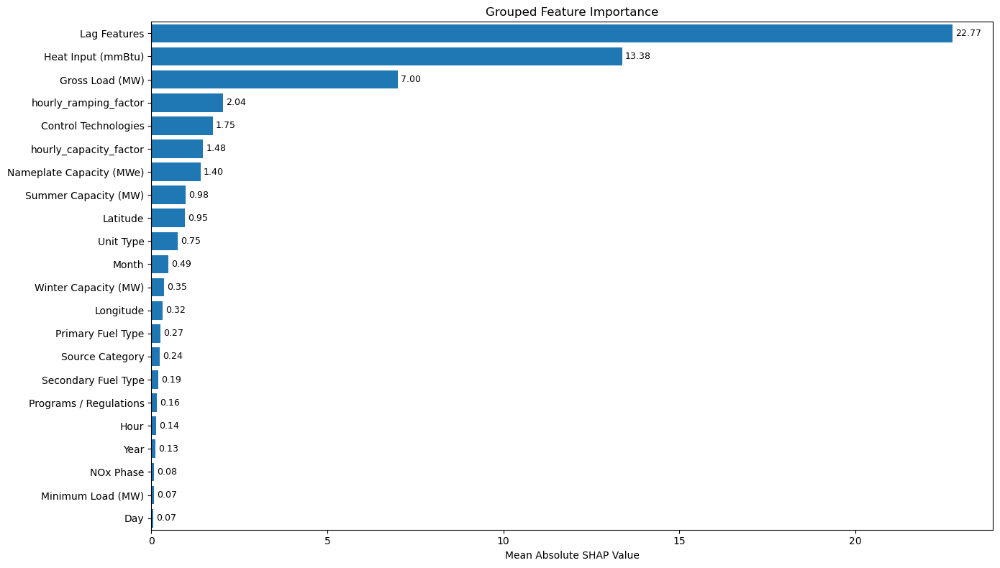

In [ ]:
# Aggregate (sum) the shap values of encoded columns

# create series of mean absolute SHAP values per feature (using feature name as index)
mean_abs_shap = np.abs(shap_values.values).mean(axis=0) 
shap_importance = pd.Series(mean_abs_shap, index=shap_values.feature_names)

# aggregate by feature groups (sum the mean absolute values within pre-defined groups)
group_importance = {}
for group, features in feature_groups.items():
    group_importance[group] = shap_importance[features].sum() 

group_importance = pd.Series(group_importance).sort_values(ascending=False)

# plot
fig, ax = plt.subplots(figsize=(14, 8))
bars = ax.barh(group_importance.index, group_importance.values)
group_importance.plot(kind='barh')
ax.bar_label(bars, fmt='%.2f', label_type='edge', padding=3, fontsize=9) # add bar labels
plt.gca().invert_yaxis()  # invert to get largest at top
plt.title('Grouped Feature Importance')
plt.xlabel('Mean Absolute SHAP Value')
plt.tight_layout()
plt.show()


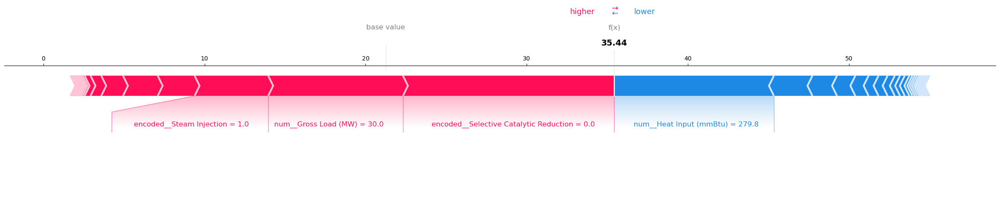

In [ ]:
shap.plots.force(explainer(X_test.iloc[[48384]]), matplotlib=True, contribution_threshold=0.1, figsize=(30,4))

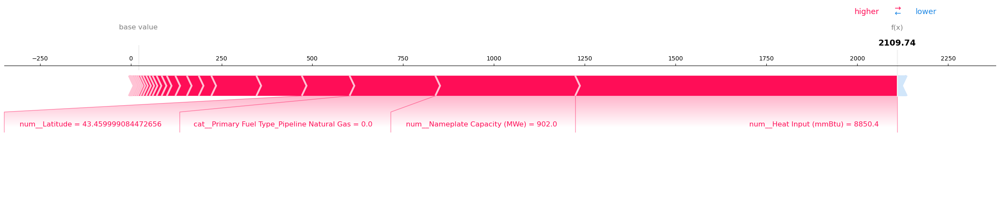

In [ ]:
shap.plots.force(explainer(X_test.iloc[[482884]]), matplotlib=True, contribution_threshold=0.1, figsize=(30,4))


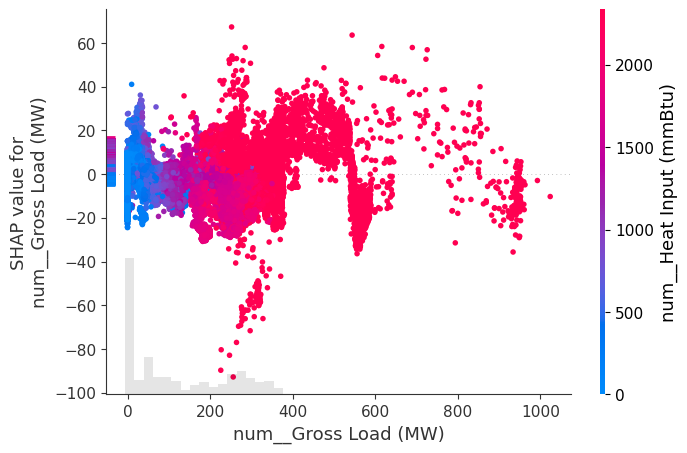

In [73]:
shap.plots.scatter(shap_values[:,"num__Gross Load (MW)"], color=shap_values[:,"num__Heat Input (mmBtu)"])

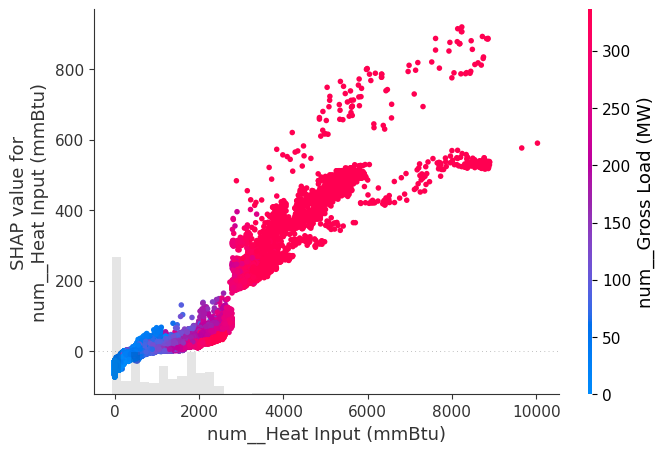

In [65]:
shap.plots.scatter(shap_values[:,"num__Heat Input (mmBtu)"], color=shap_values[:,"num__Gross Load (MW)"])

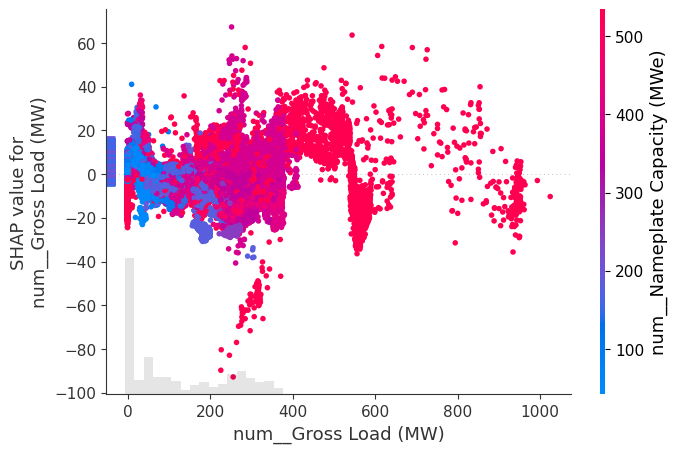

In [64]:
shap.plots.scatter(shap_values[:,"num__Gross Load (MW)"], color=shap_values[:,"num__Nameplate Capacity (MWe)"])

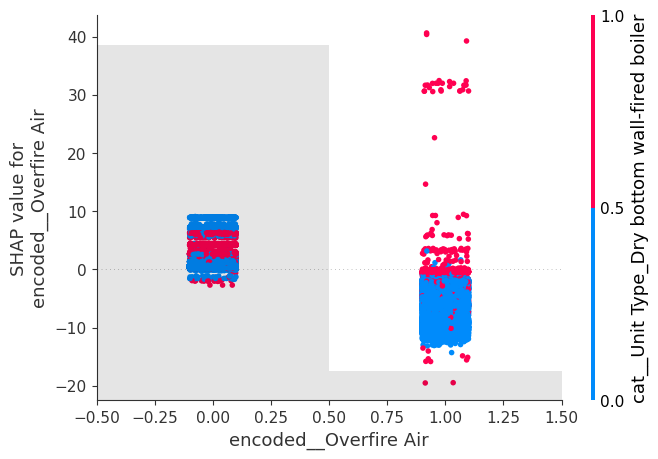

In [25]:
shap.plots.scatter(shap_values[:,"encoded__Overfire Air"], color=shap_values[:,"cat__Unit Type_Dry bottom wall-fired boiler"])


In [14]:
campd_df[campd_df["Overfire Air"] == 1]["NOx Mass (lbs)"].describe()

count    207093.000000
mean         95.305443
std         121.981155
min           0.000000
25%          12.450000
50%          64.099998
75%         127.099998
max        2738.500000
Name: NOx Mass (lbs), dtype: float64

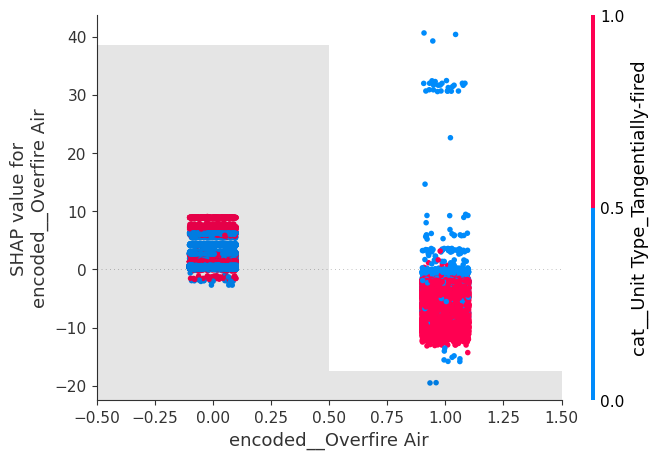

In [22]:
shap.plots.scatter(shap_values[:,"encoded__Overfire Air"], color=shap_values[:,"cat__Unit Type_Tangentially-fired"])


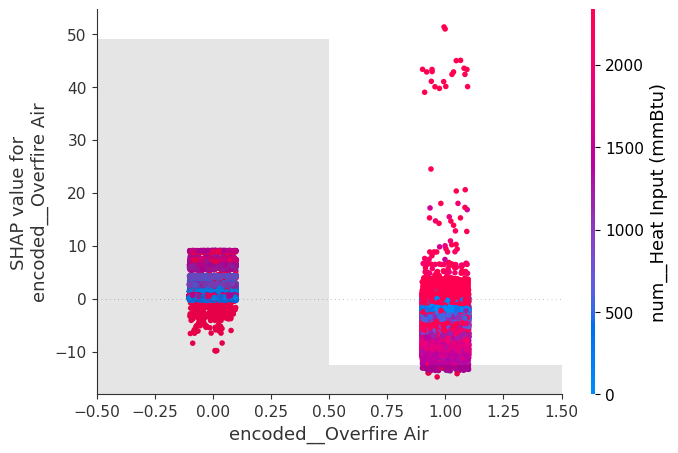

In [ ]:
shap.plots.scatter(shap_values[:,"encoded__Overfire Air"], color=shap_values[:,"num__Heat Input (mmBtu)"])

# OFA shows the expected negative effect when Heat Input
# is low to moderate, but a positive effect when Heat Input is high

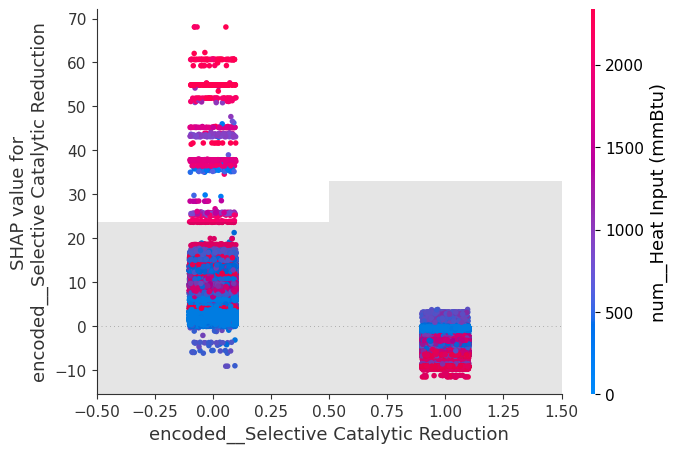

In [ ]:
shap.plots.scatter(shap_values[:,"encoded__Selective Catalytic Reduction"], color=shap_values[:,"num__Heat Input (mmBtu)"])


c:\Users\marce\anaconda3\Lib\site-packages\shap\plots\_scatter.py:449: RuntimeWarning: invalid value encountered in greater
  min_dist = np.min(diffs[diffs > 1e-8])


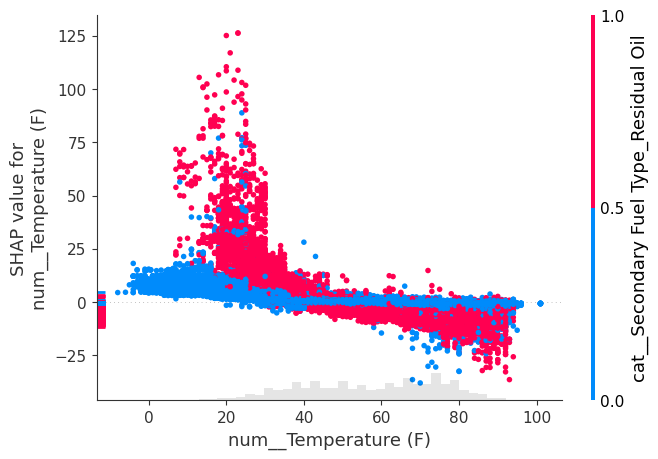

In [ ]:
shap.plots.scatter(shap_values[:,"num__Temperature (F)"], color=shap_values[:,"cat__Secondary Fuel Type_Residual Oil"])

# hypothesis: shap values of temp are largely driven by interactions with 
# secondary fuel type residual oil.

c:\Users\marce\anaconda3\Lib\site-packages\shap\plots\_scatter.py:449: RuntimeWarning: invalid value encountered in greater
  min_dist = np.min(diffs[diffs > 1e-8])


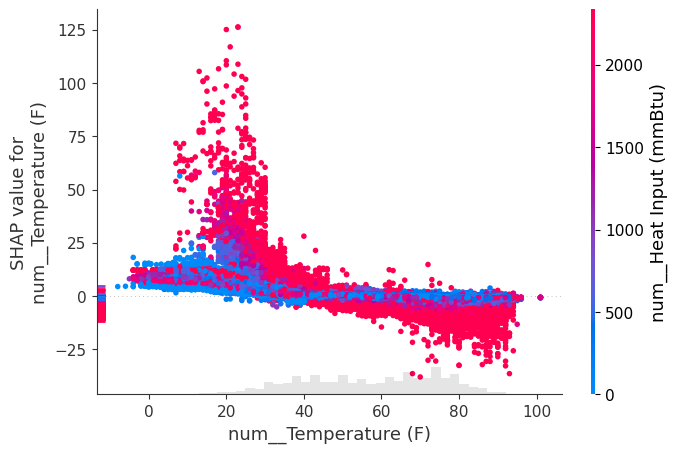

In [57]:
shap.plots.scatter(shap_values[:,"num__Temperature (F)"], color=shap_values[:,"num__Heat Input (mmBtu)"])

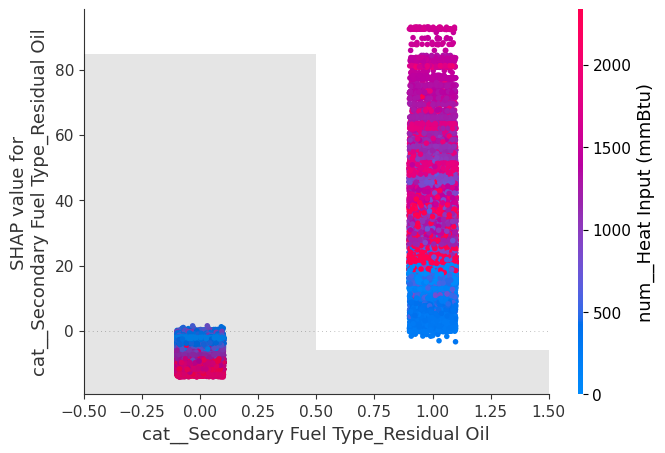

In [85]:
shap.plots.scatter(shap_values[:,"cat__Secondary Fuel Type_Residual Oil"], color=shap_values[:,"num__Heat Input (mmBtu)"])

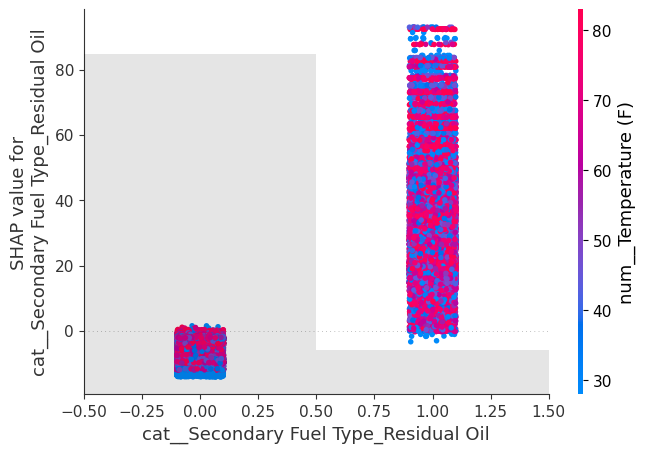

In [ ]:
shap.plots.scatter(shap_values[:,"cat__Secondary Fuel Type_Residual Oil"], color=shap_values[:,"num__Temperature (F)"])

# residual oil likely interacts with many other features different from temp making its shap value more complex
# (as opposed to temp where interactions with HI and Oil are clearly visible in a scatter plot, they are correlated with each other too making directionality more consistent)

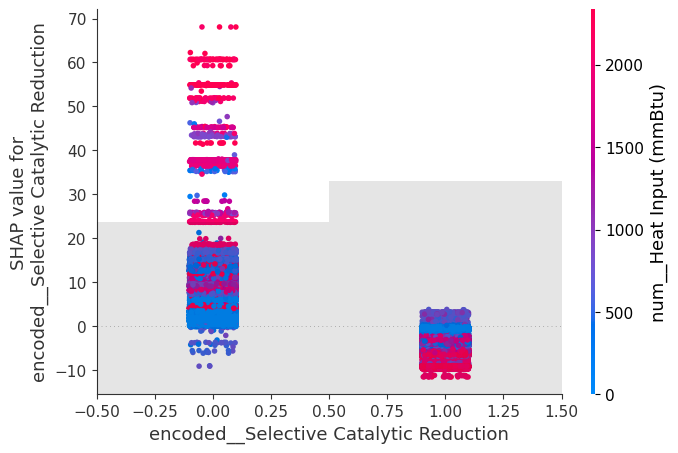

In [ ]:
# interaction between SCR and Heat Input is straightforward
# If SCR is present and heat input is high, then effect towards emissions is highly negative (negative SHAP value)
# If SCR is not present and heat input is high, then effect towards emissions is extremely large 

# note only units with relatively low heat input seem to have SCR
shap.plots.scatter(shap_values[:,"encoded__Selective Catalytic Reduction"], color=shap_values[:,"num__Heat Input (mmBtu)"])

<h5>SHAP Interaction Values</h5>

In [ ]:
X_test_sample = X_test.sample(n=100000, random_state=42)

interaction_values_shap = explainer.shap_interaction_values(X_test_sample)

# took 61 mins

In [ ]:
joblib.dump(interaction_values_shap, "NY/Hourly/Concatted File/Modeling/XGB/NOx/Trained Models/interaction_values_shap_xgb_default_model_ny_no_lags_no_unmeasured_with_temps.pkl")

In [29]:
interaction_values_shap = joblib.load("NY/Hourly/Concatted File/Modeling/XGB/NOx/Trained Models/interaction_values_shap_xgb_default_model_ny_no_lags_no_unmeasured_with_temps.pkl")

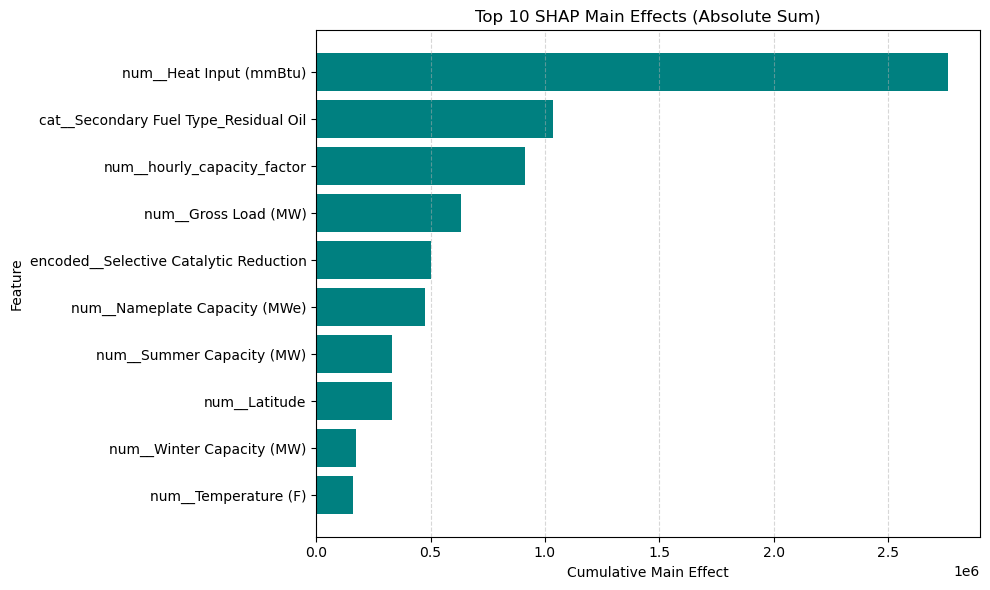

In [182]:
# Extract absolute main effects for all features
main_effect_totals = []
feature_names = X_test.columns

for f in range(len(feature_names)):
    main_effect = abs(interaction_values_shap[:, f, f]).sum()
    main_effect_totals.append((feature_names[f], main_effect))

# Sort by contribution
main_effect_totals.sort(key=lambda x: x[1], reverse=True)

# Top 10 features
top_features = main_effect_totals[:10]
features = [item[0] for item in top_features]
effects = [item[1] for item in top_features]

# Plot
plt.figure(figsize=(10, 6))
plt.barh(features[::-1], effects[::-1], color='teal')
plt.title("Top 10 SHAP Main Effects (Absolute Sum)")
plt.xlabel("Cumulative Main Effect")
plt.ylabel("Feature")
plt.grid(True, axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

In [41]:
f = 94 # Secondary Fuel Type Residual Oil
main_effects = interaction_values_shap[:, f, f]
interactions = interaction_values_shap[:, f, :].sum(axis=1) - main_effects

In [179]:
total_main_effects = abs(main_effects).sum()
formatted = f"{total_main_effects:,.3f}"
print(formatted)

1,033,591.562


In [180]:
total_interaction = abs(interactions).sum()
print(f"{total_interaction:,.3f}")
print(f"{total_interaction/total_main_effects:,.3f}")

535,880.000
0.518


In [30]:
f = 97 # Heat Input
main_effects = interaction_values_shap[:, f, f]
interactions = interaction_values_shap[:, f, :].sum(axis=1) - main_effects

In [176]:
total_main_effects = abs(main_effects).sum()
formatted = f"{total_main_effects:,.3f}"
print(formatted)

2,763,732.250


In [177]:
total_interaction = abs(interactions).sum()
print(f"{total_interaction:,.3f}")
print(f"{total_interaction/total_main_effects:,.3f}")

1,599,074.250
0.579


In [165]:
shap_values.feature_names[97]

'num__Heat Input (mmBtu)'

In [ ]:
# first we explore how consistent the SI are with SV

In [ ]:
interaction_values_shap.shape

(100000, 135, 135)

In [ ]:
interaction_values_shap[0].sum()

# interaction_values_shap[i][j][j] gives the main effect of feature j for sample i
# interaction_values_shap[i][j][k] gives the interaction effect of feature j and k for sample i (this is symmetric)

-21.352325

In [ ]:
shap_values.feature_names[97]

'num__Heat Input (mmBtu)'

In [ ]:
# compare Heat Input shap value computed from interaction values for loc 306816
# and actual shap value for iloc 334080 (which is loc 306816)

print(interaction_values_shap[0][97].sum())
print(shap_values[334080][97].values)

-42.899097
-42.899097


In [ ]:
# now compare global absolute mean shap values for Heat Input to ensure consistency

print(np.abs(interaction_values_shap[:, 97, :].sum(axis=1)).mean()) # here we first manually compute shap values by iterating over all samples, looking at the interaction array for feature 97 (HI) and sum them to compute the shap value. Then we take the mean absolute val (do axis=1 to sum over each sample (each "row"))
print(np.abs(shap_values.values[:, 97]).mean())

30.454552
30.403566


In [ ]:
f = 97
main_effects = interaction_values_shap[:, f, f]
interactions = interaction_values_shap[:, f, :].sum(axis=1) - main_effects

In [ ]:
# compute total difference in global shap values between the two calculations

global_shap_vals_interact = np.zeros(interaction_values_shap.shape[1])
global_shap_vals_original = np.zeros(interaction_values_shap.shape[1])

# 
for f in range(interaction_values_shap.shape[1]):
    # Sum interaction values for feature f across all interactions (axis=2),
    # then take absolute value and average over samples (axis=0)
    
    global_shap_vals_interact[f] = np.abs(interaction_values_shap[:, f, :].sum(axis=1)).mean()


    # Mean absolute shap value for feature f from original shap values
    global_shap_vals_original[f] = np.abs(shap_values.values[:, f]).mean()

In [ ]:
print(np.abs(main_effects + interactions).mean()) # should be equal to the mean absolute shap value for feature f

30.454552


In [ ]:
global_shap_vals_interact[97]


30.454551696777344

In [ ]:
global_shap_vals_original[97]

30.403566360473633

Mean absolute difference: 0.001388
Max absolute difference: 0.050985
Min absolute difference: 0.000000


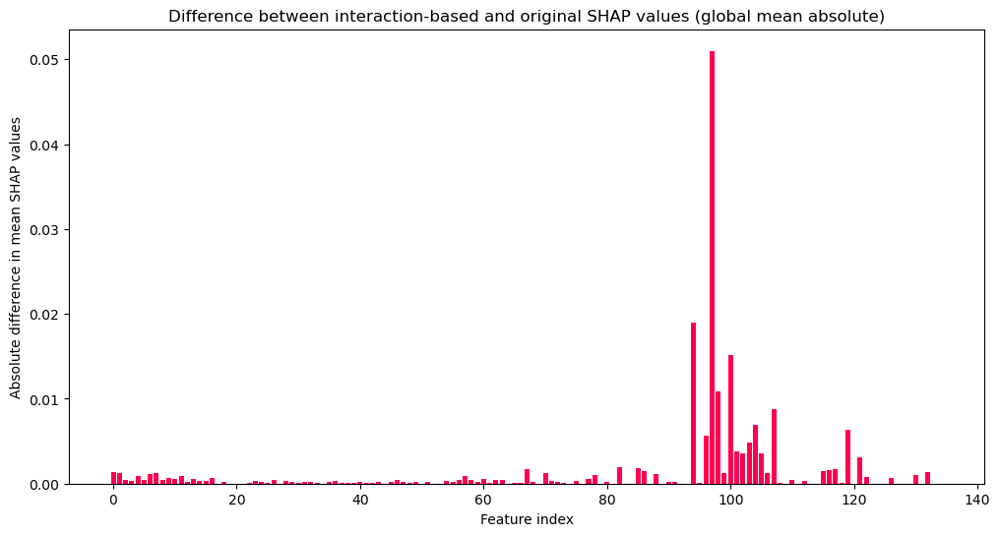

In [ ]:
# Compute the absolute differences between the two sets
differences = np.abs(global_shap_vals_interact - global_shap_vals_original)

# Summary stats
print(f"Mean absolute difference: {differences.mean():.6f}")
print(f"Max absolute difference: {differences.max():.6f}")
print(f"Min absolute difference: {differences.min():.6f}")

plt.figure(figsize=(12, 6))
plt.bar(range(len(differences)), differences, color='#FF0051')
plt.xlabel('Feature index')
plt.ylabel('Absolute difference in mean SHAP values')
plt.title('Difference between interaction-based and original SHAP values (global mean absolute)')
plt.show()

# very small differences, maximum is 0.05

In [ ]:
feature_names = shap_values.feature_names

n_samples, n_features, _ = interaction_values_shap.shape

# Mean interaction values for each feature pair (averaged over samples)
signed_mean_interactions = interaction_values_shap.mean(axis=0)  # shape (n_features, n_features)
abs_mean_interactions = np.abs(interaction_values_shap).mean(axis=0)

# Flatten to 1D arrays for sorting (before it was shape (n_features, n_features))
flat_mean_abs = abs_mean_interactions.flatten()
flat_mean_signed = signed_mean_interactions.flatten()
# it becomes a 1D array of shape (n_features^2)

# Indices to map back to (feature1, feature2)
idxs = np.array([(i, j) for i in range(n_features) for j in range(n_features)])
# creates an array of tuples (i, j) for each feature pair (each index) with length n_features^2
# we use it to map feature names back later

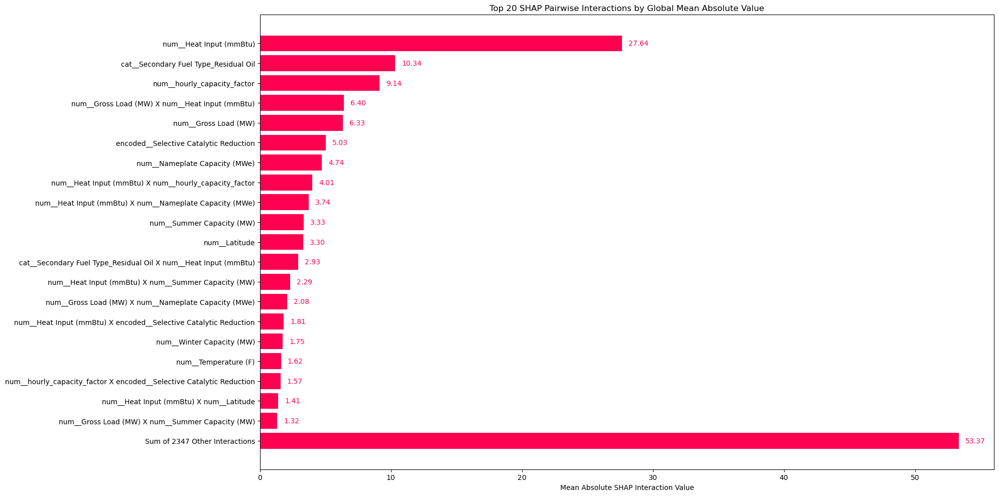

In [ ]:
# Indices to map back to (feature1, feature2), filtering symmetric duplicates
idxs = np.array([(i, j) for i in range(n_features) for j in range(i, n_features)])
# Now idxs only contains pairs where i <= j to avoid duplicates

# Updated flat_mean_abs and flat_mean_signed to account for symmetry reduction
flat_mean_abs = abs_mean_interactions[np.triu_indices(n_features)].flatten()
flat_mean_signed = signed_mean_interactions[np.triu_indices(n_features)].flatten()
# Using np.triu_indices ensures only upper-triangular values are considered (i <= j)

# Filter out zero values by masking them before sorting
nonzero_mask = flat_mean_abs > 0
nonzero_indices = np.where(nonzero_mask)[0]
nonzero_values = flat_mean_abs[nonzero_mask]

# Get top 20 indices (in descending order) from non-zero interactions only
top20_abs_idx_nonzero = nonzero_indices[np.argsort(nonzero_values)[-20:][::-1]]
top20_abs_set = set(top20_abs_idx_nonzero)

# Values and labels for top 20 non-zero interactions
top20_abs = [((feature_names[i], feature_names[j]), flat_mean_abs[idx]) 
             for idx, (i, j) in zip(top20_abs_idx_nonzero, idxs[top20_abs_idx_nonzero])]
labels_abs = [f"{f1}" if f1 == f2 else f"{f1} X {f2}" for (f1, f2), _ in top20_abs]
raw_values_abs = [v for _, v in top20_abs]

# Sum of others excluding top 20 and zero interactions
all_nonzero_indices = set(nonzero_indices)
other_abs_idx = list(all_nonzero_indices - top20_abs_set)
sum_other_abs = flat_mean_abs[other_abs_idx].sum()

# Append summary
labels_abs.append(f"Sum of {len(other_abs_idx)} Other Interactions")
raw_values_abs.append(sum_other_abs)

# All absolute values, one color
bar_colors_abs = ['#FF0051'] * len(labels_abs)

# Plot Absolute Interactions
plt.figure(figsize=(20, 10))
bars_abs = plt.barh(range(len(labels_abs)), raw_values_abs, color=bar_colors_abs)
plt.yticks(range(len(labels_abs)), labels_abs)
plt.xlabel("Mean Absolute SHAP Interaction Value")
plt.title("Top 20 SHAP Pairwise Interactions by Global Mean Absolute Value")
plt.gca().invert_yaxis()

# Annotate bars
for bar, val in zip(bars_abs, raw_values_abs):
    plt.text(bar.get_width() + 0.5,
             bar.get_y() + bar.get_height() / 2,
             f"{val:.2f}", va='center', ha='left', color=bar.get_facecolor())

plt.tight_layout()
plt.show()

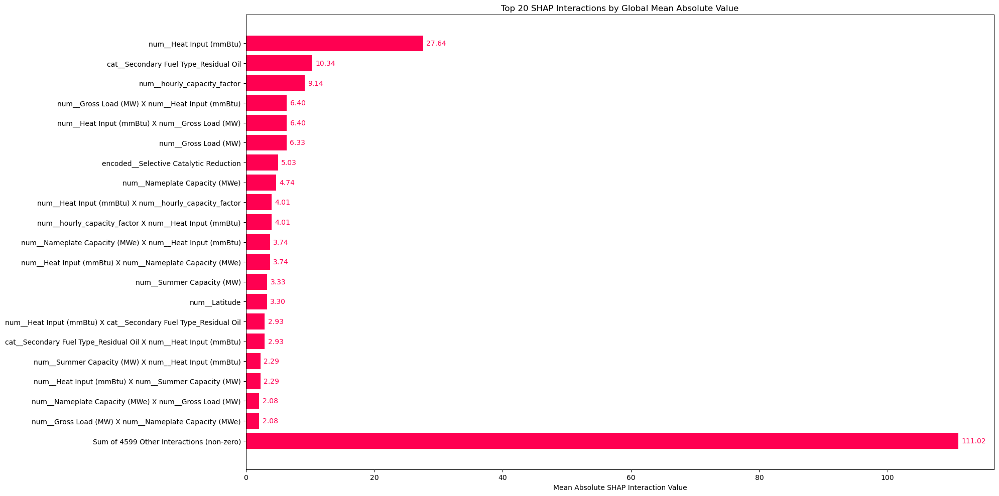

In [ ]:
# Top 20 Mean Absolute SHAP Interactions

# Filter out zero values by masking them before sorting
nonzero_mask = flat_mean_abs > 0
nonzero_indices = np.where(nonzero_mask)[0]
nonzero_values = flat_mean_abs[nonzero_mask]

# Get top 20 indices (in descending order) from non-zero interactions only
top20_abs_idx_nonzero = nonzero_indices[np.argsort(nonzero_values)[-20:][::-1]]
top20_abs_set = set(top20_abs_idx_nonzero)

# Values and labels for top 20 non-zero interactions
top20_abs = [((feature_names[i], feature_names[j]), flat_mean_abs[idx]) 
             for idx, (i, j) in zip(top20_abs_idx_nonzero, idxs[top20_abs_idx_nonzero])]
labels_abs = [f"{f1}" if f1 == f2 else f"{f1} X {f2}" for (f1, f2), _ in top20_abs]
raw_values_abs = [v for _, v in top20_abs]

# Sum of others excluding top 20 and zero interactions
all_nonzero_indices = set(nonzero_indices)
other_abs_idx = list(all_nonzero_indices - top20_abs_set)
sum_other_abs = flat_mean_abs[other_abs_idx].sum()

# Append summary
labels_abs.append(f"Sum of {len(other_abs_idx)} Other Interactions")
raw_values_abs.append(sum_other_abs)

# All absolute values, one color
bar_colors_abs = ['#FF0051'] * len(labels_abs)

# Plot Absolute Interactions
plt.figure(figsize=(20, 10))
bars_abs = plt.barh(range(len(labels_abs)), raw_values_abs, color=bar_colors_abs)
plt.yticks(range(len(labels_abs)), labels_abs)
plt.xlabel("Mean Absolute SHAP Interaction Value")
plt.title("Top 20 SHAP Interactions by Global Mean Absolute Value")
plt.gca().invert_yaxis()

# Annotate bars
for bar, val in zip(bars_abs, raw_values_abs):
    plt.text(bar.get_width() + 0.5,
             bar.get_y() + bar.get_height() / 2,
             f"{val:.2f}", va='center', ha='left', color=bar.get_facecolor())

plt.tight_layout()
plt.show()


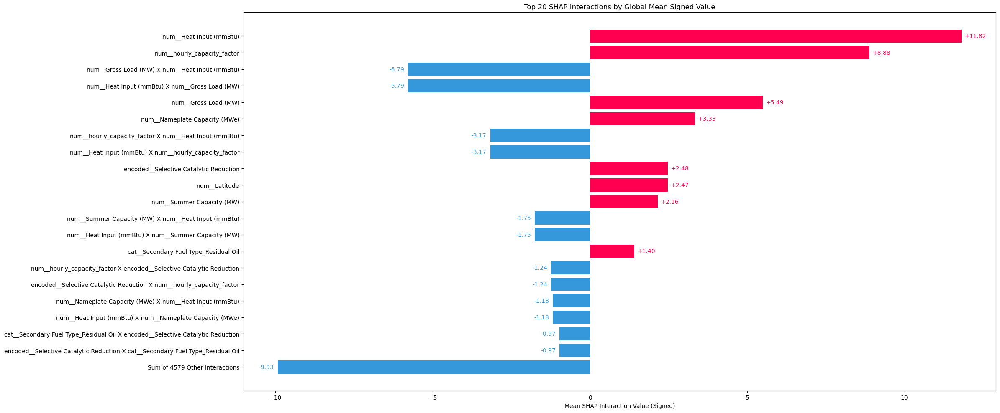

In [ ]:
# Mask to exclude zero interactions
nonzero_mask_signed = flat_mean_signed != 0
nonzero_indices_signed = np.where(nonzero_mask_signed)[0]
nonzero_values_signed = flat_mean_signed[nonzero_mask_signed]

# Top 20 positive interactions (non-zero)
pos_mask = nonzero_values_signed > 0
pos_indices = nonzero_indices_signed[pos_mask]
pos_values = nonzero_values_signed[pos_mask]
top20_signed_idx = pos_indices[np.argsort(pos_values)[-20:]]

# Top 20 negative interactions (non-zero)
neg_mask = nonzero_values_signed < 0
neg_indices = nonzero_indices_signed[neg_mask]
neg_values = nonzero_values_signed[neg_mask]
top20_neg_idx = neg_indices[np.argsort(neg_values)[:20]]

# Combine and deduplicate
top20_signed_combined_idx = np.unique(np.concatenate((top20_signed_idx, top20_neg_idx)))

# Create list of (features, value)
top20_signed_combined = [((feature_names[i], feature_names[j]), flat_mean_signed[idx])
                         for idx, (i, j) in zip(top20_signed_combined_idx, idxs[top20_signed_combined_idx])]

# Sort by absolute value descending and keep top 20
top20_signed_combined = sorted(top20_signed_combined, key=lambda x: abs(x[1]), reverse=True)[:20]

# Extract labels and values for plotting
labels_signed = [f"{f1}" if f1 == f2 else f"{f1} X {f2}" for (f1, f2), _ in top20_signed_combined]
raw_values_signed = [v for _, v in top20_signed_combined]
bar_colors_signed = ['#FF0051' if v >= 0 else '#3498DB' for v in raw_values_signed]

# Sum of all other non-zero signed interactions (excluding the top 20 combined)
top_combined_idx_set = set(top20_signed_combined_idx)
all_nonzero_indices_set = set(nonzero_indices_signed)
other_signed_idx = list(all_nonzero_indices_set - top_combined_idx_set)
sum_other_signed = flat_mean_signed[other_signed_idx].sum()

# Append summary bar
labels_signed.append(f"Sum of {len(other_signed_idx)} Other Interactions")
raw_values_signed.append(sum_other_signed)
bar_colors_signed.append('#FF0051' if sum_other_signed >= 0 else '#3498DB')

# Plot Signed Interactions
plt.figure(figsize=(24, 10))
bars_signed = plt.barh(range(len(labels_signed)), raw_values_signed, color=bar_colors_signed)
plt.yticks(range(len(labels_signed)), labels_signed)
plt.xlabel("Mean SHAP Interaction Value (Signed)")
plt.title("Top 20 SHAP Interactions by Global Mean Signed Value")
plt.gca().invert_yaxis()

# Annotate bars
for bar, val in zip(bars_signed, raw_values_signed):
    offset = 0.1 * np.sign(val) - (0.5 if val < 0 else 0)
    plt.text(bar.get_width() + offset,
             bar.get_y() + bar.get_height() / 2,
             f"{val:+.2f}", va='center', ha='left', color=bar.get_facecolor())

plt.tight_layout()
plt.show()

# would be better for individual predictions, interactions cancel each other out here so not very meaningful overall


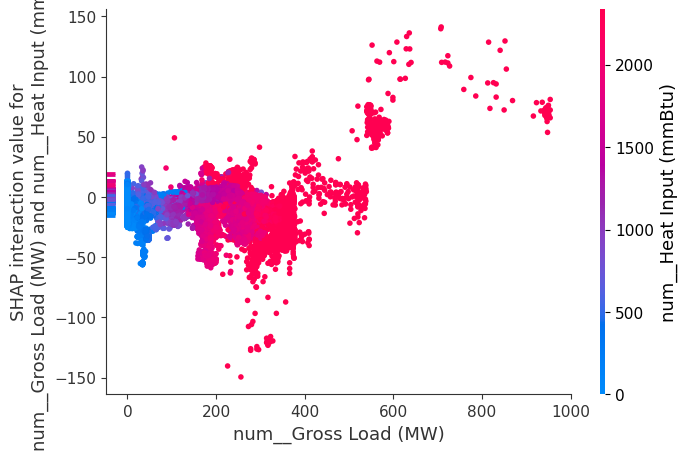

In [ ]:
shap.dependence_plot(("num__Gross Load (MW)", "num__Heat Input (mmBtu)"), interaction_values_shap, X_test_sample, show=True)

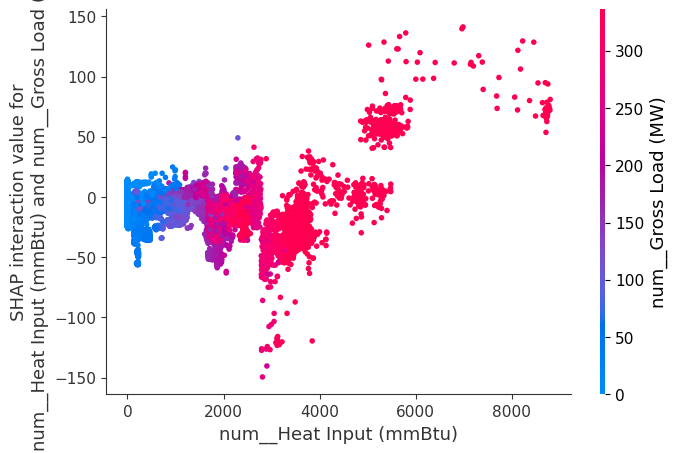

In [ ]:
shap.dependence_plot(("num__Heat Input (mmBtu)", "num__Gross Load (MW)"), interaction_values_shap, X_test_sample, show=True)

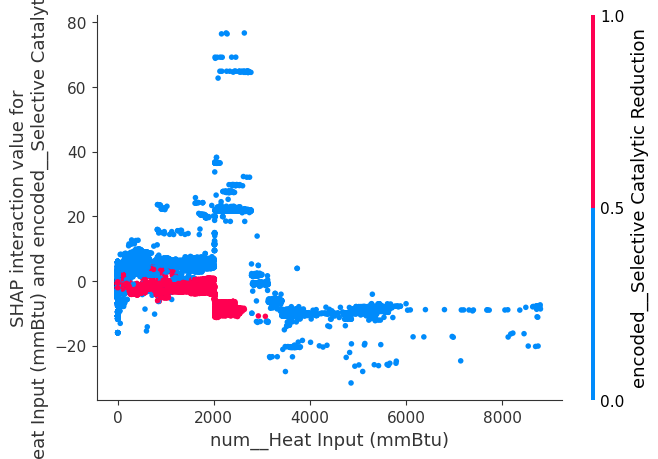

In [ ]:
shap.dependence_plot(("num__Heat Input (mmBtu)", "encoded__Selective Catalytic Reduction"), interaction_values_shap, X_test_sample, show=True)

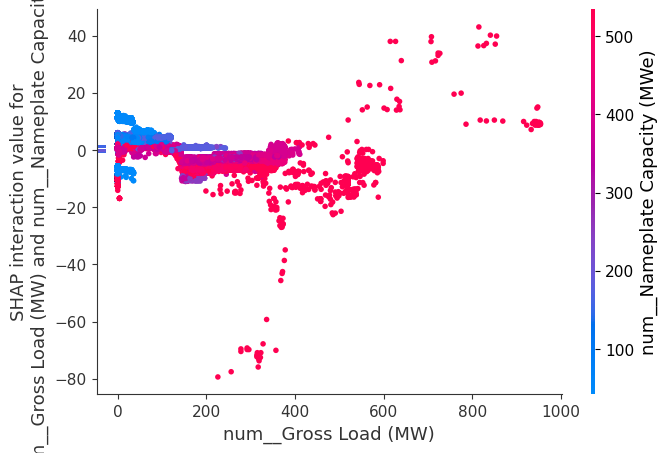

In [ ]:
shap.dependence_plot(("num__Gross Load (MW)", "num__Nameplate Capacity (MWe)"), interaction_values_shap, X_test_sample, show=True)

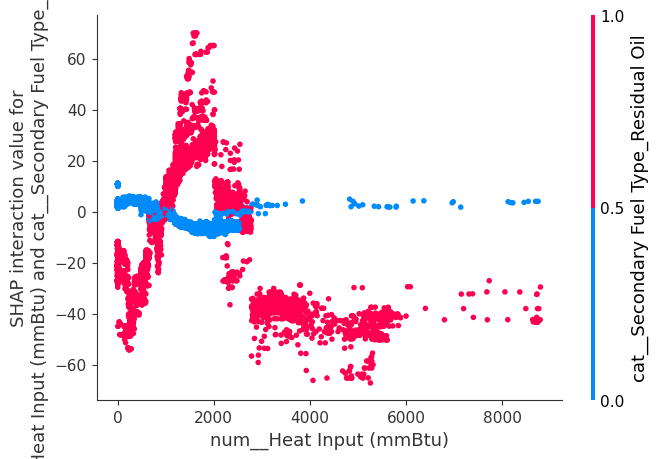

In [ ]:
shap.dependence_plot(("num__Heat Input (mmBtu)", "cat__Secondary Fuel Type_Residual Oil"), interaction_values_shap, X_test_sample, show=True)

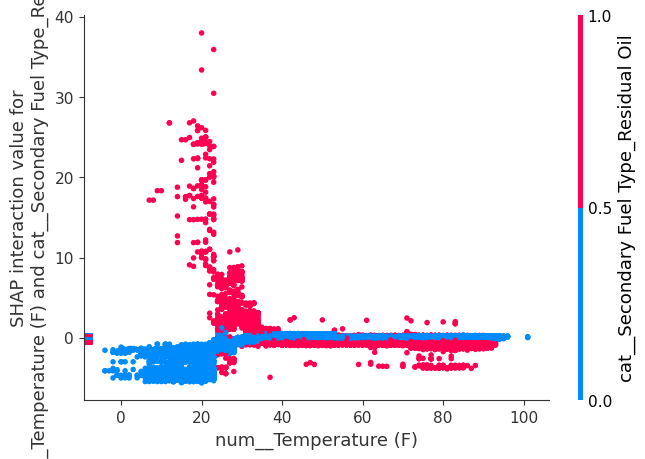

In [ ]:
shap.dependence_plot(("num__Temperature (F)", "cat__Secondary Fuel Type_Residual Oil"), interaction_values_shap, X_test_sample, show=True)

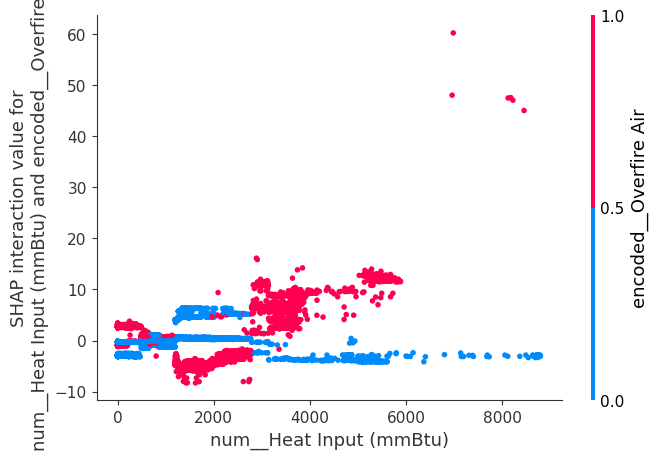

In [ ]:
shap.dependence_plot(("num__Heat Input (mmBtu)", "encoded__Overfire Air"), interaction_values_shap, X_test_sample)
# interaction values prove this

<h5>With Lags, No Temps</h5>

In [ ]:
explainer = shap.TreeExplainer(xgb_default_model)

In [ ]:
X_test = pd.read_csv("NY/Hourly/Concatted File/Modeling/XGB/X_test_processed", dtype=campd_type_dict)

In [ ]:
shap_values = explainer(X_test, approximate=False)

In [ ]:
joblib.dump(shap_values, "NY/Hourly/Concatted File/Modeling/XGB/Trained Models/shap_values_xgb_default_model_ny_with_lags_no_unmeasured.pkl")

['NY/Hourly/Concatted File/Modeling/XGB/Trained Models/shap_values_xgb_default_model_ny_with_lags_no_unmeasured.pkl']

In [ ]:
shap_values = joblib.load("NY/Hourly/Concatted File/Modeling/XGB/Trained Models/shap_values_xgb_default_model_ny_with_lags_no_unmeasured.pkl")

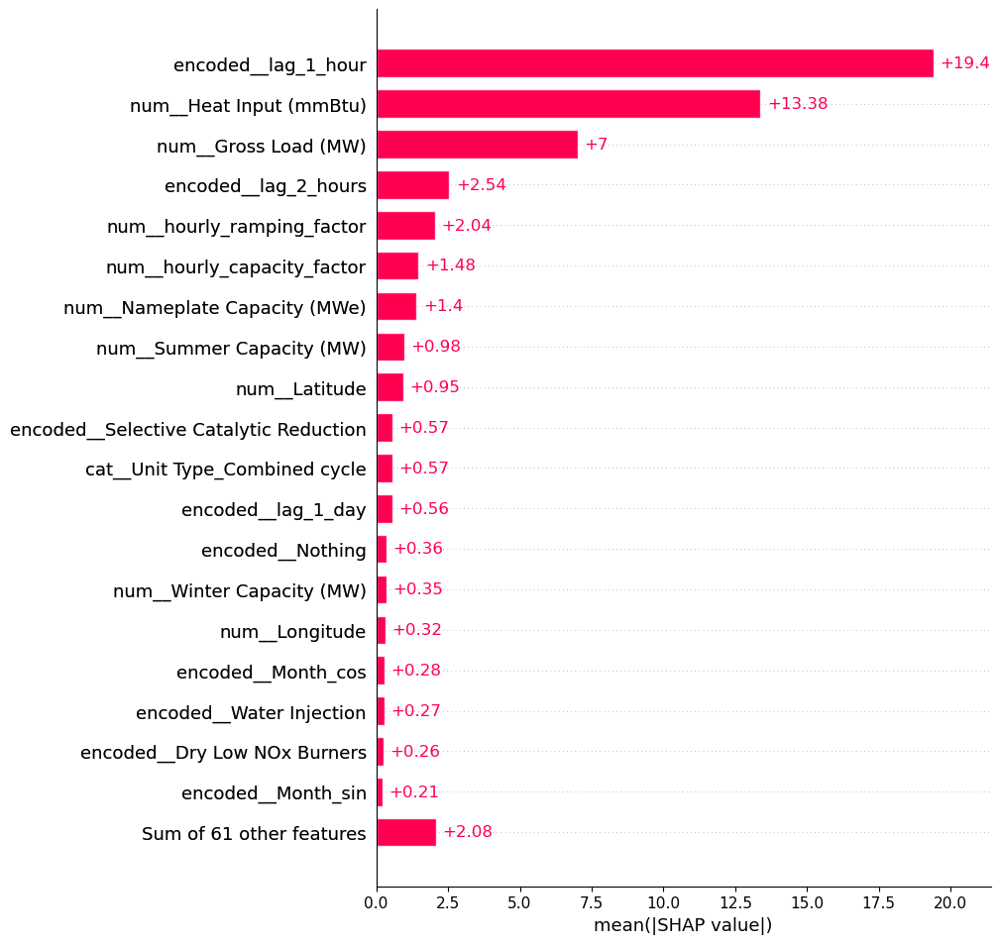

In [ ]:
shap.plots.bar(shap_values, max_display=20)

<h4>Using HPO parameters</h4>

In [4]:
explainer = shap.TreeExplainer(xgb_hpo_model)

In [5]:
X_test = pd.read_csv("NY/Hourly/Concatted File/Modeling/XGB/X_test_processed", dtype=campd_type_dict)

In [6]:
shap_values = explainer(X_test, approximate=True) # need to approximate because otherwise it is to computationally expensive for the hpo model

In [7]:
joblib.dump(shap_values, "NY/Hourly/Concatted File/Modeling/XGB/Trained Models/shap_values_xgb_hpo_model_ny_with_lags_no_unmeasured.pkl")

['NY/Hourly/Concatted File/Modeling/XGB/Trained Models/shap_values_xgb_hpo_model_ny_with_lags_no_unmeasured.pkl']

In [ ]:
shap_values = joblib.load("NY/Hourly/Concatted File/Modeling/XGB/Trained Models/shap_values_xgb_hpo_model_ny_with_lags_no_unmeasured.pkl")

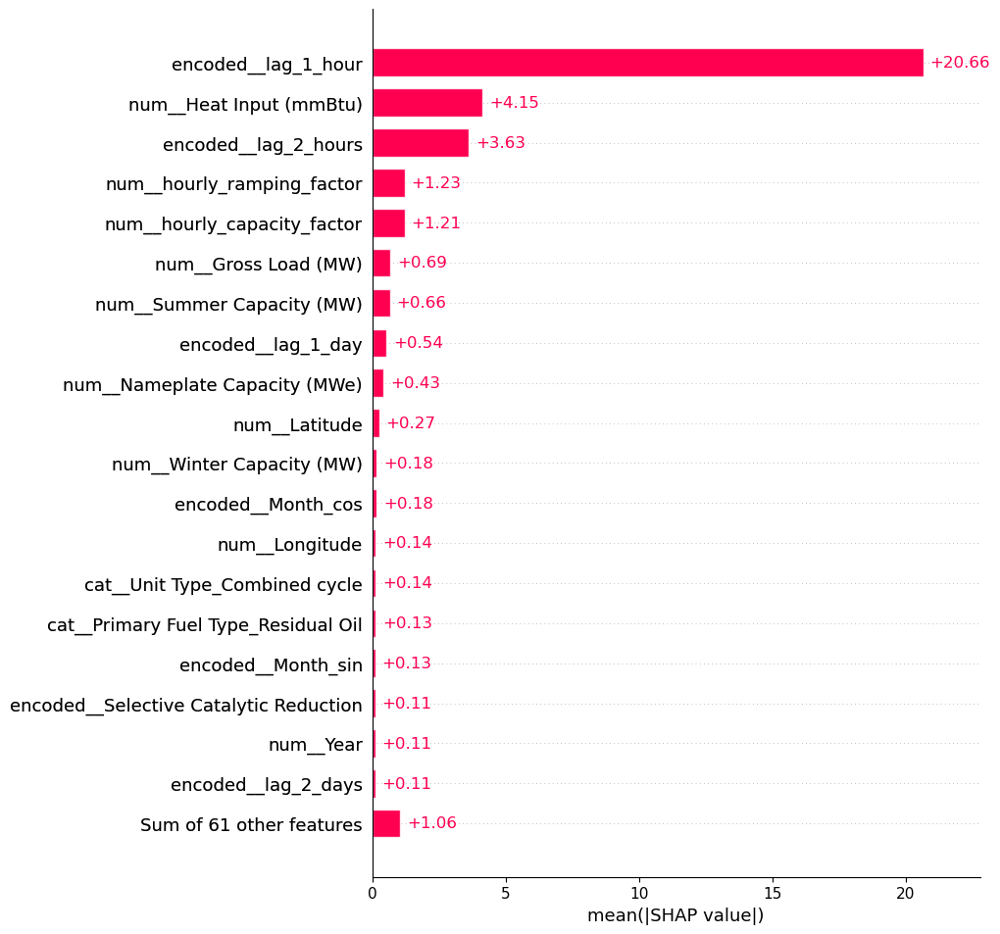

In [8]:
shap.plots.bar(shap_values, max_display=20)

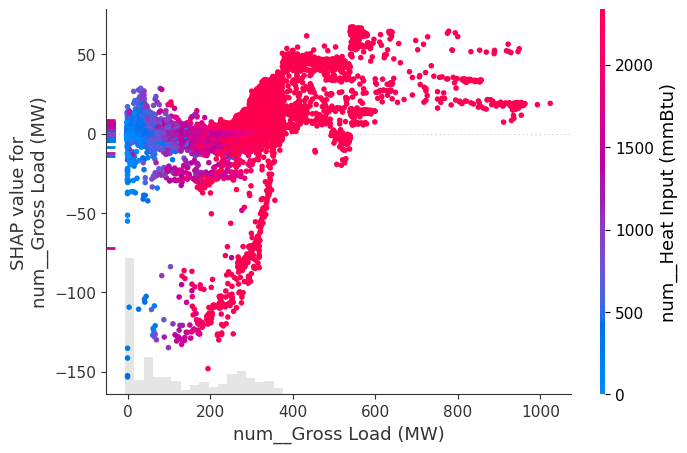

In [9]:
shap.plots.scatter(shap_values[:,"num__Gross Load (MW)"], color=shap_values[:,"num__Heat Input (mmBtu)"])


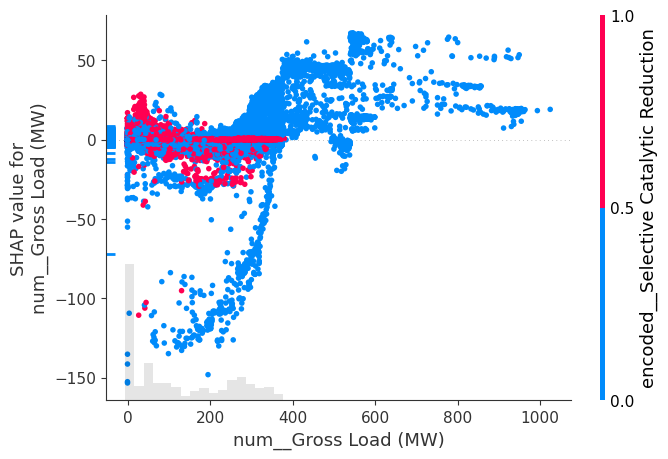

In [10]:
shap.plots.scatter(shap_values[:,"num__Gross Load (MW)"], color=shap_values[:,"encoded__Selective Catalytic Reduction"])


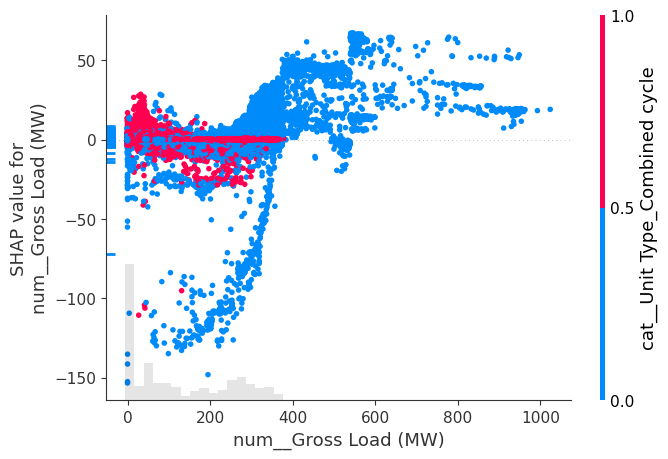

In [11]:
shap.plots.scatter(shap_values[:,"num__Gross Load (MW)"], color=shap_values[:,"cat__Unit Type_Combined cycle"])  


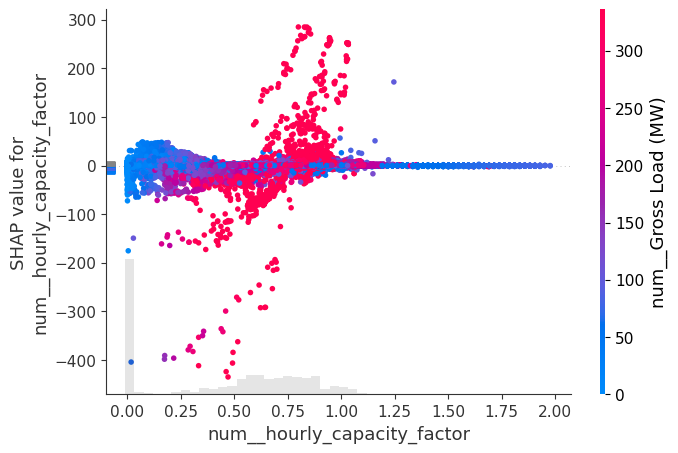

In [12]:
shap.plots.scatter(shap_values[:,"num__hourly_capacity_factor"], color=shap_values[:,"num__Gross Load (MW)"])


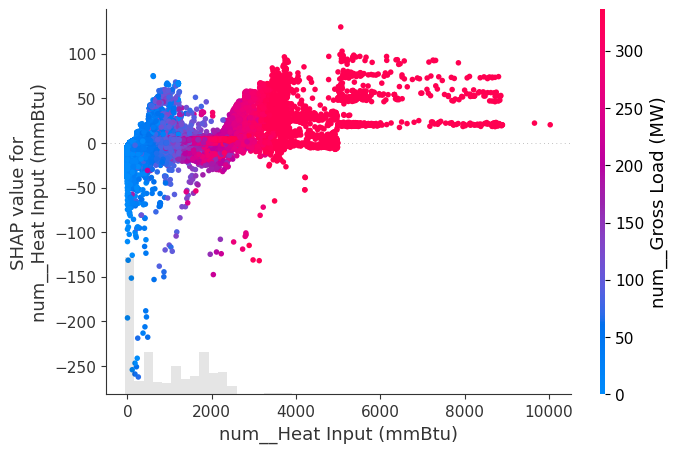

In [13]:
shap.plots.scatter(shap_values[:,"num__Heat Input (mmBtu)"], color=shap_values[:,"num__Gross Load (MW)"])


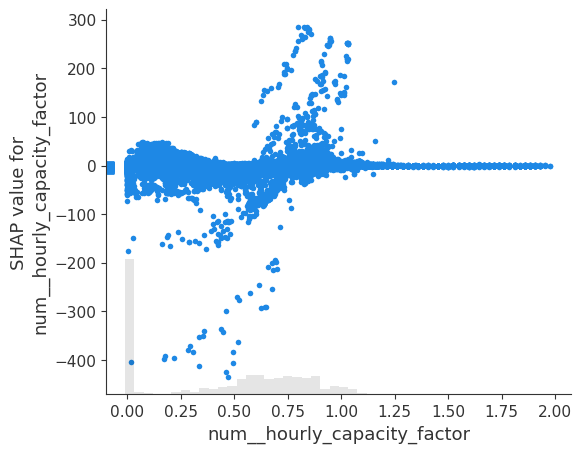

In [14]:
shap.plots.scatter(shap_values[:,"num__hourly_capacity_factor"])#, color=shap_values[:,"encoded__Selective Catalytic Reduction"])


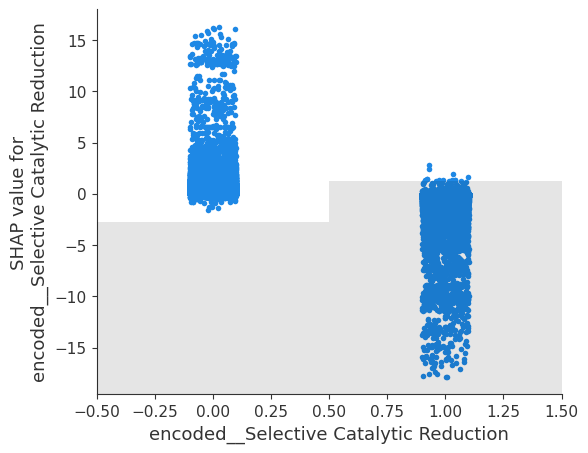

In [15]:
shap.plots.scatter(shap_values[:,"encoded__Selective Catalytic Reduction"])


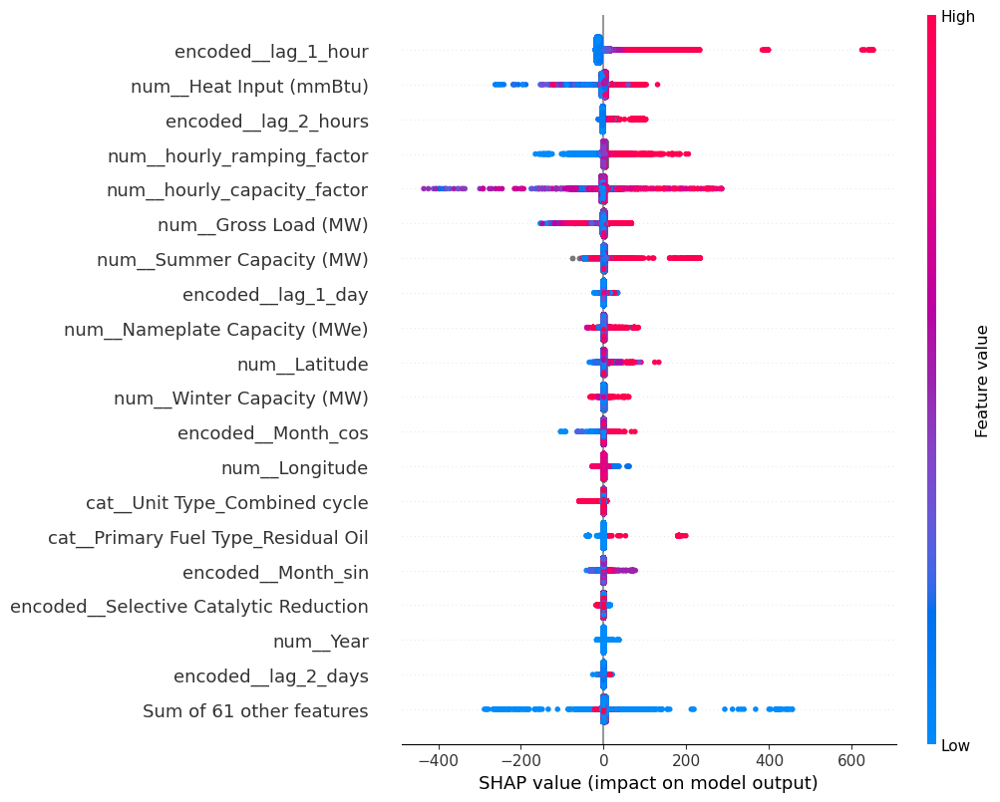

In [16]:
shap.plots.beeswarm(shap_values, max_display=20)


In [17]:
# define feature groups (important for aggregation of encoded cols)
feature_groups = {
    "Source Category": [
        'cat__Source Category_Cogeneration',
        'cat__Source Category_Electric Utility',
        'cat__Source Category_Missing'
    ],
    
    "NOx Phase": [
        'cat__NOx Phase_Early Election',
        'cat__NOx Phase_Nothing',
        'cat__NOx Phase_Phase 1 Group 1',
        'cat__NOx Phase_Phase 2 Group 1'
    ],
    
    "Unit Type": [
        'cat__Unit Type_Circulating fluidized bed boiler',
        'cat__Unit Type_Combined cycle',
        'cat__Unit Type_Combined cycle (Started Feb 23, 2020)',
        'cat__Unit Type_Combustion turbine',
        'cat__Unit Type_Dry bottom wall-fired boiler',
        'cat__Unit Type_Other boiler',
        'cat__Unit Type_Tangentially-fired'
    ],
    
    "Primary Fuel Type": [
        'cat__Primary Fuel Type_Coal',
        'cat__Primary Fuel Type_Diesel Oil',
        'cat__Primary Fuel Type_Natural Gas',
        'cat__Primary Fuel Type_Other Oil',
        'cat__Primary Fuel Type_Pipeline Natural Gas',
        'cat__Primary Fuel Type_Residual Oil',
        'cat__Primary Fuel Type_Wood'
    ],
    
    "Secondary Fuel Type": [
        'cat__Secondary Fuel Type_Diesel Oil',
        'cat__Secondary Fuel Type_Natural Gas, Wood',
        'cat__Secondary Fuel Type_Nothing',
        'cat__Secondary Fuel Type_Other Oil',
        'cat__Secondary Fuel Type_Other Solid Fuel, Petroleum Coke, Tire Derived Fuel',
        'cat__Secondary Fuel Type_Pipeline Natural Gas',
        'cat__Secondary Fuel Type_Residual Oil',
        'cat__Secondary Fuel Type_Wood'
    ],

    "Gross Load (MW)": ['num__Gross Load (MW)'],
    "Heat Input (mmBtu)": ['num__Heat Input (mmBtu)'],
    "Latitude": ['num__Latitude'],
    "Longitude": ['num__Longitude'],
    "Nameplate Capacity (MWe)": ['num__Nameplate Capacity (MWe)'],
    "hourly_capacity_factor": ['num__hourly_capacity_factor'],
    "hourly_ramping_factor": ['num__hourly_ramping_factor'],
    "Summer Capacity (MW)": ['num__Summer Capacity (MW)'],
    "Winter Capacity (MW)": ['num__Winter Capacity (MW)'],
    "Minimum Load (MW)": ['num__Minimum Load (MW)'],
    "Year": ['num__Year'],

    "Control Technologies": [
        'encoded__Ammonia Injection',
        'encoded__Combustion Modification/Fuel Reburning',
        'encoded__Dry Low NOx Burners',
        'encoded__Low NOx Burner Technology (Dry Bottom only)',
        'encoded__Low NOx Burner Technology w/ Closed-coupled OFA',
        'encoded__Low NOx Burner Technology w/ Closed-coupled/Separated OFA',
        'encoded__Low NOx Burner Technology w/ Overfire Air',
        'encoded__Low NOx Burner Technology w/ Separated OFA',
        'encoded__Nothing',
        'encoded__Other',
        'encoded__Overfire Air',
        'encoded__Selective Catalytic Reduction',
        'encoded__Selective Non-catalytic Reduction',
        'encoded__Steam Injection',
        'encoded__Water Injection',
        'encoded__Water Injection (Began Jul 01, 2022)'
    ],

    "Programs / Regulations": [
        'encoded__ARP',
        'encoded__CSNOX',
        'encoded__CSOSG2',
        'encoded__CSOSG2E',
        'encoded__CSOSG3',
        'encoded__CSSO2G1',
        'encoded__MATS',
        'encoded__Missing',
        'encoded__NSPS4T',
        'encoded__RGGI',
        'encoded__SIPNOX'
    ],

    "Hour": [
        'encoded__Hour_sin',
        'encoded__Hour_cos'
    ],
    "Day": [
        'encoded__Day_sin',
        'encoded__Day_cos'
    ],
    "Month": [
        'encoded__Month_sin',
        'encoded__Month_cos'
    ],

    "Lag Features": [
        'encoded__lag_1_hour',
        'encoded__lag_2_hours',
        'encoded__lag_1_day',
        'encoded__lag_2_days',
        'encoded__lag_1_week',
        'encoded__lag_1_month',
        'encoded__lag_1_year'
    ]
}

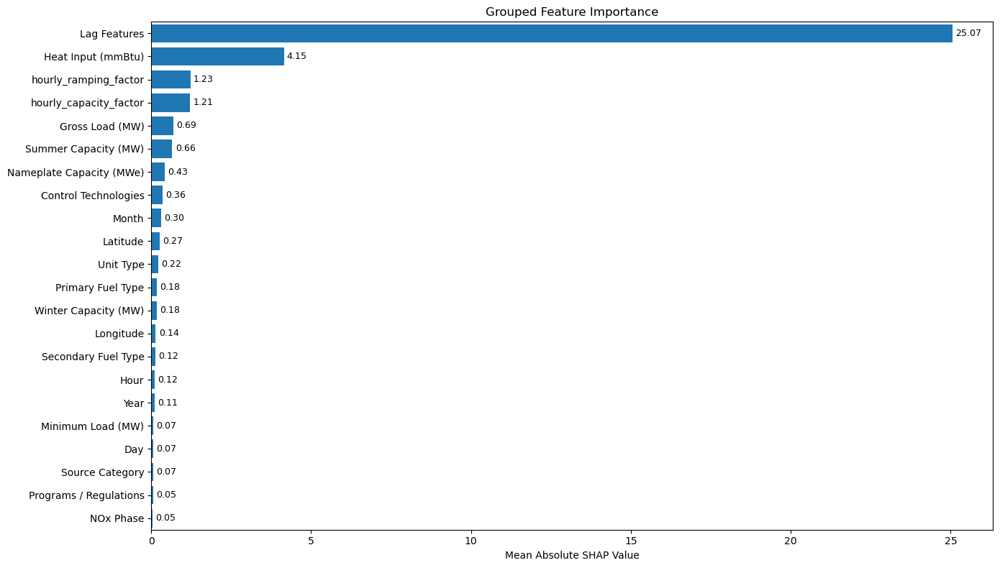

In [18]:
# Aggregate (sum) the shap values of encoded columns

# create series of mean absolute SHAP values per feature (using feature name as index)
mean_abs_shap = np.abs(shap_values.values).mean(axis=0) 
shap_importance = pd.Series(mean_abs_shap, index=shap_values.feature_names)

# aggregate by feature groups (sum the mean absolute values within pre-defined groups)
group_importance = {}
for group, features in feature_groups.items():
    group_importance[group] = shap_importance[features].sum() 

group_importance = pd.Series(group_importance).sort_values(ascending=False)

# plot
fig, ax = plt.subplots(figsize=(14, 8))
bars = ax.barh(group_importance.index, group_importance.values)
group_importance.plot(kind='barh')
ax.bar_label(bars, fmt='%.2f', label_type='edge', padding=3, fontsize=9) # add bar labels
plt.gca().invert_yaxis()  # invert to get largest at top
plt.title('Grouped Feature Importance')
plt.xlabel('Mean Absolute SHAP Value')
plt.tight_layout()
plt.show()


<h3>LIME</h3>

In [35]:
regressor = XGBRegressor()
regressor._Booster = xgb_default_model_no_lags

# Initialize the LIME explainer
lime_explainer = LimeTabularExplainer(
    training_data=np.array(X_train),
    feature_names=X_train.columns.tolist(),
    mode='regression',
    discretize_continuous=False # need to do this since there are features in X_train and X_test with an std of 0 (consistent val)
)


In [ ]:
row = X_test.iloc[48384]

print(row[row.isna()])

# Fill nans in the row with median values (LIME cant handle nans)
row_filled = row.fillna(0)

lime_sample = row_filled.values

exp = lime_explainer.explain_instance(
    data_row=lime_sample,
    predict_fn=regressor.predict
)

exp.show_in_notebook(show_table=True)

num__Summer Capacity (MW)   NaN
num__Winter Capacity (MW)   NaN
num__Minimum Load (MW)      NaN
Name: 1720231, dtype: float64


In [ ]:
# Save LIME explanation to an HTML file
with open('lime_explanation.html', 'w', encoding='utf-8') as f:
    f.write(exp.as_html())


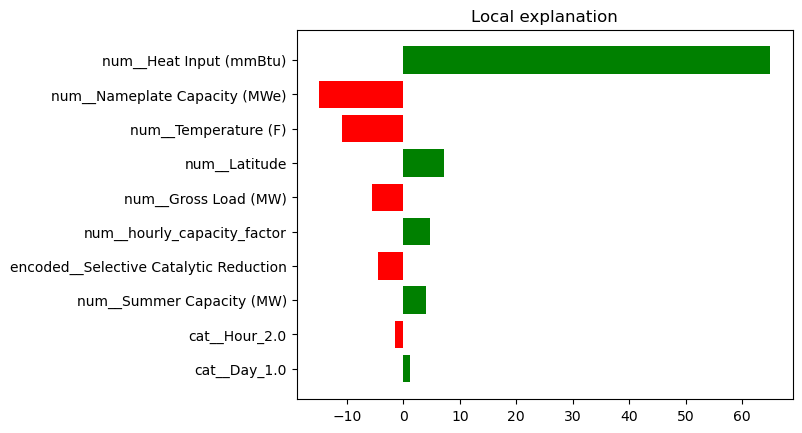

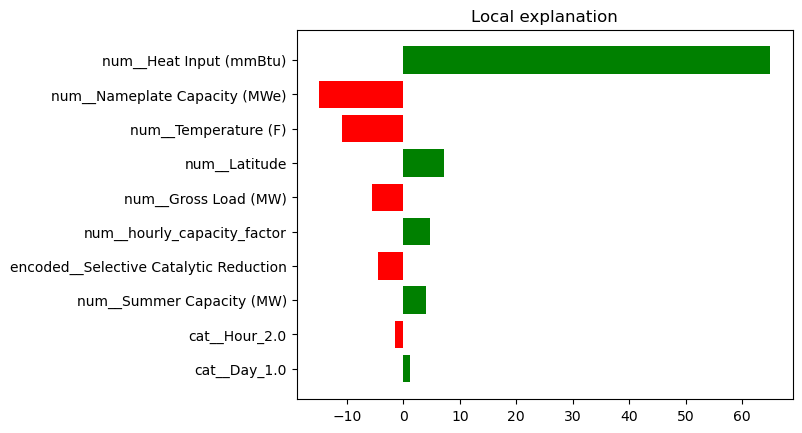

In [ ]:
exp.as_pyplot_figure()

In [ ]:
exp = lime_explainer.explain_instance(
    data_row=X_test.iloc[482881].values,
    predict_fn=regressor.predict
)

exp.show_in_notebook(show_table=True)

In [ ]:
# aggregate LIME

from collections import defaultdict # use to automatically add a new key with empty list if key does not exist yet

feature_weights = defaultdict(list)

X_test_sample = X_test.sample(frac=0.1, random_state=42)
print(len(X_test_sample))

for i in range(len(X_test_sample)):
    row = X_test_sample.iloc[i]

    medians = X_test_sample.median()
    # Fill any nans in the row with median values
    row_filled = row.fillna(medians)

    exp = lime_explainer.explain_instance(
        data_row=row_filled.values,
        predict_fn=regressor.predict
    )
    for feature, weight in exp.as_list():
        feature_weights[feature].append(abs(weight))

global_importance = pd.DataFrame([
    (feat, np.mean(weights)) for feat, weights in feature_weights.items()
], columns=['Feature', 'Avg_Abs_Weight'])

global_importance = global_importance.sort_values(by='Avg_Abs_Weight', ascending=False)


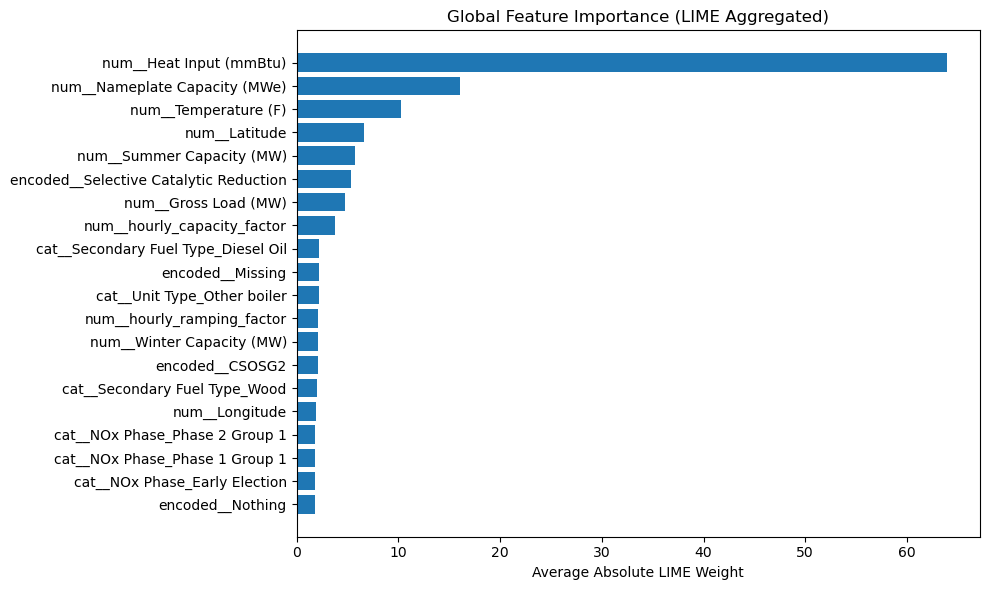

In [ ]:
plt.figure(figsize=(10, 6))
plt.barh(global_importance['Feature'].head(20), global_importance['Avg_Abs_Weight'].head(20))
plt.xlabel("Average Absolute LIME Weight")
plt.title("Global Feature Importance (LIME Aggregated)")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

# particularly interesting is that Secondary Fuel Type Residual Oil is not present here at all

<h3>Tests/Comparisons</h3>

In [ ]:
shap_explainer = shap.TreeExplainer(xgb_default_model_no_lags)

In [ ]:
from tqdm import tqdm  # progress bar

# Randomly select n indices
np.random.seed(42)
sample_indices = np.random.choice(X_test.index, size=5000)

medians = X_test.median()

spearman_scores = {
    20: [],
    10: [],
    5: [],
    3: []
}

overlap_scores = {
    20: [],
    10: [],
    5: [],
    3: []
}

mean_abs_rank_diff_scores = {
    20: [],
    10: [],
    5: [],
    3: []
}

normalized_mean_abs_rank_diff_scores = {
    20: [],
    10: [],
    5: [],
    3: []
}

top_1_agreement_count = {
    20: 0,
    10: 0,
    5: 0,
    3: 0
}
top_2_agreement_count = {
    20: 0,
    10: 0,
    5: 0,
    3: 0
}
top_3_agreement_count = {
    20: 0,
    10: 0,
    5: 0,
    3: 0
}

for idx in tqdm(sample_indices):
    try:
        # For fairness, we impute nan values with the median for all (LIME cannot deal with nans)
        row = X_test.loc[[idx]]
        imputed_sample = row.fillna(medians)

        # SHAP
        shap_values = shap_explainer(imputed_sample)
        values = shap_values.values[0]
        features = shap_values.data[0]
        feature_names = shap_values.feature_names
        shap_df = pd.DataFrame({
            'Feature': feature_names,
            'Feature Value': features,
            'SHAP Value': values,
            'Absolute SHAP': abs(values)
        })

        # LIME
        exp = lime_explainer.explain_instance(
            data_row=imputed_sample.iloc[0].values,
            predict_fn=regressor.predict,
            num_features=20
        )
        lime_explanation = exp.as_list()

        for k in [20, 10, 5, 3]:
            top_lime_features = [feature for feature, _ in lime_explanation[:k]]
            lime_ranks = {feature: rank for rank, feature in enumerate(top_lime_features)}
            top_shap_features = shap_df.sort_values(by='Absolute SHAP', ascending=False).head(k)['Feature'].tolist()
            shap_ranks = {feature: rank for rank, feature in enumerate(top_shap_features)}

            common_features = list(set(top_shap_features) & set(top_lime_features))
            overlap = len(common_features) / k
            overlap_scores[k].append((idx, overlap)) # add idx to find the row later

            if len(common_features) >= 1:
                abs_rank_diffs = [np.abs(lime_ranks[feat] - shap_ranks[feat]) for feat in common_features]
                mean_abs_rank_diff_scores[k].append(np.mean(abs_rank_diffs))
                
                # also normalize by the maximum possible distance
                normalized_abs_rank_diffs = [(np.abs(lime_ranks[feat] - shap_ranks[feat])) / (k - 1) for feat in common_features]
                normalized_mean_abs_rank_diff_scores[k].append(np.mean(normalized_abs_rank_diffs))

            # Only calculate Spearman if there is overlap with at least two features
            if len(common_features) >= 2:
                shap_rank_list = [shap_ranks[feat] for feat in common_features]
                lime_rank_list = [lime_ranks[feat] for feat in common_features]
                correlation, _ = spearmanr(shap_rank_list, lime_rank_list)
                spearman_scores[k].append(correlation)

            if top_lime_features[0] == top_shap_features[0]:
                top_1_agreement_count[k] += 1
            if top_lime_features[1] == top_shap_features[1]:
                top_2_agreement_count[k] += 1
            if top_lime_features[2] == top_shap_features[2]:
                top_3_agreement_count[k] += 1

    except Exception as e:
        print(f"Error at index {idx}: {e}")
        continue

100%|██████████| 1000/1000 [01:20<00:00, 12.40it/s]


In [ ]:
print(top_1_agreement_count[3] / 5000)
print("")
print(top_2_agreement_count[3] / 5000)
print("")
print(top_3_agreement_count[3] / 5000)
print("")

0.717

0.088

0.073



In [212]:
# reminder that we only calculate the spearman correlation for >= 2 overlapping features !
# mean abs rank difference is calculate for >= 1 overlapping features
for k in [20, 10, 5, 3]:
    current_spearman_scores = np.array(spearman_scores[k])
    current_overlap_scores = np.array(overlap_scores[k])
    current_mean_abs_rank_diff_scores = np.array(mean_abs_rank_diff_scores[k])
    current_normalized_mean_abs_rank_diff_scores = np.array(normalized_mean_abs_rank_diff_scores[k])

    print(f"Top {k} Features")
    print(f"Overlap Score: Mean = {np.mean(current_overlap_scores[:, 1]):.3f}, Std = {np.std(current_overlap_scores[:, 1]):.3f}, N = {len(current_overlap_scores)}")
    print(f"Mean Absolute Rank Diff Score: Mean = {np.mean(current_mean_abs_rank_diff_scores):.3f}, Std = {np.std(current_mean_abs_rank_diff_scores):.3f}, N = {len(current_mean_abs_rank_diff_scores)}")
    print(f"Normalized Mean Absolute Rank Diff Score: Mean = {np.mean(current_normalized_mean_abs_rank_diff_scores):.3f}, Std = {np.std(current_normalized_mean_abs_rank_diff_scores):.3f}, N = {len(current_normalized_mean_abs_rank_diff_scores)}")
    print(f"Spearman Correlation: Mean = {np.mean(current_spearman_scores):.3f}, Std = {np.std(current_spearman_scores):.3f}, N = {len(current_spearman_scores)}")
    print("")

Top 20 Features
Overlap Score: Mean = 0.605, Std = 0.078, N = 5000
Mean Absolute Rank Diff Score: Mean = 4.285, Std = 1.023, N = 5000
Normalized Mean Absolute Rank Diff Score: Mean = 0.226, Std = 0.054, N = 5000
Spearman Correlation: Mean = 0.454, Std = 0.235, N = 5000

Top 10 Features
Overlap Score: Mean = 0.640, Std = 0.096, N = 5000
Mean Absolute Rank Diff Score: Mean = 2.518, Std = 0.702, N = 5000
Normalized Mean Absolute Rank Diff Score: Mean = 0.280, Std = 0.078, N = 5000
Spearman Correlation: Mean = 0.266, Std = 0.322, N = 5000

Top 5 Features
Overlap Score: Mean = 0.428, Std = 0.148, N = 5000
Mean Absolute Rank Diff Score: Mean = 0.796, Std = 0.788, N = 4992
Normalized Mean Absolute Rank Diff Score: Mean = 0.199, Std = 0.197, N = 4992
Spearman Correlation: Mean = 0.695, Std = 0.630, N = 4078

Top 3 Features
Overlap Score: Mean = 0.368, Std = 0.165, N = 5000
Mean Absolute Rank Diff Score: Mean = 0.243, Std = 0.492, N = 4644
Normalized Mean Absolute Rank Diff Score: Mean = 0.121,

In [180]:
X_test_adjusted_sample = X_test.fillna(medians)

In [ ]:
# look at instances where overlap is very low / distance very high / Spearman negative

In [ ]:
sorted(overlap_scores[5], key=lambda x: x[1])

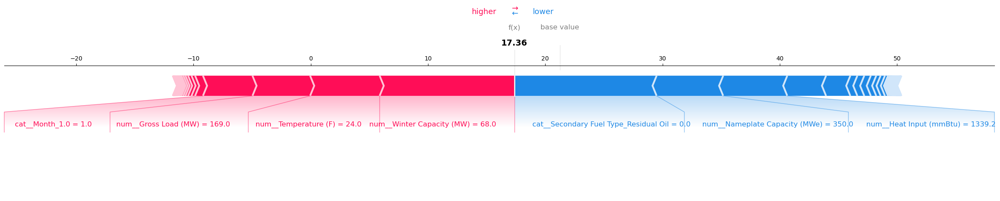

In [182]:
shap.plots.force(shap_explainer(X_test_adjusted_sample.loc[[2624710]]), matplotlib=True, contribution_threshold=0.1, figsize=(30,4))


In [ ]:
shap_values = shap_explainer(X_test_adjusted_sample.loc[[2624710]])
values = shap_values.values[0]
features = shap_values.data[0]
feature_names = shap_values.feature_names
shap_df = pd.DataFrame({
            'Feature': feature_names,
            'Feature Value': features,
            'SHAP Value': values,
            'Absolute SHAP': abs(values)
        })

shap_df.sort_values(by="Absolute SHAP", ascending=False).head(20).reset_index(drop=True)

,Feature,Feature Value,SHAP Value,Absolute SHAP
0,cat__Secondary Fuel Type_Residual Oil,0.000000,-12.137015,12.137015
1,num__Winter Capacity (MW),68.000000,11.480815,11.480815
2,num__Temperature (F),24.000000,5.928749,5.928749
3,num__Nameplate Capacity (MWe),350.000000,-5.675828,5.675828
4,num__Heat Input (mmBtu),1339.200000,-5.465010,5.465010
5,num__Gross Load (MW),169.000000,4.916363,4.916363
6,cat__Month_1.0,1.000000,4.220865,4.220865
7,encoded__Selective Catalytic Reduction,1.000000,-3.305704,3.305704
8,num__hourly_capacity_factor,0.482857,-2.070254,2.070254
9,encoded__Overfire Air,0.000000,0.670697,0.670697


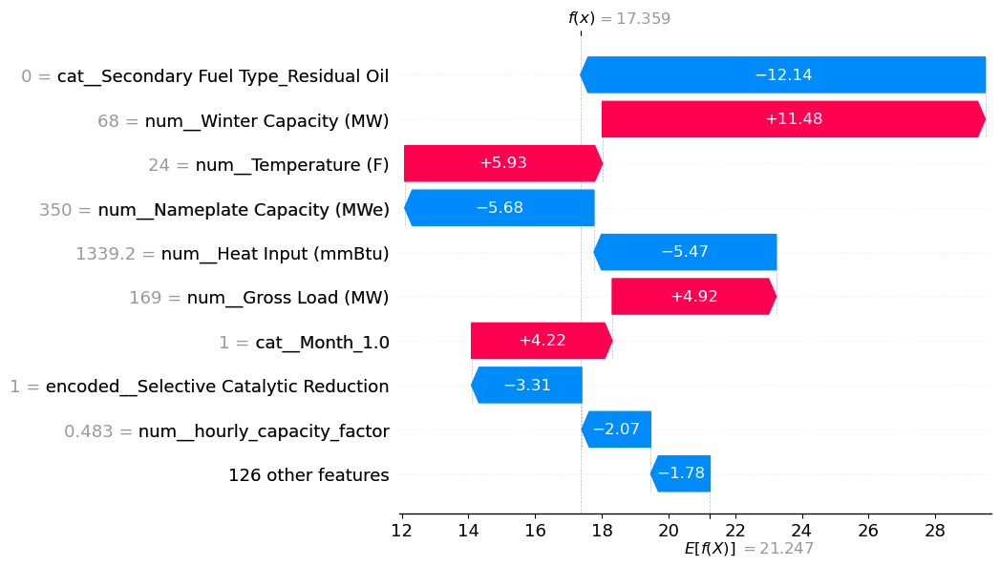

In [298]:
shap.plots.waterfall(shap_values[0], max_display=10)

In [275]:
# lime doesn't capture interactions so

# Explain the prediction
exp = lime_explainer.explain_instance(
    data_row=X_test_adjusted_sample.loc[2624710].values,
    predict_fn=regressor.predict,
    num_features=20
)

# Show explanation in notebook
exp.show_in_notebook(show_table=True)

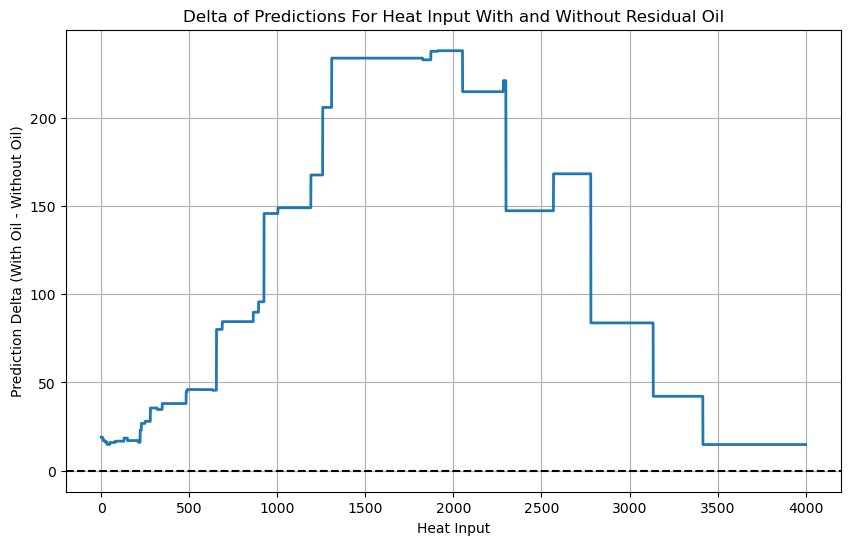

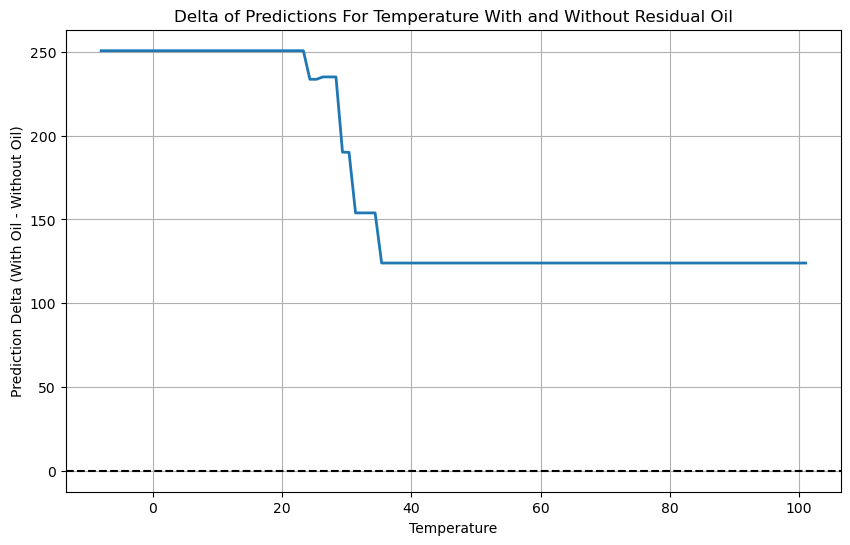

In [291]:
# makeshift custom pdp

base_idx = 2624710 
base_sample = X_test_adjusted_sample.loc[base_idx].copy()

# Define range to test for heat input
hi_values = np.linspace(0, 4000, 4000) 

results = []

for hi in hi_values:
    # Set temperature value
    perturbed_sample = base_sample.copy()
    perturbed_sample['num__Heat Input (mmBtu)'] = hi

    # Set Residual Oil 0
    perturbed_sample['cat__Secondary Fuel Type_Residual Oil'] = 0
    pred_no_oil = regressor.predict(perturbed_sample.values.reshape(1, -1))[0]

    # Set Residual Oil 1
    perturbed_sample['cat__Secondary Fuel Type_Residual Oil'] = 1
    pred_with_oil = regressor.predict(perturbed_sample.values.reshape(1, -1))[0]

    results.append({
        'Heat Input': hi,
        'Prediction_No_Oil': pred_no_oil,
        'Prediction_With_Oil': pred_with_oil,
        'Delta': pred_with_oil - pred_no_oil
    })

results_df = pd.DataFrame(results)

plt.figure(figsize=(10, 6))
plt.plot(results_df['Heat Input'], results_df['Delta'], linewidth=2)
plt.axhline(0, color='black', linestyle='--') # adds y=0 line to put magnitude into perspective
plt.title('Delta of Predictions For Heat Input With and Without Residual Oil')
plt.xlabel('Heat Input')
plt.ylabel('Prediction Delta (With Oil - Without Oil)')
plt.grid(True)
plt.show()

# with higher heat input, the impact of secondary fuel type residual oil rises
# up to a certain point at which its impact diminishes again


base_idx = 2624710 
base_sample = X_test_adjusted_sample.loc[base_idx].copy()

# Define temperature range to test
temperature_values = np.linspace(-8, 101, 109)  

results = []

for temp in temperature_values:
    # Set temperature value
    perturbed_sample = base_sample.copy()
    perturbed_sample['num__Temperature (F)'] = temp

    # Set Residual Oil 0
    perturbed_sample['cat__Secondary Fuel Type_Residual Oil'] = 0
    pred_no_oil = regressor.predict(perturbed_sample.values.reshape(1, -1))[0]

    # Set Residual Oil 1
    perturbed_sample['cat__Secondary Fuel Type_Residual Oil'] = 1
    pred_with_oil = regressor.predict(perturbed_sample.values.reshape(1, -1))[0]

    # Log
    results.append({
        'Temperature': temp,
        'Prediction_No_Oil': pred_no_oil,
        'Prediction_With_Oil': pred_with_oil,
        'Delta': pred_with_oil - pred_no_oil
    })

results_df = pd.DataFrame(results)

plt.figure(figsize=(10, 6))
plt.plot(results_df['Temperature'], results_df['Delta'], linewidth=2)
plt.axhline(0, color='black', linestyle='--')
plt.title('Delta of Predictions For Temperature With and Without Residual Oil')
plt.xlabel('Temperature')
plt.ylabel('Prediction Delta (With Oil - Without Oil)')
plt.grid(True)
plt.show()

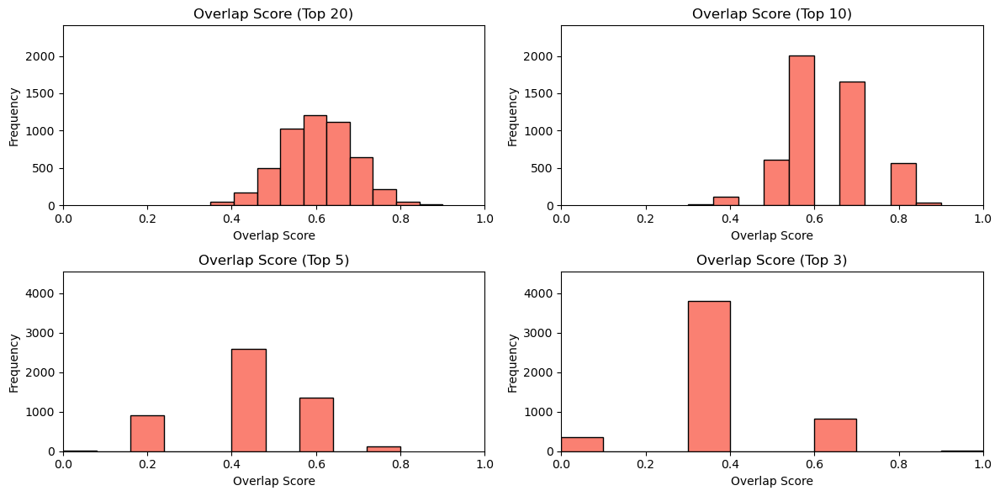

In [213]:

# Get all scores
scores_by_k = {k: [score[1] for score in overlap_scores[k]] for k in [20, 10, 5, 3]}

# Global x-axis limits
all_scores = [score for scores in scores_by_k.values() for score in scores]
xmin, xmax = min(all_scores), max(all_scores)

# Compute frequencies
row1_ys = [np.histogram(scores_by_k[k], bins=10)[0] for k in [20, 10]]
row2_ys = [np.histogram(scores_by_k[k], bins=10)[0] for k in [5, 3]]
ymax_row1 = max([max(h) for h in row1_ys])
ymax_row2 = max([max(h) for h in row2_ys])

plt.figure(figsize=(12, 6))
for i, k in enumerate([20, 10, 5, 3]):
    plt.subplot(2, 2, i+1)
    plt.xlim(xmin, xmax)

    # Apply row-specific y-axis limits
    if i < 2:
        plt.hist(scores_by_k[k], bins=10, color="salmon", edgecolor="black")
        plt.ylim(0, ymax_row1*1.2)
    else:
        plt.hist(scores_by_k[k], bins=10, color="salmon", edgecolor="black")
        plt.ylim(0, ymax_row2*1.2)

    plt.title(f"Overlap Score (Top {k})")
    plt.xlabel("Overlap Score")
    plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

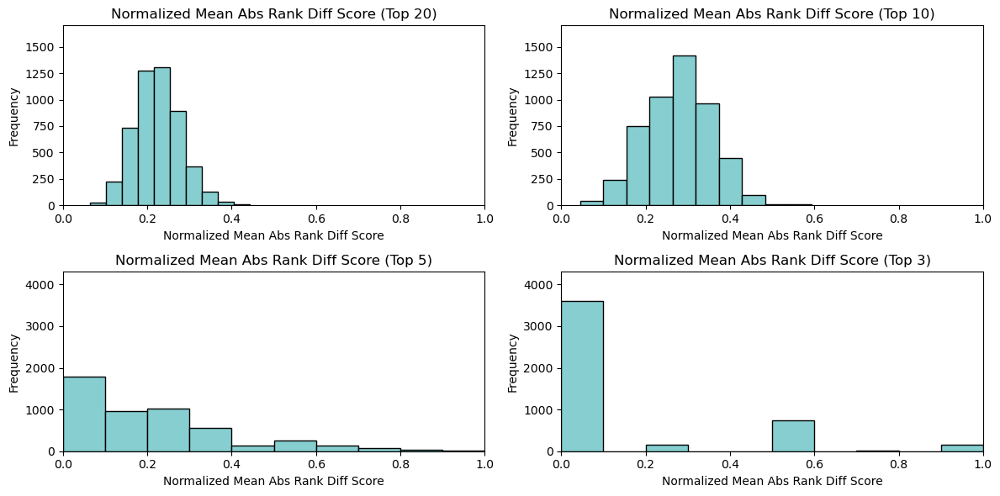

In [247]:

# Get all scores
scores_by_k = {k: [score for score in normalized_mean_abs_rank_diff_scores[k]] for k in [20, 10, 5, 3]}

# Global x-axis limits
all_scores = [score for scores in scores_by_k.values() for score in scores]
xmin, xmax = min(all_scores), max(all_scores)

# Compute frequencies
row1_ys = [np.histogram(scores_by_k[k], bins=10)[0] for k in [20, 10]]
row2_ys = [np.histogram(scores_by_k[k], bins=10)[0] for k in [5, 3]]
ymax_row1 = max([max(h) for h in row1_ys])
ymax_row2 = max([max(h) for h in row2_ys])

plt.figure(figsize=(12, 6))
for i, k in enumerate([20, 10, 5, 3]):
    plt.subplot(2, 2, i+1)
    plt.xlim(xmin, xmax)

    # Apply row-specific y-axis limits
    if i < 2:
        plt.hist(scores_by_k[k], bins=10, color="#86CED0", edgecolor="black")
        plt.ylim(0, ymax_row1*1.2)
    else:
        plt.hist(scores_by_k[k], bins=10, color="#86CED0", edgecolor="black")
        plt.ylim(0, ymax_row2*1.2)

    plt.title(f"Normalized Mean Abs Rank Diff Score (Top {k})")
    plt.xlabel("Normalized Mean Abs Rank Diff Score")
    plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

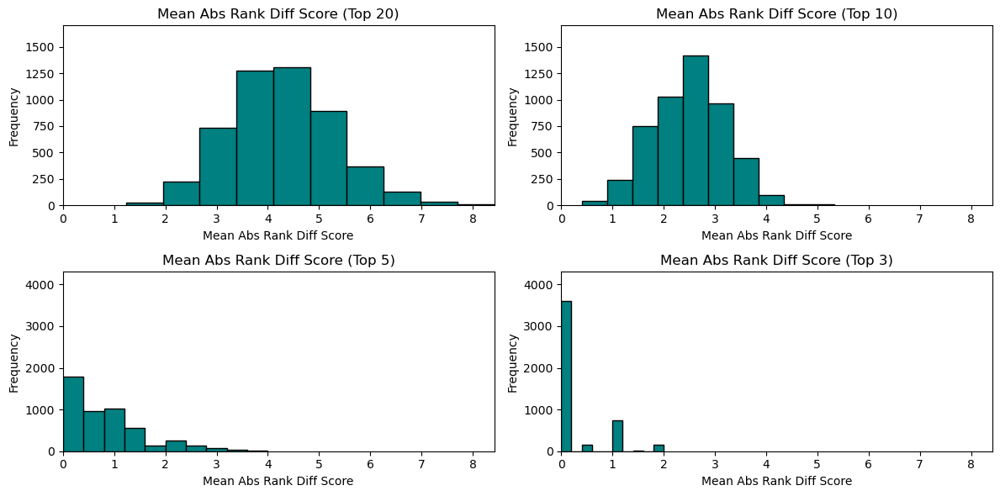

In [214]:

# Get all scores
scores_by_k = {k: [score for score in mean_abs_rank_diff_scores[k]] for k in [20, 10, 5, 3]}

# Global x-axis limits
all_scores = [score for scores in scores_by_k.values() for score in scores]
xmin, xmax = min(all_scores), max(all_scores)

# Compute frequencies
row1_ys = [np.histogram(scores_by_k[k], bins=10)[0] for k in [20, 10]]
row2_ys = [np.histogram(scores_by_k[k], bins=10)[0] for k in [5, 3]]
ymax_row1 = max([max(h) for h in row1_ys])
ymax_row2 = max([max(h) for h in row2_ys])

plt.figure(figsize=(12, 6))
for i, k in enumerate([20, 10, 5, 3]):
    plt.subplot(2, 2, i+1)
    plt.xlim(xmin, xmax)

    # Apply row-specific y-axis limits
    if i < 2:
        plt.hist(scores_by_k[k], bins=10, color="teal", edgecolor="black")
        plt.ylim(0, ymax_row1*1.2)
    else:
        plt.hist(scores_by_k[k], bins=10, color="teal", edgecolor="black")
        plt.ylim(0, ymax_row2*1.2)

    plt.title(f"Mean Abs Rank Diff Score (Top {k})")
    plt.xlabel("Mean Abs Rank Diff Score")
    plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

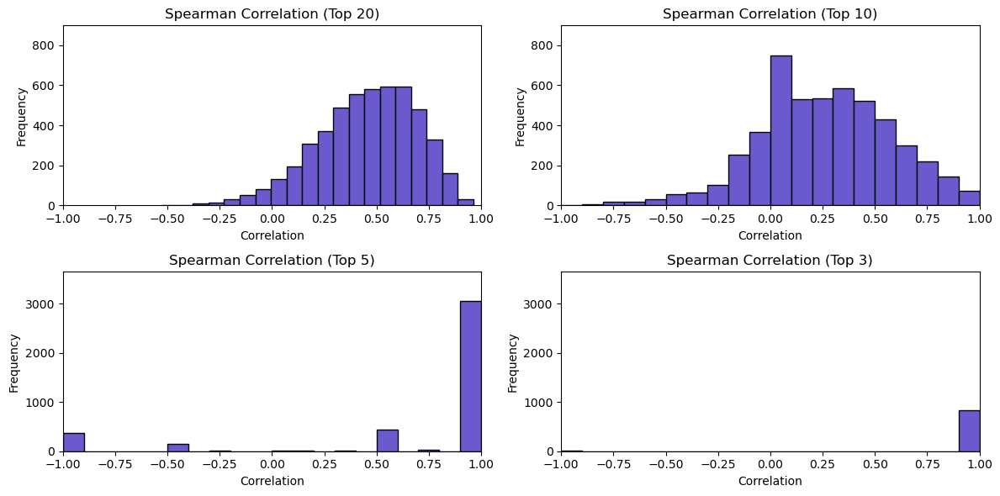

In [215]:
# Get all scores
scores_by_k = {k: [score for score in spearman_scores[k]] for k in [20, 10, 5, 3]}

# Row-wise ymax calculation
row1_ys = [np.histogram(scores_by_k[k], bins=20)[0] for k in [20, 10]]
row2_ys = [np.histogram(scores_by_k[k], bins=20)[0] for k in [5, 3]]
ymax_row1 = max([max(h) for h in row1_ys])
ymax_row2 = max([max(h) for h in row2_ys])

# Global x-axis limits
all_scores = [score for scores in scores_by_k.values() for score in scores]
xmin, xmax = min(all_scores), max(all_scores)

plt.figure(figsize=(12, 6))
for i, k in enumerate([20, 10, 5, 3]):
    plt.subplot(2, 2, i+1)
    plt.hist(scores_by_k[k], bins=20, color="slateblue", edgecolor="black")
    plt.xlim(xmin, xmax)
    
    # Apply row-specific y-axis limits
    if i < 2:
        plt.ylim(0, ymax_row1*1.2)
    else:
        plt.ylim(0, ymax_row2*1.2)
    
    plt.title(f"Spearman Correlation (Top {k})")
    plt.xlabel("Correlation")
    plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

In [ ]:
# spearman corr shows massive spikes at -1 and 1 for Top 5 and Top 3
# since most common feature sets at that level only consist of two features 
# which limits the correlation coefficient to -1 or 1